In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   85M  108G   1% /


In [1]:

from pathlib import Path
from collections import defaultdict

BTMD_DIR = Path("/content/BTMD")

sizes = defaultdict(int)
counts = defaultdict(int)

for p in BTMD_DIR.rglob("*"):
    if p.is_file():
        ext = p.suffix.lower() or "no extension"
        sizes[ext] += p.stat().st_size
        counts[ext] += 1

print("========== BTMD REPORT ==========")
print("Dataset exists:", BTMD_DIR.exists())
print("Total files:", sum(counts.values()))

for ext in sorted(sizes, key=sizes.get, reverse=True):
    print(
        f"{ext:15s} "
        f"Files: {counts[ext]:6d} "
        f"Size: {sizes[ext]/(1024**3):.2f} GB"
    )


========== BTMD REPORT ==========
Dataset exists: False
Total files: 0


In [2]:

import pandas as pd

metadata_path = Path("/content/BTMD/data/metadata.parquet")

print("Metadata exists:", metadata_path.exists())

if metadata_path.exists():
    df = pd.read_parquet(metadata_path)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nMissing values:")
    print(df.isnull().sum())


Metadata exists: False


In [3]:

from pathlib import Path

BTMD_DIR = Path("/content/BTMD")

print("BTMD exists:", BTMD_DIR.exists())
print("\nMain folders and files:")

for item in BTMD_DIR.iterdir():
    print(item.name, " [Folder]" if item.is_dir() else " [File]")

print("\nSearching for parquet files...")

parquet_files = list(BTMD_DIR.rglob("*.parquet"))

if parquet_files:
    for f in parquet_files:
        print("FOUND:", f)
else:
    print("No parquet files found!")


BTMD exists: False

Main folders and files:


FileNotFoundError: [Errno 2] No such file or directory: '/content/BTMD'

In [ ]:
!pip install -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 16.3 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   94M  108G   1% /


In [ ]:
from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="Faysal1000/BTMD",
    repo_type="dataset",
    local_dir="/content/BTMD",
    token=True
)

print("BTMD Dataset Download Completed!")
print("Saved at:", dataset_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5935 files:   0%|          | 0/5935 [00:00<?, ?it/s]

BTMD Dataset Download Completed!
Saved at: /content/BTMD


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed

In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os

locations = [
    "/content/BTMD",
    "/content/drive/MyDrive/BTMD"
]

for path in locations:
    print("\nLocation:", path)

    if os.path.exists(path):
        print("STATUS: FOUND ✅")
        print("Files:", os.listdir(path)[:10])
    else:
        print("STATUS: NOT FOUND ❌")


Location: /content/BTMD
STATUS: FOUND ✅
Files: ['images', '.cache', 'videos', 'README.md', 'data', '.gitattributes']

Location: /content/drive/MyDrive/BTMD
STATUS: NOT FOUND ❌


In [ ]:
import os

def get_folder_size(path):
    total = 0

    for root, dirs, files in os.walk(path):
        for file in files:
            filepath = os.path.join(root, file)

            if os.path.exists(filepath):
                total += os.path.getsize(filepath)

    return total

size = get_folder_size("/content/BTMD")

print("Dataset size:", round(size / (1024**3), 2), "GB")

Dataset size: 21.29 GB


In [ ]:
import os

for folder in ["images", "videos", "data"]:
    path = "/content/BTMD/" + folder

    if os.path.exists(path):
        print(folder, "exists")
        print("Items:", len(os.listdir(path)))
    else:
        print(folder, "not found")

images exists
Items: 4549
videos exists
Items: 1383
data exists
Items: 1


In [5]:
import os

data_path = "/content/BTMD/data"

for root, dirs, files in os.walk(data_path):
    for file in files:
        full_path = os.path.join(root, file)

        print("Filename:", file)
        print("File size:", round(os.path.getsize(full_path) / (1024**2), 2), "MB")

In [6]:

import os

print("Current directory:", os.getcwd())
print("\nContent directory:")

for item in os.listdir("/content"):
    path = os.path.join("/content", item)

    if os.path.isdir(path):
        print("📁", item)
    else:
        print("📄", item)


Current directory: /content

Content directory:
📁 .config
📁 sample_data


In [7]:

from google.colab import drive
drive.mount('/content/drive')

import os

print("\nMy Drive folders:")

for item in os.listdir('/content/drive/MyDrive'):
    print(item)


Mounted at /content/drive

My Drive folders:
TrustWalletBackup
project
Untitled form.gform
Colab Notebooks


In [8]:

import os

folders = [
    "/content/drive/MyDrive/project",
    "/content"
]

for folder in folders:
    print("\n==========", folder, "==========")

    for root, dirs, files in os.walk(folder):
        level = root.replace(folder, "").count(os.sep)

        if level > 2:
            dirs[:] = []
            continue

        indent = "  " * level
        print(indent + os.path.basename(root) + "/")

        for f in files[:10]:
            print(indent + "  " + f)



========== /content/drive/MyDrive/project ==========
project/

========== /content ==========
content/
  .config/
    active_config
    .last_survey_prompt.yaml
    config_sentinel
    .last_opt_in_prompt.yaml
    .last_update_check.json
    gce
    default_configs.db
    hidden_gcloud_config_universe_descriptor_data_cache_configs.db
    configurations/
      config_default
    logs/
  drive/
    .shortcut-targets-by-id/
    MyDrive/
      Untitled form.gform
    .Trash-0/
    .Encrypted/
  sample_data/
    README.md
    anscombe.json
    mnist_test.csv
    california_housing_train.csv
    california_housing_test.csv
    mnist_train_small.csv


In [9]:

import shutil

total, used, free = shutil.disk_usage("/content")

print(f"Total storage: {total / 1024**3:.2f} GB")
print(f"Used storage: {used / 1024**3:.2f} GB")
print(f"Free storage: {free / 1024**3:.2f} GB")


Total storage: 107.72 GB
Used storage: 0.08 GB
Free storage: 107.61 GB


In [10]:

!pip install -q -U huggingface_hub

from huggingface_hub import notebook_login

notebook_login()


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [11]:

from huggingface_hub import HfApi

api = HfApi()

info = api.dataset_info("Faysal1000/BTMD")

print("Dataset:", info.id)
print("Access:", "SUCCESS")
print("Dataset access confirmed!")


Dataset: Faysal1000/BTMD
Access: SUCCESS
Dataset access confirmed!


In [12]:

from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_files(
    repo_id="Faysal1000/BTMD",
    repo_type="dataset"
)

print("Total repository files:", len(files))
print("\nFirst 50 files:")

for f in files[:50]:
    print(f)


Total repository files: 5935

First 50 files:
.gitattributes
README.md
data/metadata.parquet
images/Fake_00001_471c8bb7-480d-4992-acfc-9c14dec632f5.png
images/Fake_00001_7e22017e-bc25-41ca-9557-8867a5fb31bc.png
images/Fake_00001_db2d024d-96e7-4f71-9eb2-371fc6d74c79.png
images/Fake_00002_7c8dd34c-5ae9-4b79-98f2-764deb54894e.png
images/Fake_00002_bbf90670-7309-4411-a8b1-60c4648ae8fd.png
images/Fake_00002_ca5a0688-bbb9-4e43-8cd9-370386e7bcbb.png
images/Fake_00003_23e516e8-6bfc-41da-864d-d67cd2d44799.png
images/Fake_00003_25a54365-23ab-4823-b533-3e05f7bb6790.png
images/Fake_00003_b4e23741-c17c-45b5-adcd-ee7d97b53e26.png
images/Fake_00003_b8f65c0a-6fe4-4ca6-902a-45dc7fca03b9.jpg
images/Fake_00004_1099e57b-f40b-4a21-acbd-489abe7203af.jpg
images/Fake_00004_cea14a70-41db-4dfb-b461-adc8e36d2257.png
images/Fake_00004_f549146e-ea3d-44d8-ad26-80a7f084891d.png
images/Fake_00004_f5ba3d4b-5dc0-4c87-9831-60714fa0e786.png
images/Fake_00005_a6012ae4-89d6-462a-a8b0-631745d45f37.png
images/Fake_00005_dbb8

In [13]:

!pip install -q -U huggingface_hub

from huggingface_hub import snapshot_download

dataset_path = snapshot_download(
    repo_id="Faysal1000/BTMD",
    repo_type="dataset",
    local_dir="/content/BTMD",
    resume_download=True
)

print("\nDownload completed!")
print("Dataset location:", dataset_path)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:189: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5935 files:   0%|          | 0/5935 [00:00<?, ?it/s]


Download completed!
Dataset location: /content/BTMD


In [14]:

from pathlib import Path

BTMD_DIR = Path("/content/BTMD")

print("Dataset exists:", BTMD_DIR.exists())

all_files = [p for p in BTMD_DIR.rglob("*") if p.is_file()]

images = [p for p in all_files if p.suffix.lower() in
          [".jpg", ".jpeg", ".png", ".webp"]]

videos = [p for p in all_files if p.suffix.lower() in
          [".mp4", ".avi", ".mov", ".mkv"]]

parquet = list(BTMD_DIR.rglob("*.parquet"))

print("Total files:", len(all_files))
print("Images:", len(images))
print("Videos:", len(videos))
print("Parquet files:", [str(p) for p in parquet])


Dataset exists: True
Total files: 17808
Images: 4549
Videos: 1383
Parquet files: ['/content/BTMD/data/metadata.parquet']


In [15]:
import pandas as pd

# Load metadata
metadata_path = "/content/BTMD/data/metadata.parquet"
df = pd.read_parquet(metadata_path)

# Basic information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nColumn data types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nUnique values in each column:")
for col in df.columns:
    print(f"\n{col}:")
    print("Unique values:", df[col].nunique())
    if df[col].nunique() <= 30:
        print(df[col].value_counts(dropna=False))

Dataset shape: (6058, 9)

Column names:
['id', 'heading', 'text', 'image_path', 'video_path', 'label', 'multi_category', 'source_category', 'category']

Column data types:
id                 object
heading            object
text               object
image_path         object
video_path         object
label              object
multi_category     object
source_category    object
category           object
dtype: object

First 5 rows:


,id,heading,text,image_path,video_path,label,multi_category,source_category,category
0,db2d024d-96e7-4f71-9eb2-371fc6d74c79,None,None,images/Fake_00001_db2d024d-96e7-4f71-9eb2-371f...,None,Fake,Misinformation,Facebook,Politics
1,7c8dd34c-5ae9-4b79-98f2-764deb54894e,কর্ণফুলী টানেলের কোনো প্রয়োজন ছিল না : প্রধান...,None,images/Fake_00002_7c8dd34c-5ae9-4b79-98f2-764d...,None,Fake,Misinformation,News Channel,Politics
2,23e516e8-6bfc-41da-864d-d67cd2d44799,আলোচিত রামিসার বাবাকে ১০ লক্ষ টা'কা চেক দিলেন ...,None,images/Fake_00003_23e516e8-6bfc-41da-864d-d67c...,None,Fake,Clickbait,Facebook,Politics
3,cea14a70-41db-4dfb-b461-adc8e36d2257,None,None,images/Fake_00004_cea14a70-41db-4dfb-b461-adc8...,None,Fake,Misinformation,Facebook,Politics
4,dbb8a4b3-6c7e-48b3-b4b0-f873a2ee18f2,None,None,images/Fake_00005_dbb8a4b3-6c7e-48b3-b4b0-f873...,None,Fake,Misinformation,Facebook,Politics



Missing values:
id                    0
heading            2507
text               3377
image_path         1769
video_path         4675
label                 0
multi_category        0
source_category       0
category              0
dtype: int64

Unique values in each column:

id:
Unique values: 6058

heading:
Unique values: 3546

text:
Unique values: 2681

image_path:
Unique values: 4289

video_path:
Unique values: 1383

label:
Unique values: 2
label
Fake    3029
Real    3029
Name: count, dtype: int64

multi_category:
Unique values: 4
multi_category
Real              3029
Misinformation    1859
Satire             594
Clickbait          576
Name: count, dtype: int64

source_category:
Unique values: 10
source_category
Facebook         3627
YouTube           831
Website           589
Newspaper         532
News Channel      274
Miscellaneous      97
Tiktok             55
Twitter            37
Instagram          14
Blog                2
Name: count, dtype: int64

category:
Unique values: 1

In [16]:
import pandas as pd

df = pd.read_parquet('/content/BTMD/data/metadata.parquet')

print("Image path example:")
print(df['image_path'].dropna().head(3).tolist())

print("\nVideo path example:")
print(df['video_path'].dropna().head(3).tolist())

Image path example:
['images/Fake_00001_db2d024d-96e7-4f71-9eb2-371fc6d74c79.png', 'images/Fake_00002_7c8dd34c-5ae9-4b79-98f2-764deb54894e.png', 'images/Fake_00003_23e516e8-6bfc-41da-864d-d67cd2d44799.png']

Video path example:
['videos/Fake_00001_c1168c6c-d411-4f12-95ff-ffdcc3529ca1.mp4', 'videos/Fake_00002_1ec95d89-7463-4f94-a960-d6f2576143cf.mp4', 'videos/Fake_00003_09d3ee49-c52d-483b-a193-295819209553.mp4']


In [17]:
import os
import pandas as pd

BTMD_DIR = "/content/BTMD"

df = pd.read_parquet(
    "/content/BTMD/data/metadata.parquet"
)

# Check image paths
image_paths = df['image_path'].dropna().tolist()

existing_images = sum(
    os.path.isfile(os.path.join(BTMD_DIR, p))
    for p in image_paths
)

# Check video paths
video_paths = df['video_path'].dropna().tolist()

existing_videos = sum(
    os.path.isfile(os.path.join(BTMD_DIR, p))
    for p in video_paths
)

print("========== FILE VERIFICATION ==========")

print("\nImages:")
print("Total paths:", len(image_paths))
print("Existing files:", existing_images)
print("Missing files:", len(image_paths) - existing_images)

print("\nVideos:")
print("Total paths:", len(video_paths))
print("Existing files:", existing_videos)
print("Missing files:", len(video_paths) - existing_videos)

print("\n========== VERIFICATION COMPLETE ==========")

========== FILE VERIFICATION ==========

Images:
Total paths: 4289
Existing files: 4142
Missing files: 147

Videos:
Total paths: 1383
Existing files: 1383
Missing files: 0

========== VERIFICATION COMPLETE ==========


In [18]:
import os
import pandas as pd

BTMD_DIR = "/content/BTMD"

df = pd.read_parquet(
    "/content/BTMD/data/metadata.parquet"
)

missing_images = []

for path in df['image_path'].dropna():
    full_path = os.path.join(BTMD_DIR, path)

    if not os.path.isfile(full_path):
        missing_images.append(path)

print("Total missing images:", len(missing_images))

print("\nFirst 20 missing image paths:")

for path in missing_images[:20]:
    print(path)

Total missing images: 147

First 20 missing image paths:
images/Real_00831_bc9e71ae-8aba-4f0a-af11-97efe0d5be1b.png;images/Real_00832_bc9e71ae-8aba-4f0a-af11-97efe0d5be1b.png
images/Real_00834_8eb5d75c-3f73-4af3-b151-11030dbfc640.png;images/Real_00835_8eb5d75c-3f73-4af3-b151-11030dbfc640.png
images/Real_00836_753609c5-7bbd-49e2-a897-6280d3747e73.png;images/Real_00837_753609c5-7bbd-49e2-a897-6280d3747e73.png
images/Real_00848_0eac78da-3331-421f-b894-5c47d7b9f7f2.png;images/Real_00849_0eac78da-3331-421f-b894-5c47d7b9f7f2.png
images/Real_00913_ea848a6a-4a1a-4663-a13b-b4d3724e68df.png;images/Real_00914_ea848a6a-4a1a-4663-a13b-b4d3724e68df.png;images/Real_00915_ea848a6a-4a1a-4663-a13b-b4d3724e68df.png
images/Fake_00989_9fd82184-571d-4118-9c15-6cfbd6387ae3.png;images/Fake_00990_9fd82184-571d-4118-9c15-6cfbd6387ae3.png;images/Fake_00991_9fd82184-571d-4118-9c15-6cfbd6387ae3.png
images/Fake_01031_9bd0c0bd-2cfd-4ec7-b70f-1e5e791b2fec.png;images/Fake_01032_9bd0c0bd-2cfd-4ec7-b70f-1e5e791b2fec.png

In [19]:
import pandas as pd
import os

BTMD_DIR = "/content/BTMD"

df = pd.read_parquet(
    "/content/BTMD/data/metadata.parquet"
)

# Count image paths inside each row
multi_image_rows = df[
    df['image_path'].fillna('').str.contains(';')
]

print("Rows containing multiple image paths:",
      len(multi_image_rows))

print("\nFirst 10 examples:")

for value in multi_image_rows['image_path'].head(10):
    print("\n", value)

Rows containing multiple image paths: 147

First 10 examples:

 images/Real_00831_bc9e71ae-8aba-4f0a-af11-97efe0d5be1b.png;images/Real_00832_bc9e71ae-8aba-4f0a-af11-97efe0d5be1b.png

 images/Real_00834_8eb5d75c-3f73-4af3-b151-11030dbfc640.png;images/Real_00835_8eb5d75c-3f73-4af3-b151-11030dbfc640.png

 images/Real_00836_753609c5-7bbd-49e2-a897-6280d3747e73.png;images/Real_00837_753609c5-7bbd-49e2-a897-6280d3747e73.png

 images/Real_00848_0eac78da-3331-421f-b894-5c47d7b9f7f2.png;images/Real_00849_0eac78da-3331-421f-b894-5c47d7b9f7f2.png

 images/Real_00913_ea848a6a-4a1a-4663-a13b-b4d3724e68df.png;images/Real_00914_ea848a6a-4a1a-4663-a13b-b4d3724e68df.png;images/Real_00915_ea848a6a-4a1a-4663-a13b-b4d3724e68df.png

 images/Fake_00989_9fd82184-571d-4118-9c15-6cfbd6387ae3.png;images/Fake_00990_9fd82184-571d-4118-9c15-6cfbd6387ae3.png;images/Fake_00991_9fd82184-571d-4118-9c15-6cfbd6387ae3.png

 images/Fake_01031_9bd0c0bd-2cfd-4ec7-b70f-1e5e791b2fec.png;images/Fake_01032_9bd0c0bd-2cfd-4ec7-b7

In [20]:
import pandas as pd
import os

BTMD_DIR = "/content/BTMD"

df = pd.read_parquet(
    "/content/BTMD/data/metadata.parquet"
)

all_image_paths = []

for value in df['image_path'].dropna():

    paths = str(value).split(';')

    for path in paths:
        path = path.strip()

        if path:
            all_image_paths.append(path)

# Remove duplicate paths
unique_image_paths = set(all_image_paths)

existing_images = []
missing_images = []

for path in unique_image_paths:

    full_path = os.path.join(BTMD_DIR, path)

    if os.path.isfile(full_path):
        existing_images.append(path)
    else:
        missing_images.append(path)

print("========== CORRECT IMAGE VERIFICATION ==========")

print("Total image paths:", len(all_image_paths))
print("Unique image paths:", len(unique_image_paths))
print("Existing unique images:", len(existing_images))
print("Missing unique images:", len(missing_images))

print("\nFirst 10 actual missing images:")

for path in missing_images[:10]:
    print(path)

print("\n========== COMPLETE ==========")

========== CORRECT IMAGE VERIFICATION ==========
Total image paths: 4549
Unique image paths: 4549
Existing unique images: 4549
Missing unique images: 0

First 10 actual missing images:

========== COMPLETE ==========


In [21]:
import pandas as pd

df = pd.read_parquet('/content/BTMD/data/metadata.parquet')

# Check modality availability
df['has_heading'] = df['heading'].notna() & (df['heading'].str.strip() != '')
df['has_text'] = df['text'].notna() & (df['text'].str.strip() != '')
df['has_image'] = df['image_path'].notna() & (df['image_path'].str.strip() != '')
df['has_video'] = df['video_path'].notna() & (df['video_path'].str.strip() != '')

print("========== MODALITY ANALYSIS ==========")

print("\nLabel Distribution:")
print(df['label'].value_counts())

print("\nModality Availability:")
for col in ['has_heading', 'has_text', 'has_image', 'has_video']:
    print(col, ":", df[col].sum())

print("\nModality Combination:")
df['modality_combination'] = df.apply(
    lambda row: ''.join([
        'H' if row['has_heading'] else '',
        'T' if row['has_text'] else '',
        'I' if row['has_image'] else '',
        'V' if row['has_video'] else ''
    ]) or 'None',
    axis=1
)

print(df['modality_combination'].value_counts())

print("\n========== COMPLETE ==========")

========== MODALITY ANALYSIS ==========

Label Distribution:
label
Fake    3029
Real    3029
Name: count, dtype: int64

Modality Availability:
has_heading : 3551
has_text : 2681
has_image : 4289
has_video : 1383

Modality Combination:
modality_combination
I       1473
HTI     1389
HV      1050
TI       698
HI       648
HT       355
V        126
T        112
TV        96
HIV       78
HTV       30
IV         2
HTIV       1
Name: count, dtype: int64

========== COMPLETE ==========


In [22]:

import pandas as pd

df = pd.read_parquet('/content/BTMD/data/metadata.parquet')

# Check modality availability
df['has_heading'] = df['heading'].notna() & (df['heading'].str.strip() != '')
df['has_text'] = df['text'].notna() & (df['text'].str.strip() != '')
df['has_image'] = df['image_path'].notna() & (df['image_path'].str.strip() != '')
df['has_video'] = df['video_path'].notna() & (df['video_path'].str.strip() != '')

print("========== MODALITY ANALYSIS ==========")

print("\nLabel Distribution:")
print(df['label'].value_counts())

print("\nModality Availability:")
for col in ['has_heading', 'has_text', 'has_image', 'has_video']:
    print(col, ":", df[col].sum())

print("\nModality Combination:")
df['modality_combination'] = df.apply(
    lambda row: ''.join([
        'H' if row['has_heading'] else '',
        'T' if row['has_text'] else '',
        'I' if row['has_image'] else '',
        'V' if row['has_video'] else ''
    ]) or 'None',
    axis=1
)

print(df['modality_combination'].value_counts())

print("\n========== COMPLETE ==========")


========== MODALITY ANALYSIS ==========

Label Distribution:
label
Fake    3029
Real    3029
Name: count, dtype: int64

Modality Availability:
has_heading : 3551
has_text : 2681
has_image : 4289
has_video : 1383

Modality Combination:
modality_combination
I       1473
HTI     1389
HV      1050
TI       698
HI       648
HT       355
V        126
T        112
TV        96
HIV       78
HTV       30
IV         2
HTIV       1
Name: count, dtype: int64

========== COMPLETE ==========


In [23]:

print("========== LABEL-WISE MODALITY ANALYSIS ==========")

# Count each modality combination by label
label_modality = pd.crosstab(
    df['modality_combination'],
    df['label']
)

print("\nModality Combination vs Label:")
print(label_modality)

print("\nPercentage Distribution:")
print(
    pd.crosstab(
        df['modality_combination'],
        df['label'],
        normalize='index'
    ).round(3) * 100
)

print("\n========== COMPLETE ==========")


========== LABEL-WISE MODALITY ANALYSIS ==========

Modality Combination vs Label:
label                 Fake  Real
modality_combination            
HI                     541   107
HIV                     49    29
HT                     192   163
HTI                    459   930
HTIV                     1     0
HTV                      5    25
HV                     514   536
I                      729   744
IV                       1     1
T                       56    56
TI                     372   326
TV                      56    40
V                       54    72

Percentage Distribution:
label                  Fake  Real
modality_combination             
HI                     83.5  16.5
HIV                    62.8  37.2
HT                     54.1  45.9
HTI                    33.0  67.0
HTIV                  100.0   0.0
HTV                    16.7  83.3
HV                     49.0  51.0
I                      49.5  50.5
IV                     50.0  50.0
T                     

In [24]:

# Count images in each metadata row
df['image_count'] = df['image_path'].fillna('').apply(
    lambda x: len([
        p.strip() for p in x.split(';') if p.strip()
    ])
)

print("========== MULTIPLE IMAGE ANALYSIS ==========")

print("\nImage Count Distribution:")
print(df['image_count'].value_counts().sort_index())

print("\nRows with at least one image:", (df['image_count'] >= 1).sum())

print("Rows with multiple images:", (df['image_count'] > 1).sum())

print("Rows without images:", (df['image_count'] == 0).sum())

print("\nMaximum images in a single sample:")
print(df['image_count'].max())

print("\nMultiple Images vs Label:")
print(
    pd.crosstab(
        df['image_count'] > 1,
        df['label']
    )
)

print("\n========== COMPLETE ==========")


========== MULTIPLE IMAGE ANALYSIS ==========

Image Count Distribution:
image_count
0    1769
1    4142
2      78
3      37
4      24
5       4
6       4
Name: count, dtype: int64

Rows with at least one image: 4289
Rows with multiple images: 147
Rows without images: 1769

Maximum images in a single sample:
6

Multiple Images vs Label:
label        Fake  Real
image_count            
False        2966  2945
True           63    84

========== COMPLETE ==========


In [25]:

import os
import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for _, row in df.iterrows():

    paths = str(row['image_path']).split(';')

    for path in paths:
        path = path.strip()

        if not path or path == 'nan':
            continue

        full_path = os.path.join('/content/BTMD', path)

        if os.path.exists(full_path):

            with open(full_path, 'rb') as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            image_hashes[file_hash].append({
                'id': row['id'],
                'label': row['label'],
                'path': path
            })

duplicates = {
    h: items
    for h, items in image_hashes.items()
    if len(items) > 1
}

print("========== EXACT DUPLICATE IMAGE CHECK ==========")

print("Total unique image hashes:", len(image_hashes))
print("Duplicate image groups:", len(duplicates))

print("Total images in duplicate groups:",
      sum(len(items) for items in duplicates.values()))

print("\nFirst 5 duplicate groups:")

for h, items in list(duplicates.items())[:5]:
    print("\nHash:", h)
    for item in items:
        print(item)

print("\n========== COMPLETE ==========")


========== EXACT DUPLICATE IMAGE CHECK ==========
Total unique image hashes: 4525
Duplicate image groups: 23
Total images in duplicate groups: 47

First 5 duplicate groups:

Hash: f2ed7bdcbc933a0592d11998a5c91e1f
{'id': '07822593-0f68-437f-ba7e-908030ec6691', 'label': 'Fake', 'path': 'images/Fake_00145_07822593-0f68-437f-ba7e-908030ec6691.png'}
{'id': 'fc059792-2956-4004-93a3-9c925e673afd', 'label': 'Fake', 'path': 'images/Fake_00146_fc059792-2956-4004-93a3-9c925e673afd.png'}

Hash: c6e9199ac26795a2012e803b1cbe7d28
{'id': 'b25b3782-df28-4c69-8d70-347ab9de190f', 'label': 'Fake', 'path': 'images/Fake_00166_b25b3782-df28-4c69-8d70-347ab9de190f.png'}
{'id': '4f0727c7-bc9c-4887-a963-72ad7d9763f6', 'label': 'Fake', 'path': 'images/Fake_00167_4f0727c7-bc9c-4887-a963-72ad7d9763f6.png'}

Hash: 88b6b139b89871f785837cdfef6d6bf4
{'id': '6da689ee-f792-4e2f-8c03-fc8b81517c8b', 'label': 'Fake', 'path': 'images/Fake_00172_6da689ee-f792-4e2f-8c03-fc8b81517c8b.png'}
{'id': 'f624618b-9eb5-4b86-aa14-442aa

In [26]:

print("========== DUPLICATE LABEL ANALYSIS ==========")

same_label_groups = 0
mixed_label_groups = 0

for h, items in duplicates.items():

    labels = set(item['label'] for item in items)
    ids = set(item['id'] for item in items)

    if len(labels) == 1:
        same_label_groups += 1
    else:
        mixed_label_groups += 1

        print("\nMIXED LABEL DUPLICATE:")
        for item in items:
            print(item)

print("\nSame-label duplicate groups:", same_label_groups)
print("Mixed-label duplicate groups:", mixed_label_groups)

print("\n========== COMPLETE ==========")


========== DUPLICATE LABEL ANALYSIS ==========

Same-label duplicate groups: 23
Mixed-label duplicate groups: 0

========== COMPLETE ==========


In [27]:

print("========== DUPLICATE LABEL ANALYSIS ==========")

same_label_groups = 0
mixed_label_groups = 0

for h, items in duplicates.items():

    labels = set(item['label'] for item in items)

    if len(labels) == 1:
        same_label_groups += 1
    else:
        mixed_label_groups += 1

        print("\nMIXED LABEL DUPLICATE:")
        for item in items:
            print(item)

print("\nSame-label duplicate groups:", same_label_groups)
print("Mixed-label duplicate groups:", mixed_label_groups)

print("\n========== COMPLETE ==========")


========== DUPLICATE LABEL ANALYSIS ==========

Same-label duplicate groups: 23
Mixed-label duplicate groups: 0

========== COMPLETE ==========


In [28]:

print("========== VIDEO PATH INSPECTION ==========")

print("Total rows:", len(df))
print("Non-missing video paths:", df['video_path'].notna().sum())

video_samples = df[df['video_path'].notna()]['video_path'].head(10)

print("\nFirst 10 video paths:")
for path in video_samples:
    print(path)

print("\n========== COMPLETE ==========")


========== VIDEO PATH INSPECTION ==========
Total rows: 6058
Non-missing video paths: 1383

First 10 video paths:
videos/Fake_00001_c1168c6c-d411-4f12-95ff-ffdcc3529ca1.mp4
videos/Fake_00002_1ec95d89-7463-4f94-a960-d6f2576143cf.mp4
videos/Fake_00003_09d3ee49-c52d-483b-a193-295819209553.mp4
videos/Fake_00004_4417e1f4-a995-4ca8-ada8-8da20c024609.mp4
videos/Fake_00005_ad45bbae-ac9b-4e04-8084-ae9d311dc673.mp4
videos/Fake_00006_d5108c8c-e0e1-4fa8-97c2-58a5e3a4acbb.mp4
videos/Fake_00007_c9e89e54-4ffe-455e-929d-47c5f5f0a4e5.mp4
videos/Fake_00008_26fd74ea-cff1-40f6-ac9f-5acdb2b549b8.mp4
videos/Fake_00009_67d92d88-bbef-411e-81a9-fa70ac72c7ab.mp4
videos/Fake_00010_25193841-2fab-48c4-9b6f-1fd078ba2c15.mp4

========== COMPLETE ==========


In [29]:

import os
import hashlib
from collections import defaultdict

print("========== EXACT DUPLICATE VIDEO CHECK ==========")

video_hashes = defaultdict(list)

for _, row in df[df['video_path'].notna()].iterrows():

    video_path = os.path.join("/content/BTMD", row['video_path'])

    if not os.path.exists(video_path):
        print("MISSING:", video_path)
        continue

    with open(video_path, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()

    video_hashes[file_hash].append({
        "path": row['video_path'],
        "label": row['label']
    })

duplicate_video_groups = {
    h: items for h, items in video_hashes.items()
    if len(items) > 1
}

total_duplicate_videos = sum(
    len(items) for items in duplicate_video_groups.values()
)

print("\nTotal unique video hashes:", len(video_hashes))
print("Duplicate video groups:", len(duplicate_video_groups))
print("Total videos in duplicate groups:", total_duplicate_videos)
print("Extra duplicate copies:", total_duplicate_videos - len(duplicate_video_groups))

for h, items in list(duplicate_video_groups.items())[:10]:
    print("\nDuplicate Video Group:")
    for item in items:
        print(item)

print("\n========== COMPLETE ==========")


========== EXACT DUPLICATE VIDEO CHECK ==========

Total unique video hashes: 1374
Duplicate video groups: 7
Total videos in duplicate groups: 16
Extra duplicate copies: 9

Duplicate Video Group:
{'path': 'videos/Real_00193_95819f5a-036f-4116-be68-fa6d1a55b90c.mkv', 'label': 'Real'}
{'path': 'videos/Real_00198_913c57a5-f4c5-4a77-8f50-df7397420076.mkv', 'label': 'Real'}

Duplicate Video Group:
{'path': 'videos/Fake_00060_2d48d2d3-dc6e-4fc0-ae16-13cf28205dc3.mp4', 'label': 'Fake'}
{'path': 'videos/Fake_00061_96ec043c-9649-440b-9772-a29036f54926.mp4', 'label': 'Fake'}

Duplicate Video Group:
{'path': 'videos/Real_00152_64709f00-db25-45c8-8270-4a58109e594e.mp4', 'label': 'Real'}
{'path': 'videos/Real_00153_fe404840-a825-453d-8be0-40ce41b54e0b.mp4', 'label': 'Real'}

Duplicate Video Group:
{'path': 'videos/Fake_00223_4578ed99-259b-4d75-860d-9700bcb09830.mp4', 'label': 'Fake'}
{'path': 'videos/Fake_00224_613fff60-e8b2-49fc-bb51-6addaabd2adf.mp4', 'label': 'Fake'}
{'path': 'videos/Fake_00225_

In [30]:

print("========== DUPLICATE VIDEO SAMPLE MAPPING ==========")

for group_no, (h, items) in enumerate(duplicate_video_groups.items(), 1):

    paths = [item['path'] for item in items]

    matched = df[df['video_path'].isin(paths)]

    print(f"\nDuplicate Group {group_no}")
    print("Hash:", h)

    print(
        matched[['id', 'label', 'video_path', 'image_path']]
        .to_string(index=False)
    )

print("\n========== COMPLETE ==========")


========== DUPLICATE VIDEO SAMPLE MAPPING ==========

Duplicate Group 1
Hash: 4956e99f186d307c9357d4d6b46650dc
                                  id label                                                 video_path image_path
95819f5a-036f-4116-be68-fa6d1a55b90c  Real videos/Real_00193_95819f5a-036f-4116-be68-fa6d1a55b90c.mkv       None
913c57a5-f4c5-4a77-8f50-df7397420076  Real videos/Real_00198_913c57a5-f4c5-4a77-8f50-df7397420076.mkv       None

Duplicate Group 2
Hash: 6e87a22412bfb0c042785dc890026f82
                                  id label                                                 video_path image_path
2d48d2d3-dc6e-4fc0-ae16-13cf28205dc3  Fake videos/Fake_00060_2d48d2d3-dc6e-4fc0-ae16-13cf28205dc3.mp4       None
96ec043c-9649-440b-9772-a29036f54926  Fake videos/Fake_00061_96ec043c-9649-440b-9772-a29036f54926.mp4       None

Duplicate Group 3
Hash: f4783ba2af11cf92227061b8c5217c3d
                                  id label                                                 vide

In [31]:

print("========== DUPLICATE VIDEO GROUP SUMMARY ==========")

for group_no, (h, items) in enumerate(
    duplicate_video_groups.items(), 1
):
    paths = [item['path'] for item in items]

    matched = df[df['video_path'].isin(paths)]

    print(f"\nGroup {group_no}")
    print("Sample count:", len(matched))
    print("Labels:", matched['label'].value_counts().to_dict())
    print("Headings:", matched['heading'].tolist())
    print("Texts:", matched['text'].tolist())

print("\n========== COMPLETE ==========")


========== DUPLICATE VIDEO GROUP SUMMARY ==========

Group 1
Sample count: 2
Labels: {'Real': 2}
Headings: ['চাঁদপুরের ফরিদগঞ্জে বিএনপির দুই গ্রুপের সংঘর্ষ', 'খিলগাঁওয়ে দুস্থ মানুষের মাঝে খাদ্য সামগ্রী বিতরণ করলেন প্রধানমন্ত্রী']
Texts: [None, None]

Group 2
Sample count: 2
Labels: {'Fake': 2}
Headings: ['আলহামদুলিল্লাহ পৃথিবীর মানচিত্র থেকে ইসরাইলের নাম মুছা হচ্ছে', "ইরানের সর্বোচ্চ নেতা আলী খামেনি এর বাসভবনে ৩০টি বা'ঙ্কার ধ্বং'স'কারী বো/মা মা'রা'র আগের এবং পরের অবস্থা।"]
Texts: [None, None]

Group 3
Sample count: 2
Labels: {'Real': 2}
Headings: ['উত্তর চীনের বিস্তৃত মরুভূমি এখন পরিণত হয়েছে সবুজ ভূমিতে', 'তুলা চাষে বিপ্লব ঘটিয়েছে স্মার্ট প্রযুক্তি']
Texts: [None, None]

Group 4
Sample count: 4
Labels: {'Fake': 4}
Headings: ['বাদ সৌম্য! চন্ডীকা হাথুরুসিংয়ের ডাকে,সব অভিমান ভুলে বিশ্বকাপ খেলতে যুক্তরাষ্ট্র যাচ্ছে তামিম', 'ফিজকে আইপিএল খেলতে না দিলে খবর আছে বিসিবির,ম্যাচ হেরে মুস্তাফিজকে নিয়ে একি বললেন রিতুরাজ', 'ওরে বাপরে এ যেন বল নয় কামানেরগোলা ছাড়ছে ফিজ,বল চোখেই দেখছে না পাঞ্জাবের 

In [32]:
print("========== DUPLICATE IMAGE GROUP MAPPING ==========")

print("Available variables:")
print("df:", 'df' in globals())

print("\nColumns:", df.columns.tolist())

print("\nChecking duplicate image groups...")

========== DUPLICATE IMAGE GROUP MAPPING ==========
Available variables:
df: True

Columns: ['id', 'heading', 'text', 'image_path', 'video_path', 'label', 'multi_category', 'source_category', 'category', 'has_heading', 'has_text', 'has_image', 'has_video', 'modality_combination', 'image_count']

Checking duplicate image groups...


In [33]:
print("========== DUPLICATE IMAGE VARIABLE CHECK ==========")

for var in ['duplicate_image_groups', 'image_duplicate_groups']:
    print(f"{var} exists:", var in globals())

if 'duplicate_image_groups' in globals():
    print("Number of groups:", len(duplicate_image_groups))
elif 'image_duplicate_groups' in globals():
    print("Number of groups:", len(image_duplicate_groups))

print("========== COMPLETE ==========")

========== DUPLICATE IMAGE VARIABLE CHECK ==========
duplicate_image_groups exists: False
image_duplicate_groups exists: False
========== COMPLETE ==========


In [34]:
print("========== HASH VARIABLE INSPECTION ==========")

for name, value in globals().copy().items():
    if any(word in name.lower() for word in ['duplicate', 'hash', 'image_group']):
        try:
            print(name, "->", type(value).__name__,
                  "| Length:", len(value))
        except:
            print(name, "->", type(value).__name__)

print("========== COMPLETE ==========")

========== HASH VARIABLE INSPECTION ==========
hashlib -> module
image_hashes -> defaultdict | Length: 4525
file_hash -> str | Length: 32
duplicates -> dict | Length: 23
video_hashes -> defaultdict | Length: 1374
duplicate_video_groups -> dict | Length: 7
total_duplicate_videos -> int
========== COMPLETE ==========


In [35]:
print("========== DUPLICATE IMAGE SAMPLE MAPPING ==========")

for group_no, (h, paths) in enumerate(duplicates.items(), 1):

    matched_rows = []

    for path in paths:
        matched = df[
            df['image_path'].fillna('').apply(
                lambda x: path in x.split(';')
            )
        ]

        matched_rows.append(matched)

    import pandas as pd

    group_df = pd.concat(matched_rows).drop_duplicates(subset='id')

    print(f"\nGroup {group_no}")
    print("Hash:", h)
    print("Sample count:", len(group_df))
    print("Labels:", group_df['label'].value_counts().to_dict())
    print("Headings:", group_df['heading'].tolist())
    print("Image paths:", paths)

print("\n========== COMPLETE ==========")

========== DUPLICATE IMAGE SAMPLE MAPPING ==========

Group 1
Hash: f2ed7bdcbc933a0592d11998a5c91e1f
Sample count: 0
Labels: {}
Headings: []
Image paths: [{'id': '07822593-0f68-437f-ba7e-908030ec6691', 'label': 'Fake', 'path': 'images/Fake_00145_07822593-0f68-437f-ba7e-908030ec6691.png'}, {'id': 'fc059792-2956-4004-93a3-9c925e673afd', 'label': 'Fake', 'path': 'images/Fake_00146_fc059792-2956-4004-93a3-9c925e673afd.png'}]

Group 2
Hash: c6e9199ac26795a2012e803b1cbe7d28
Sample count: 0
Labels: {}
Headings: []
Image paths: [{'id': 'b25b3782-df28-4c69-8d70-347ab9de190f', 'label': 'Fake', 'path': 'images/Fake_00166_b25b3782-df28-4c69-8d70-347ab9de190f.png'}, {'id': '4f0727c7-bc9c-4887-a963-72ad7d9763f6', 'label': 'Fake', 'path': 'images/Fake_00167_4f0727c7-bc9c-4887-a963-72ad7d9763f6.png'}]

Group 3
Hash: 88b6b139b89871f785837cdfef6d6bf4
Sample count: 0
Labels: {}
Headings: []
Image paths: [{'id': '6da689ee-f792-4e2f-8c03-fc8b81517c8b', 'label': 'Fake', 'path': 'images/Fake_00172_6da689ee-f

In [36]:
print("========== CORRECTED DUPLICATE IMAGE MAPPING ==========")

for group_no, (h, items) in enumerate(duplicates.items(), 1):

    sample_ids = [item['id'] for item in items]

    matched = df[df['id'].isin(sample_ids)]

    print(f"\nGroup {group_no}")
    print("Hash:", h)
    print("Expected samples:", len(items))
    print("Matched samples:", len(matched))
    print("Labels:", matched['label'].value_counts().to_dict())
    print("Headings:", matched['heading'].tolist())
    print("Texts:", matched['text'].tolist())

print("\n========== COMPLETE ==========")

========== CORRECTED DUPLICATE IMAGE MAPPING ==========

Group 1
Hash: f2ed7bdcbc933a0592d11998a5c91e1f
Expected samples: 2
Matched samples: 2
Labels: {'Fake': 2}
Headings: [None, None]
Texts: [None, None]

Group 2
Hash: c6e9199ac26795a2012e803b1cbe7d28
Expected samples: 2
Matched samples: 2
Labels: {'Fake': 2}
Headings: [None, None]
Texts: [None, None]

Group 3
Hash: 88b6b139b89871f785837cdfef6d6bf4
Expected samples: 2
Matched samples: 2
Labels: {'Fake': 2}
Headings: [None, None]
Texts: [None, None]

Group 4
Hash: 769930be914654e48a999034a6b33977
Expected samples: 3
Matched samples: 3
Labels: {'Fake': 3}
Headings: [None, None, None]
Texts: [None, None, None]

Group 5
Hash: bdba3ac19240728c566998e8ab5bd524
Expected samples: 2
Matched samples: 2
Labels: {'Fake': 2}
Headings: [None, None]
Texts: [None, None]

Group 6
Hash: 8fa3b5a7e208895658a9e7295e38b96b
Expected samples: 2
Matched samples: 2
Labels: {'Fake': 2}
Headings: [None, 'যে দেশের বিরোধী দলীয় এমপি নাহিদ\nহামে মারা যাওয়া শিশুদের 

In [37]:
print("========== ALL DUPLICATE IMAGE GROUPS SUMMARY ==========")

for group_no, (h, items) in enumerate(duplicates.items(), 1):

    sample_ids = [item['id'] for item in items]
    matched = df[df['id'].isin(sample_ids)]

    headings = matched['heading'].dropna().tolist()
    texts = matched['text'].dropna().tolist()

    print(f"\nGroup {group_no}")
    print("Samples:", len(matched))
    print("Labels:", matched['label'].value_counts().to_dict())
    print("Headings:", headings)
    print("Non-empty texts:", len(texts))
    print("Text lengths:", [len(t) for t in texts])
    print("Unique headings:", len(set(headings)))
    print("Unique texts:", len(set(texts)))

print("\n========== COMPLETE ==========")

========== ALL DUPLICATE IMAGE GROUPS SUMMARY ==========

Group 1
Samples: 2
Labels: {'Fake': 2}
Headings: []
Non-empty texts: 0
Text lengths: []
Unique headings: 0
Unique texts: 0

Group 2
Samples: 2
Labels: {'Fake': 2}
Headings: []
Non-empty texts: 0
Text lengths: []
Unique headings: 0
Unique texts: 0

Group 3
Samples: 2
Labels: {'Fake': 2}
Headings: []
Non-empty texts: 0
Text lengths: []
Unique headings: 0
Unique texts: 0

Group 4
Samples: 3
Labels: {'Fake': 3}
Headings: []
Non-empty texts: 0
Text lengths: []
Unique headings: 0
Unique texts: 0

Group 5
Samples: 2
Labels: {'Fake': 2}
Headings: []
Non-empty texts: 0
Text lengths: []
Unique headings: 0
Unique texts: 0

Group 6
Samples: 2
Labels: {'Fake': 2}
Headings: ['যে দেশের বিরোধী দলীয় এমপি নাহিদ\nহামে মারা যাওয়া শিশুদের লাশেও\nআওয়ামী লীগের ছাঁয়া দেখে সে দেশের\nজনগনের আর যাই হোক নাহিদদের কাছে\nসাধারন মানুষের জীবনের কোন মুল্য নাই!']
Non-empty texts: 0
Text lengths: []
Unique headings: 1
Unique texts: 0

Group 7
Samples: 2
Labels: {'

In [38]:
print("========== DETAILED DUPLICATE IMAGE INSPECTION ==========")

for group_no, (h, items) in enumerate(duplicates.items(), 1):

    print(f"\n{'='*60}")
    print(f"GROUP {group_no}")
    print("Hash:", h)
    print("Total samples:", len(items))

    for item in items:

        sample_id = item['id']
        matched = df[df['id'] == sample_id]

        for _, row in matched.iterrows():

            heading = row['heading']
            text = row['text']

            heading_missing = pd.isna(heading)
            text_missing = pd.isna(text)

            print("\nSample ID:", sample_id)
            print("Label:", row['label'])
            print("Image path:", item['path'])

            print("Heading missing:", heading_missing)
            print("Heading:", heading)

            print("Text missing:", text_missing)

            if not text_missing:
                print("Text length:", len(text))
                print("Text preview:", text[:250])
            else:
                print("Text length: 0")

print("\n========== INSPECTION COMPLETE ==========")

========== DETAILED DUPLICATE IMAGE INSPECTION ==========

GROUP 1
Hash: f2ed7bdcbc933a0592d11998a5c91e1f
Total samples: 2

Sample ID: 07822593-0f68-437f-ba7e-908030ec6691
Label: Fake
Image path: images/Fake_00145_07822593-0f68-437f-ba7e-908030ec6691.png
Heading missing: True
Heading: None
Text missing: True
Text length: 0

Sample ID: fc059792-2956-4004-93a3-9c925e673afd
Label: Fake
Image path: images/Fake_00146_fc059792-2956-4004-93a3-9c925e673afd.png
Heading missing: True
Heading: None
Text missing: True
Text length: 0

GROUP 2
Hash: c6e9199ac26795a2012e803b1cbe7d28
Total samples: 2

Sample ID: b25b3782-df28-4c69-8d70-347ab9de190f
Label: Fake
Image path: images/Fake_00166_b25b3782-df28-4c69-8d70-347ab9de190f.png
Heading missing: True
Heading: None
Text missing: True
Text length: 0

Sample ID: 4f0727c7-bc9c-4887-a963-72ad7d9763f6
Label: Fake
Image path: images/Fake_00167_4f0727c7-bc9c-4887-a963-72ad7d9763f6.png
Heading missing: True
Heading: None
Text missing: True
Text length: 0

GRO

In [40]:
import os

print("========== SPLIT INFORMATION INSPECTION ==========")

# Check split-related metadata columns
split_related_cols = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ['split', 'train', 'test', 'valid'])
]

print("\nSplit-related columns:")
print(split_related_cols)

# Display all metadata columns
print("\nAll metadata columns:")
print(df.columns.tolist())

# Inspect data directory
data_dir = os.path.join(DATASET_PATH, "data")

print("\nFiles inside data directory:")
print(os.listdir(data_dir))

print("\n========== COMPLETE ==========")

========== SPLIT INFORMATION INSPECTION ==========

Split-related columns:
[]

All metadata columns:
['id', 'heading', 'text', 'image_path', 'video_path', 'label', 'multi_category', 'source_category', 'category', 'has_heading', 'has_text', 'has_image', 'has_video', 'modality_combination', 'image_count']


NameError: name 'DATASET_PATH' is not defined

In [41]:
DATASET_PATH = "/content/BTMD"

print("Dataset path:", DATASET_PATH)
print("Dataset exists:", os.path.exists(DATASET_PATH))

Dataset path: /content/BTMD
Dataset exists: True


In [42]:
import os

print("========== SPLIT INFORMATION INSPECTION ==========")

split_related_cols = [
    col for col in df.columns
    if any(word in col.lower()
           for word in ['split', 'train', 'test', 'valid'])
]

print("\nSplit-related columns:")
print(split_related_cols)

print("\nAll metadata columns:")
print(df.columns.tolist())

data_dir = os.path.join(DATASET_PATH, "data")

print("\nFiles inside data directory:")
print(os.listdir(data_dir))

print("\n========== COMPLETE ==========")

========== SPLIT INFORMATION INSPECTION ==========

Split-related columns:
[]

All metadata columns:
['id', 'heading', 'text', 'image_path', 'video_path', 'label', 'multi_category', 'source_category', 'category', 'has_heading', 'has_text', 'has_image', 'has_video', 'modality_combination', 'image_count']

Files inside data directory:
['metadata.parquet']

========== COMPLETE ==========


In [43]:
readme_path = os.path.join(DATASET_PATH, "README.md")

print("========== README INSPECTION ==========")

if os.path.exists(readme_path):
    with open(readme_path, "r", encoding="utf-8") as f:
        readme_content = f.read()

    print(readme_content)
else:
    print("README.md not found!")

print("\n========== COMPLETE ==========")

========== README INSPECTION ==========
---
language:
- bn
license: other
task_categories:
- text-classification
- image-classification
- video-classification
tags:
- fake-news-detection
- misinformation
- multimodal
- bengali
- bangla
- trimodal
- nlp
- computer-vision
- satire-detection
- clickbait-detection
pretty_name: "BTMD: Bengali Trimodal Misinformation Dataset"
size_categories:
- 1K<n<10K
configs:
- config_name: default
  data_files:
  - split: train
    path: data/metadata.parquet
gated: auto
extra_gated_heading: "Terms of Use & Access Agreement for BTMD"
extra_gated_prompt: |
  The BTMD dataset is provided strictly for academic, research, and educational purposes under a restricted Research Data Use Agreement.

  By requesting access, you agree to the following terms:
  • Permitted Use: Academic and scientific research only. No commercial use, monetization, or resale.
  • AI Safety: Do NOT use this data to generate, manipulate, or amplify misinformation, disinformation, or s

In [44]:
print("========== DATASET VERIFICATION ==========")

print("Total rows:", len(df))

print("\nBinary label distribution:")
print(df["label"].value_counts(dropna=False))

print("\nFine-grained label distribution:")
print(df["multi_category"].value_counts(dropna=False))

print("\nDuplicate IDs:", df["id"].duplicated().sum())

print("\n========== COMPLETE ==========")

========== DATASET VERIFICATION ==========
Total rows: 6058

Binary label distribution:
label
Fake    3029
Real    3029
Name: count, dtype: int64

Fine-grained label distribution:
multi_category
Real              3029
Misinformation    1859
Satire             594
Clickbait          576
Name: count, dtype: int64

Duplicate IDs: 0

========== COMPLETE ==========


In [45]:
print("========== TRIMODAL DATA ANALYSIS ==========")

print("\n1. Modality Combination Distribution:")
print(df["modality_combination"].value_counts(dropna=False))

print("\n2. Individual Modality Availability:")
print("Text available:", df["has_text"].sum())
print("Image available:", df["has_image"].sum())
print("Video available:", df["has_video"].sum())

print("\n3. Complete Trimodal Samples:")

trimodal_df = df[
    (df["has_text"] == True) &
    (df["has_image"] == True) &
    (df["has_video"] == True)
]

print("Total trimodal samples:", len(trimodal_df))

print("\n4. Trimodal Binary Label Distribution:")
print(trimodal_df["label"].value_counts(dropna=False))

print("\n5. Trimodal Class Percentage:")
print(
    trimodal_df["label"].value_counts(normalize=True).mul(100).round(2)
)

print("\n========== COMPLETE ==========")

========== TRIMODAL DATA ANALYSIS ==========

1. Modality Combination Distribution:
modality_combination
I       1473
HTI     1389
HV      1050
TI       698
HI       648
HT       355
V        126
T        112
TV        96
HIV       78
HTV       30
IV         2
HTIV       1
Name: count, dtype: int64

2. Individual Modality Availability:
Text available: 2681
Image available: 4289
Video available: 1383

3. Complete Trimodal Samples:
Total trimodal samples: 1

4. Trimodal Binary Label Distribution:
label
Fake    1
Name: count, dtype: int64

5. Trimodal Class Percentage:
label
Fake    100.0
Name: proportion, dtype: float64

========== COMPLETE ==========


In [46]:
print("========== MODALITY FLAG VERIFICATION ==========")

print("\n1. Heading availability:")
print(df["has_heading"].value_counts(dropna=False))

print("\n2. Text availability:")
print(df["has_text"].value_counts(dropna=False))

print("\n3. Actual heading values:")
print("Non-empty headings:",
      df["heading"].notna().sum())

print("\n4. Actual text values:")
print("Non-empty texts:",
      df["text"].notna().sum())

print("\n5. Modality combinations with heading:")
print(df[df["modality_combination"].str.contains(
    "H", na=False
)]["modality_combination"].value_counts())

print("\n6. Samples with Heading + Image + Video:")
hiv_df = df[df["modality_combination"].isin(["HIV", "HTIV"])]

print("Total:", len(hiv_df))
print(hiv_df["label"].value_counts())

print("\n========== COMPLETE ==========")

========== MODALITY FLAG VERIFICATION ==========

1. Heading availability:
has_heading
True     3551
False    2507
Name: count, dtype: int64

2. Text availability:
has_text
False    3377
True     2681
Name: count, dtype: int64

3. Actual heading values:
Non-empty headings: 3551

4. Actual text values:
Non-empty texts: 2681

5. Modality combinations with heading:
modality_combination
HTI     1389
HV      1050
HI       648
HT       355
HIV       78
HTV       30
HTIV       1
Name: count, dtype: int64

6. Samples with Heading + Image + Video:
Total: 79
label
Fake    50
Real    29
Name: count, dtype: int64

========== COMPLETE ==========


In [47]:
print("========== TEXT MODALITY ALTERNATIVE ANALYSIS ==========")

# Heading অথবা Body Text থাকলে Text modality available
text_available = (
    df["has_heading"].fillna(False) |
    df["has_text"].fillna(False)
)

# তিনটি modality available কি না
complete_trimodal = (
    text_available &
    df["has_image"].fillna(False) &
    df["has_video"].fillna(False)
)

trimodal_candidates = df[complete_trimodal].copy()

print("\n1. Samples with Heading OR Body Text:")
print(text_available.sum())

print("\n2. Samples with Text + Image + Video:")
print(complete_trimodal.sum())

print("\n3. Binary Label Distribution:")
print(trimodal_candidates["label"].value_counts())

print("\n4. Modality-wise availability:")
print("Text:", text_available.sum())
print("Image:", df["has_image"].sum())
print("Video:", df["has_video"].sum())

print("\n5. Final candidate sample count:")
print(len(trimodal_candidates))

print("\n========== COMPLETE ==========")

========== TEXT MODALITY ALTERNATIVE ANALYSIS ==========

1. Samples with Heading OR Body Text:
4457

2. Samples with Text + Image + Video:
79

3. Binary Label Distribution:
label
Fake    50
Real    29
Name: count, dtype: int64

4. Modality-wise availability:
Text: 4457
Image: 4289
Video: 1383

5. Final candidate sample count:
79

========== COMPLETE ==========


In [48]:
print("========== VIDEO SAMPLE ANALYSIS ==========")

video_df = df[df["has_video"] == True].copy()

print("\n1. Total video samples:")
print(len(video_df))

print("\n2. Video binary label distribution:")
print(video_df["label"].value_counts())

print("\n3. Video modality combinations:")
print(video_df["modality_combination"].value_counts())

print("\n4. Video samples with heading:")
print(video_df["has_heading"].sum())

print("\n5. Video samples with body text:")
print(video_df["has_text"].sum())

print("\n6. Video samples with images:")
print(video_df["has_image"].sum())

print("\n7. Video + Image + (Heading or Body Text):")

video_trimodal = video_df[
    (video_df["has_image"] == True) &
    (
        (video_df["has_heading"] == True) |
        (video_df["has_text"] == True)
    )
]

print("Total:", len(video_trimodal))
print(video_trimodal["label"].value_counts())

print("\n========== COMPLETE ==========")

========== VIDEO SAMPLE ANALYSIS ==========

1. Total video samples:
1383

2. Video binary label distribution:
label
Real    703
Fake    680
Name: count, dtype: int64

3. Video modality combinations:
modality_combination
HV      1050
V        126
TV        96
HIV       78
HTV       30
IV         2
HTIV       1
Name: count, dtype: int64

4. Video samples with heading:
1159

5. Video samples with body text:
127

6. Video samples with images:
81

7. Video + Image + (Heading or Body Text):
Total: 79
label
Fake    50
Real    29
Name: count, dtype: int64

========== COMPLETE ==========


In [49]:
print("========== IMAGE-VIDEO OVERLAP ANALYSIS ==========")

image_video_df = df[
    (df["has_image"] == True) &
    (df["has_video"] == True)
].copy()

print("\n1. Total Image + Video samples:")
print(len(image_video_df))

print("\n2. Binary label distribution:")
print(image_video_df["label"].value_counts())

print("\n3. With Heading:")
print(image_video_df["has_heading"].sum())

print("\n4. With Body Text:")
print(image_video_df["has_text"].sum())

print("\n5. Without Heading and Body Text:")
no_text_df = image_video_df[
    (image_video_df["has_heading"] == False) &
    (image_video_df["has_text"] == False)
]

print(len(no_text_df))
print(no_text_df["label"].value_counts())

print("\n6. Modality combinations:")
print(image_video_df["modality_combination"].value_counts())

print("\n========== COMPLETE ==========")

========== IMAGE-VIDEO OVERLAP ANALYSIS ==========

1. Total Image + Video samples:
81

2. Binary label distribution:
label
Fake    51
Real    30
Name: count, dtype: int64

3. With Heading:
79

4. With Body Text:
1

5. Without Heading and Body Text:
2
label
Fake    1
Real    1
Name: count, dtype: int64

6. Modality combinations:
modality_combination
HIV     78
IV       2
HTIV     1
Name: count, dtype: int64

========== COMPLETE ==========


In [50]:
print("========== TRIMODAL CANDIDATE INSPECTION ==========")

trimodal_df = df[
    (df["has_image"] == True) &
    (df["has_video"] == True) &
    (
        (df["has_heading"] == True) |
        (df["has_text"] == True)
    )
].copy()

print("Total Trimodal Candidates:", len(trimodal_df))

print("\nLabel Distribution:")
print(trimodal_df["label"].value_counts())

print("\nModality Distribution:")
print(trimodal_df["modality_combination"].value_counts())

print("\nMissing Heading:")
print(trimodal_df["heading"].isna().sum())

print("\nMissing Body Text:")
print(trimodal_df["text"].isna().sum())

print("\nFirst 10 Candidate Samples:")
print(
    trimodal_df[
        ["id", "label", "heading", "has_text",
         "has_image", "has_video", "modality_combination"]
    ].head(10).to_string(index=False)
)

print("\n========== COMPLETE ==========")

========== TRIMODAL CANDIDATE INSPECTION ==========
Total Trimodal Candidates: 79

Label Distribution:
label
Fake    50
Real    29
Name: count, dtype: int64

Modality Distribution:
modality_combination
HIV     78
HTIV     1
Name: count, dtype: int64

Missing Heading:
0

Missing Body Text:
78

First 10 Candidate Samples:
                                  id label                                                                         heading  has_text  has_image  has_video modality_combination
1028df55-8fec-435c-8586-4d10ce263b51  Fake                                             আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত     False       True       True                  HIV
3a8ae39d-2063-48b2-b315-cca8e6882847  Fake                       29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি বলছে NASA?     False       True       True                  HIV
f3396b7d-c918-4577-bb44-51fb784c0a4c  Fake                                      ঢাকা আর থাকবে না। আসছে ৯ মাত্রার ভূমিকম্প।      True       True       

In [51]:
print("========== TRIMODAL MEDIA PATH INSPECTION ==========")

print("Total candidates:", len(trimodal_df))

print("\n1. Image path data type:")
print(trimodal_df["image_path"].apply(type).value_counts())

print("\n2. Video path data type:")
print(trimodal_df["video_path"].apply(type).value_counts())

print("\n3. Missing Image Paths:")
print(trimodal_df["image_path"].isna().sum())

print("\n4. Missing Video Paths:")
print(trimodal_df["video_path"].isna().sum())

print("\n5. First 5 Image Paths:")
for value in trimodal_df["image_path"].head(5):
    print(repr(value))

print("\n6. First 5 Video Paths:")
for value in trimodal_df["video_path"].head(5):
    print(repr(value))

print("\n========== COMPLETE ==========")

========== TRIMODAL MEDIA PATH INSPECTION ==========
Total candidates: 79

1. Image path data type:
image_path
<class 'str'>    79
Name: count, dtype: int64

2. Video path data type:
video_path
<class 'str'>    79
Name: count, dtype: int64

3. Missing Image Paths:
0

4. Missing Video Paths:
0

5. First 5 Image Paths:
'images/Fake_00859_1028df55-8fec-435c-8586-4d10ce263b51.png'
'images/Fake_00182_3a8ae39d-2063-48b2-b315-cca8e6882847.jpg'
'images/Fake_00765_f3396b7d-c918-4577-bb44-51fb784c0a4c.png'
'images/Fake_00766_c0b95823-b774-46e7-8e14-f840f8e44352.png'
'images/Fake_00770_cff01130-9f50-4c27-8945-c309192f6b94.png'

6. First 5 Video Paths:
'videos/Fake_00131_1028df55-8fec-435c-8586-4d10ce263b51.mp4'
'videos/Fake_00202_3a8ae39d-2063-48b2-b315-cca8e6882847.mp4'
'videos/Fake_00119_f3396b7d-c918-4577-bb44-51fb784c0a4c.mp4'
'videos/Fake_00120_c0b95823-b774-46e7-8e14-f840f8e44352.mp4'
'videos/Fake_00122_cff01130-9f50-4c27-8945-c309192f6b94.mp4'

========== COMPLETE ==========


In [52]:
import os

print("========== TRIMODAL FILE EXISTENCE CHECK ==========")

DATASET_PATH = "/content/BTMD"

image_exists = trimodal_df["image_path"].apply(
    lambda x: os.path.isfile(os.path.join(DATASET_PATH, x))
)

video_exists = trimodal_df["video_path"].apply(
    lambda x: os.path.isfile(os.path.join(DATASET_PATH, x))
)

print("\n1. Image Files:")
print("Total:", len(image_exists))
print("Existing:", image_exists.sum())
print("Missing:", (~image_exists).sum())

print("\n2. Video Files:")
print("Total:", len(video_exists))
print("Existing:", video_exists.sum())
print("Missing:", (~video_exists).sum())

print("\n3. Missing File Details:")

for _, row in trimodal_df.iterrows():
    image_path = os.path.join(DATASET_PATH, row["image_path"])
    video_path = os.path.join(DATASET_PATH, row["video_path"])

    if not os.path.isfile(image_path):
        print("Missing Image:", row["id"], row["image_path"])

    if not os.path.isfile(video_path):
        print("Missing Video:", row["id"], row["video_path"])

print("\n========== COMPLETE ==========")

========== TRIMODAL FILE EXISTENCE CHECK ==========

1. Image Files:
Total: 79
Existing: 79
Missing: 0

2. Video Files:
Total: 79
Existing: 79
Missing: 0

3. Missing File Details:

========== COMPLETE ==========


In [54]:
!pip -q install opencv-python-headless

In [55]:
import cv2
import os
import pandas as pd

print("========== VIDEO TECHNICAL ANALYSIS ==========")

video_results = []

for _, row in trimodal_df.iterrows():
    video_path = os.path.join(DATASET_PATH, row["video_path"])

    cap = cv2.VideoCapture(video_path)

    if cap.isOpened():
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        duration = frame_count / fps if fps > 0 else 0

        video_results.append({
            "id": row["id"],
            "label": row["label"],
            "fps": fps,
            "frame_count": int(frame_count),
            "duration": duration,
            "width": width,
            "height": height,
            "readable": True
        })
    else:
        video_results.append({
            "id": row["id"],
            "label": row["label"],
            "readable": False
        })

    cap.release()

video_stats_df = pd.DataFrame(video_results)

print("\nTotal Videos:", len(video_stats_df))
print("Readable Videos:", video_stats_df["readable"].sum())
print("Unreadable Videos:", (~video_stats_df["readable"]).sum())

print("\n========== VIDEO PROPERTY SUMMARY ==========")

print(video_stats_df[
    ["fps", "frame_count", "duration", "width", "height"]
].describe())

print("\nFirst 10 Videos:")
print(video_stats_df.head(10).to_string(index=False))

print("\n========== COMPLETE ==========")

========== VIDEO TECHNICAL ANALYSIS ==========

Total Videos: 79
Readable Videos: 79
Unreadable Videos: 0

========== VIDEO PROPERTY SUMMARY ==========
             fps   frame_count    duration        width       height
count  79.000000     79.000000   79.000000    79.000000    79.000000
mean   30.325218   5261.822785  176.215895  1610.531646   982.784810
std     9.258360   2402.365377   69.412471   401.687301   293.357823
min    23.976024    820.000000   27.333333   600.000000   360.000000
25%    25.000000   3848.500000  131.816667  1280.000000   720.000000
50%    29.970030   5301.000000  179.500000  1920.000000  1080.000000
75%    30.000000   6613.000000  230.333333  1920.000000  1080.000000
max    60.000000  15000.000000  300.000000  1920.000000  1920.000000

First 10 Videos:
                                  id label    fps  frame_count   duration  width  height  readable
1028df55-8fec-435c-8586-4d10ce263b51  Fake 25.000         1443  57.720000    640     360      True
3a8ae39d-20

In [56]:
from PIL import Image
import os
import pandas as pd

print("========== IMAGE TECHNICAL ANALYSIS ==========")

image_results = []

for _, row in trimodal_df.iterrows():

    image_path = os.path.join(DATASET_PATH, row["image_path"])

    try:
        with Image.open(image_path) as img:
            img.verify()

        with Image.open(image_path) as img:
            image_results.append({
                "id": row["id"],
                "label": row["label"],
                "format": img.format,
                "width": img.width,
                "height": img.height,
                "readable": True
            })

    except Exception as e:
        image_results.append({
            "id": row["id"],
            "label": row["label"],
            "readable": False,
            "error": str(e)
        })

image_stats_df = pd.DataFrame(image_results)

print("\nTotal Images:", len(image_stats_df))
print("Readable Images:", image_stats_df["readable"].sum())
print("Unreadable Images:", (~image_stats_df["readable"]).sum())

print("\nImage Property Summary:")

print(
    image_stats_df[
        ["width", "height"]
    ].describe()
)

print("\nImage Format Distribution:")
print(image_stats_df["format"].value_counts())

print("\nFirst 10 Images:")
print(image_stats_df.head(10).to_string(index=False))

print("\n========== COMPLETE ==========")

========== IMAGE TECHNICAL ANALYSIS ==========

Total Images: 79
Readable Images: 79
Unreadable Images: 0

Image Property Summary:
             width      height
count    79.000000   79.000000
mean   1176.215190  683.898734
std     248.703545   91.655933
min     406.000000  360.000000
25%    1280.000000  720.000000
50%    1280.000000  720.000000
75%    1280.000000  720.000000
max    1280.000000  720.000000

Image Format Distribution:
format
PNG     78
JPEG     1
Name: count, dtype: int64

First 10 Images:
                                  id label format  width  height  readable
1028df55-8fec-435c-8586-4d10ce263b51  Fake    PNG    515     388      True
3a8ae39d-2063-48b2-b315-cca8e6882847  Fake   JPEG   1280     720      True
f3396b7d-c918-4577-bb44-51fb784c0a4c  Fake    PNG   1280     720      True
c0b95823-b774-46e7-8e14-f840f8e44352  Fake    PNG    640     480      True
cff01130-9f50-4c27-8945-c309192f6b94  Fake    PNG   1280     720      True
898ad02d-82d0-4d34-8c57-2dd2808f7d8d  F

========== VIDEO FRAME SAMPLING ==========
Sample ID: 1028df55-8fec-435c-8586-4d10ce263b51
Label: Fake
Total Frames: 1443

Frame Position: 0
Successfully Extracted: True


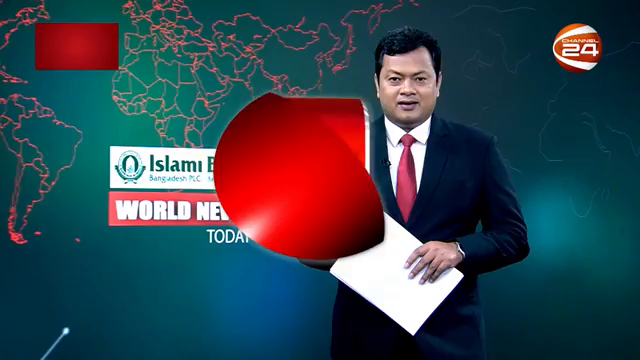


Frame Position: 721
Successfully Extracted: True


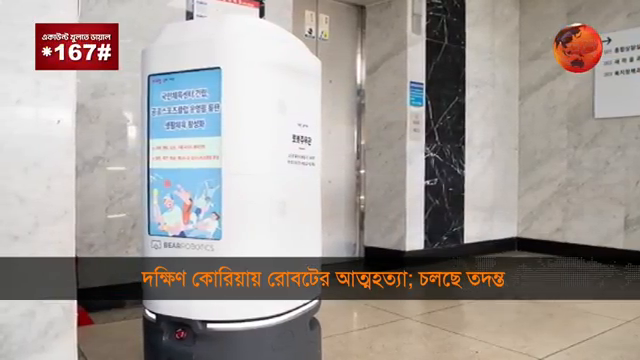


Frame Position: 1442
Successfully Extracted: True


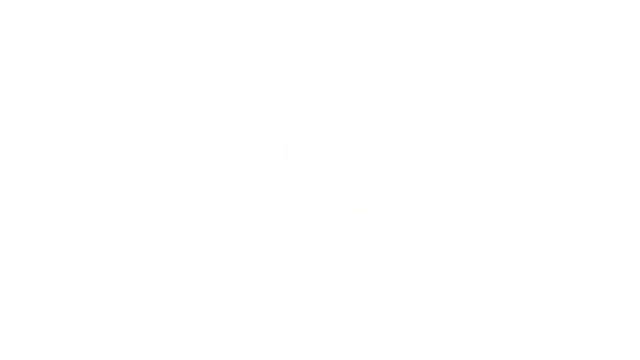


========== COMPLETE ==========


In [57]:
import cv2
import os
from IPython.display import display

sample_row = trimodal_df.iloc[0]

video_path = os.path.join(
    DATASET_PATH,
    sample_row["video_path"]
)

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

sample_positions = [
    0,
    total_frames // 2,
    total_frames - 1
]

print("========== VIDEO FRAME SAMPLING ==========")
print("Sample ID:", sample_row["id"])
print("Label:", sample_row["label"])
print("Total Frames:", total_frames)

for position in sample_positions:

    cap.set(cv2.CAP_PROP_POS_FRAMES, position)

    success, frame = cap.read()

    print("\nFrame Position:", position)
    print("Successfully Extracted:", success)

    if success:
        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        display(Image.fromarray(rgb_frame))

cap.release()

print("\n========== COMPLETE ==========")

========== MULTIMODAL SAMPLE INSPECTION ==========

Sample ID: 1028df55-8fec-435c-8586-4d10ce263b51
Label: Fake

Heading:
আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত

Body Text:
None

Corresponding Image:


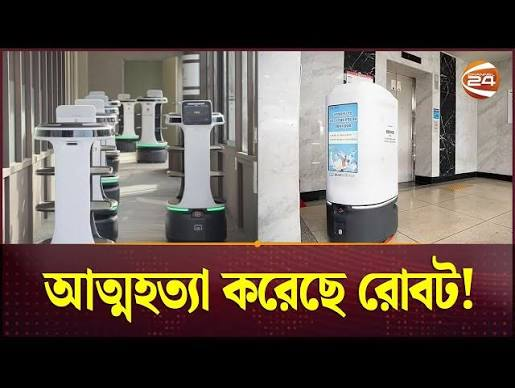


========== COMPLETE ==========


In [58]:
from PIL import Image
import os
from IPython.display import display

sample_row = trimodal_df.iloc[0]

image_path = os.path.join(
    DATASET_PATH,
    sample_row["image_path"]
)

print("========== MULTIMODAL SAMPLE INSPECTION ==========")

print("\nSample ID:", sample_row["id"])
print("Label:", sample_row["label"])

print("\nHeading:")
print(sample_row["heading"])

print("\nBody Text:")
print(sample_row["text"])

print("\nCorresponding Image:")
display(Image.open(image_path))

print("\n========== COMPLETE ==========")

========== SECOND SAMPLE INSPECTION ==========
Sample ID: 3a8ae39d-2063-48b2-b315-cca8e6882847
Label: Fake

Heading:
29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি বলছে NASA?

Body Text:
None

Corresponding Image:


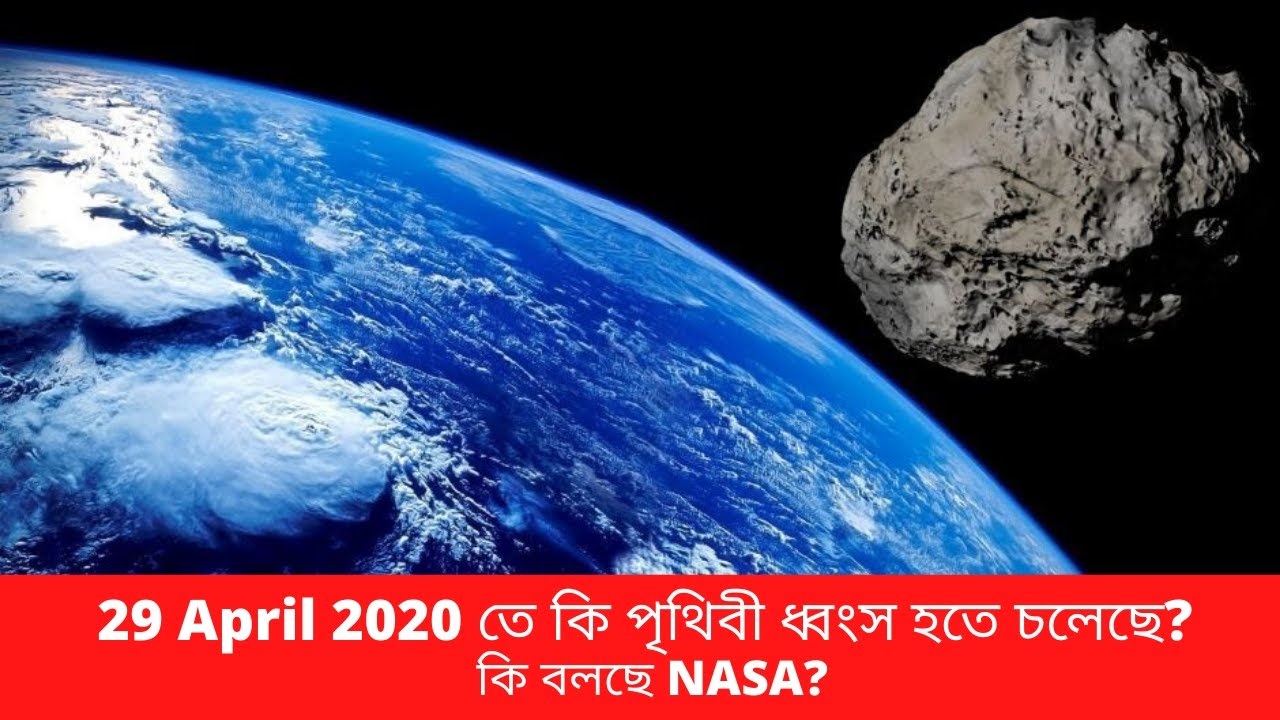


Total Video Frames: 7317

Frame Position: 0
Successfully Extracted: True


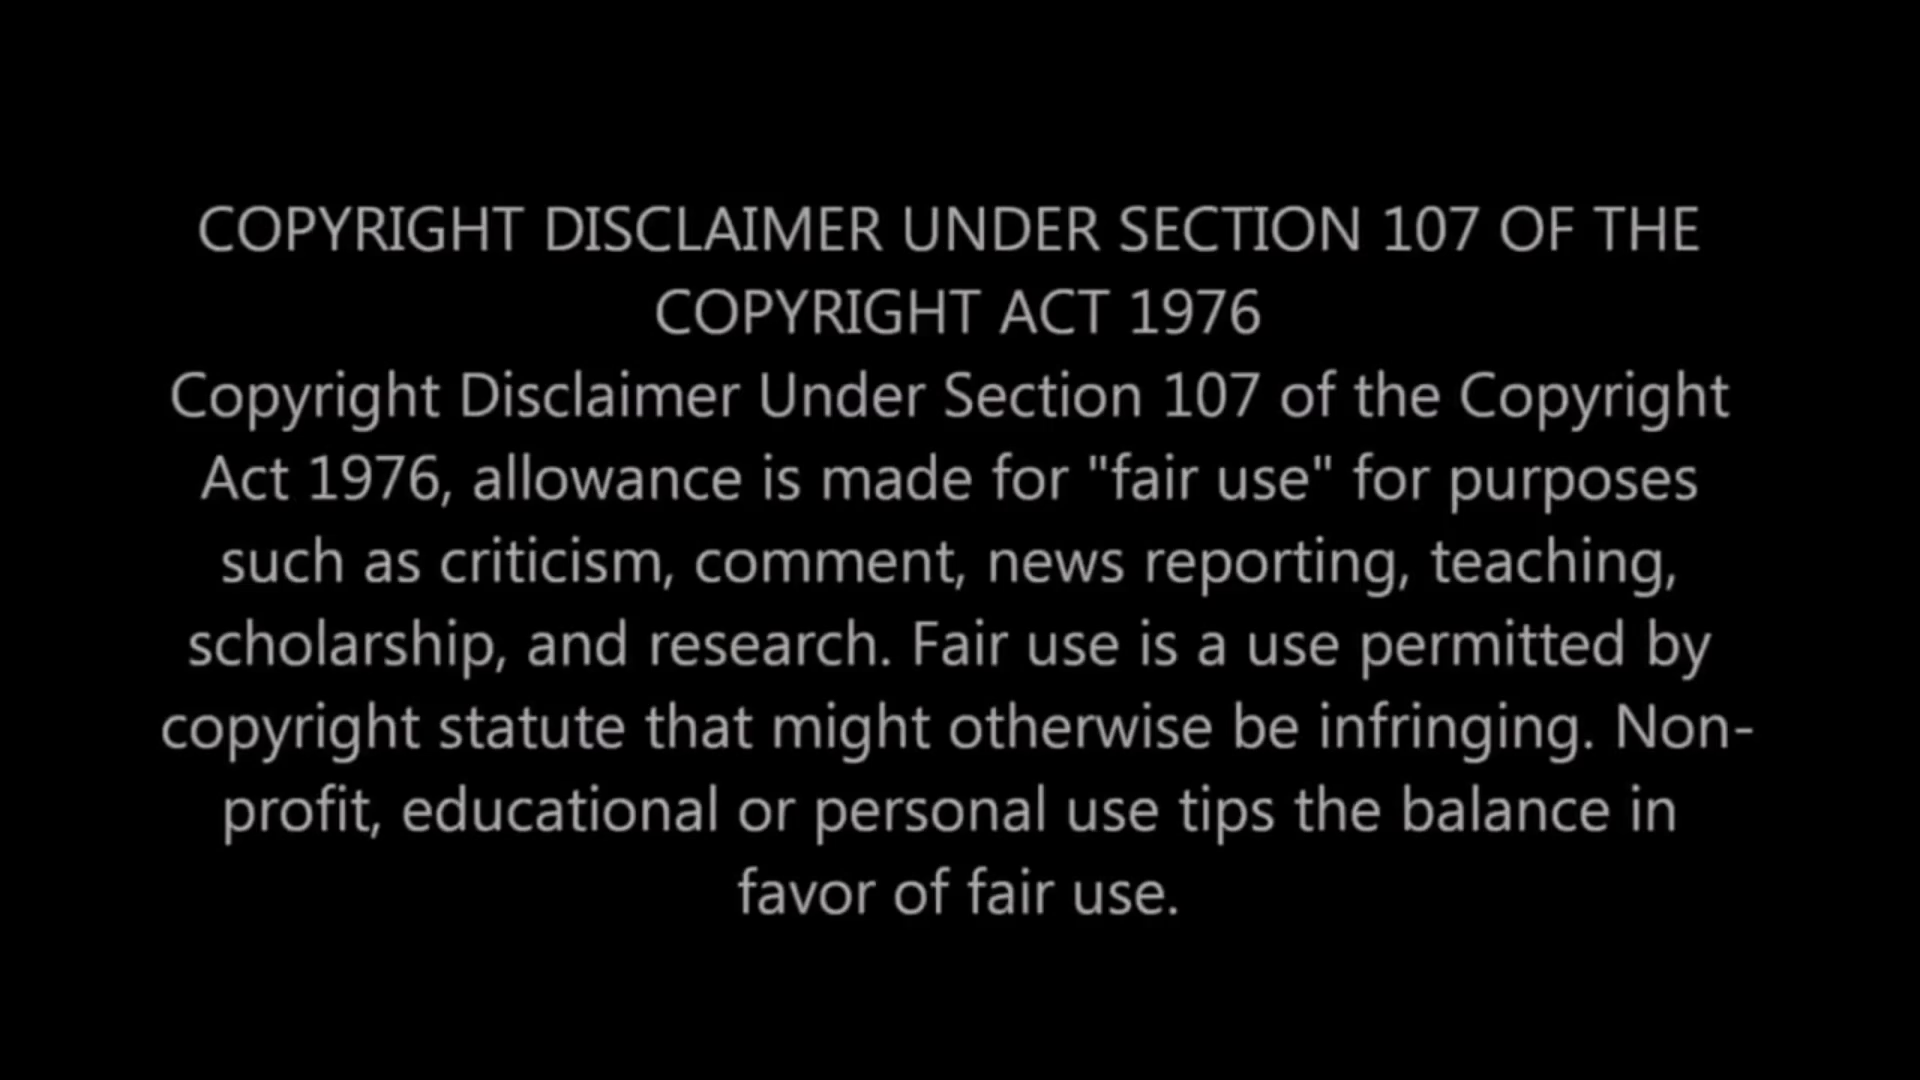


Frame Position: 3658
Successfully Extracted: True


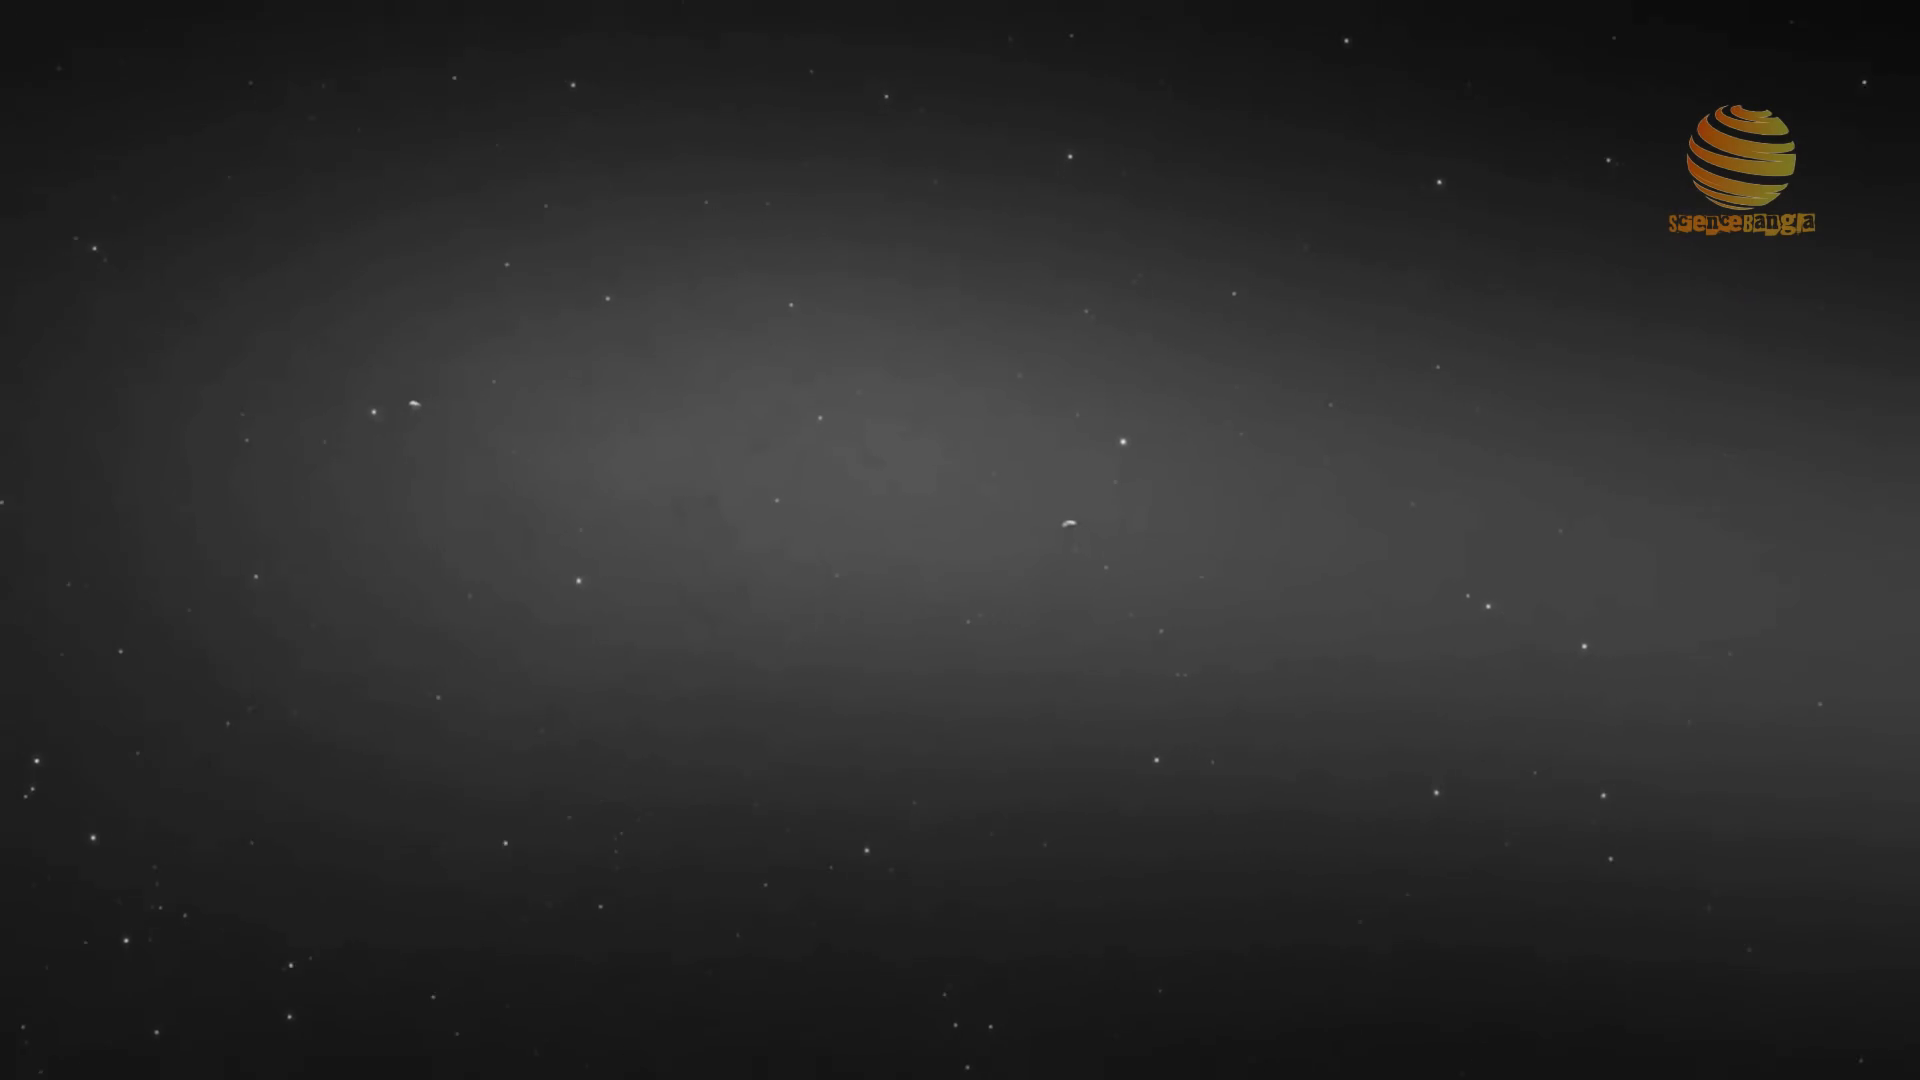


Frame Position: 7316
Successfully Extracted: True


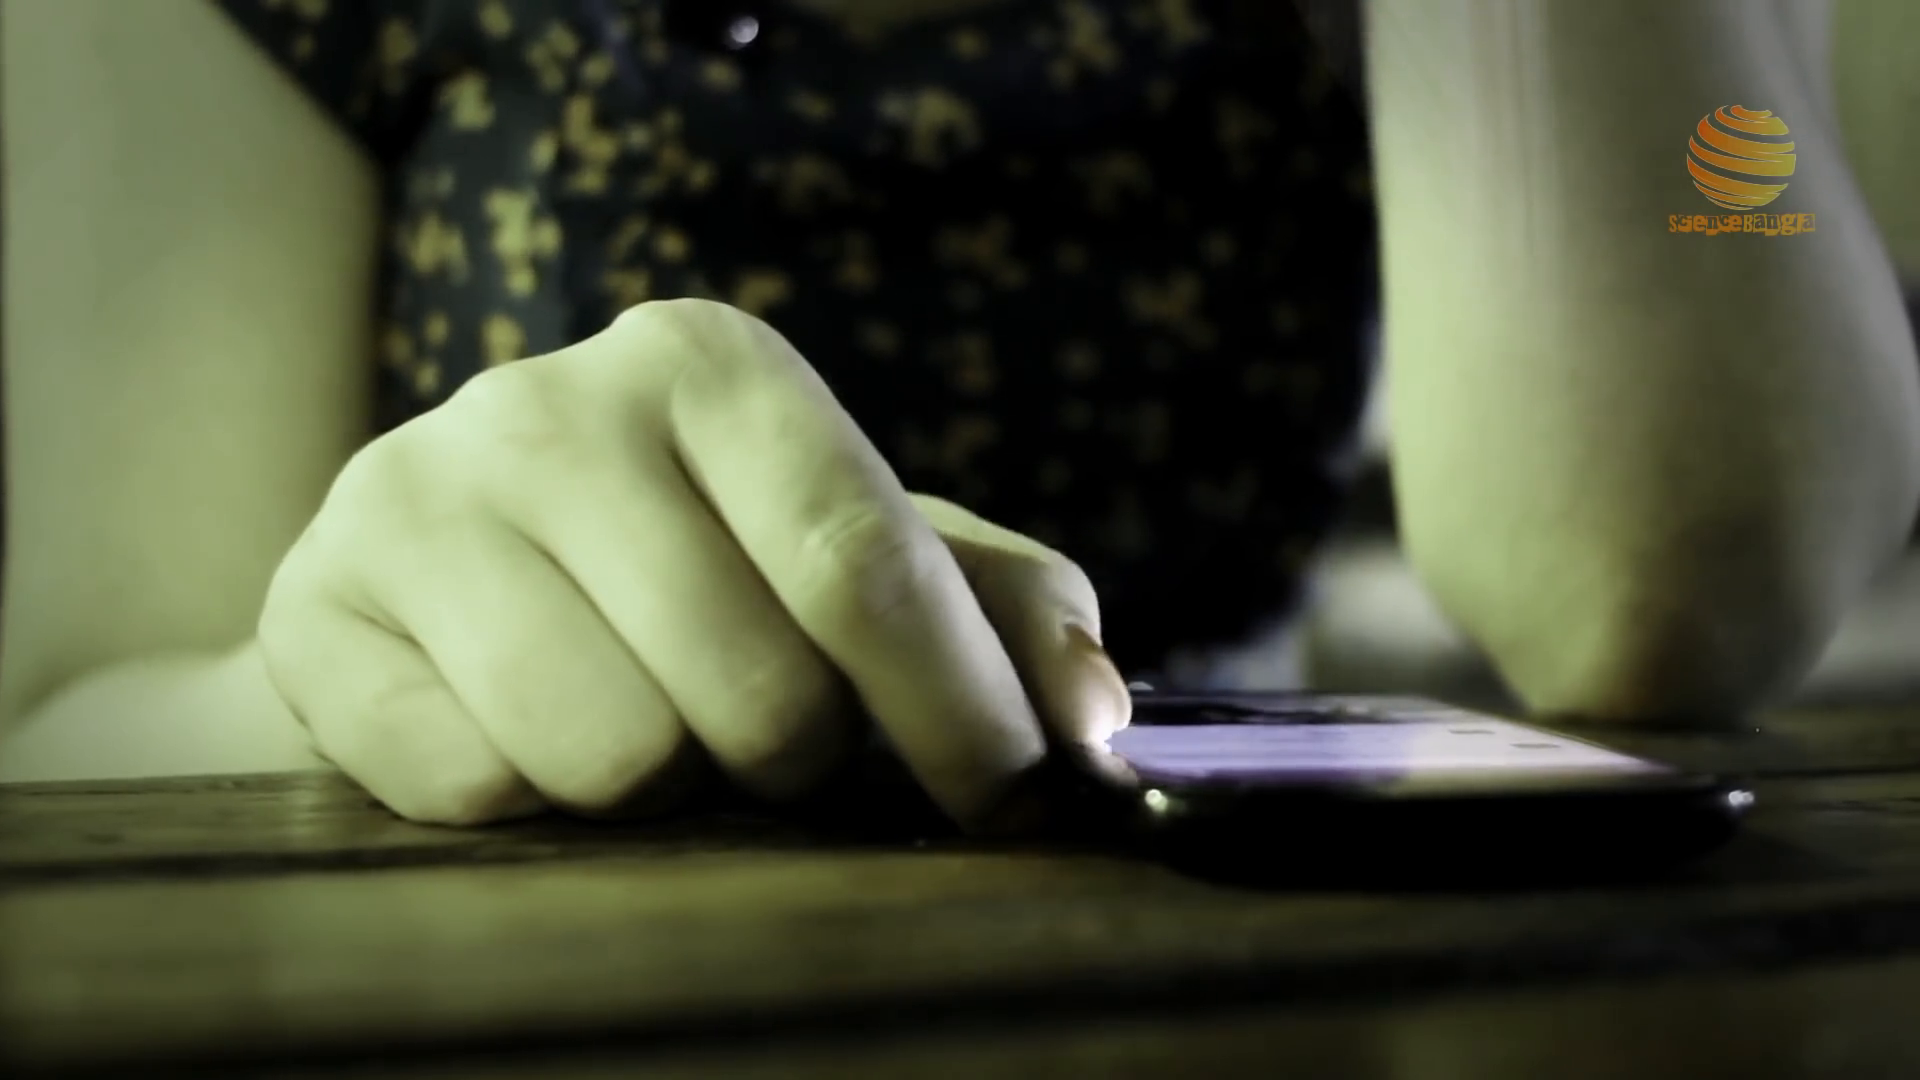


========== COMPLETE ==========


In [59]:
import cv2
import os
from PIL import Image
from IPython.display import display

sample_row = trimodal_df.iloc[1]

image_path = os.path.join(
    DATASET_PATH,
    sample_row["image_path"]
)

video_path = os.path.join(
    DATASET_PATH,
    sample_row["video_path"]
)

print("========== SECOND SAMPLE INSPECTION ==========")

print("Sample ID:", sample_row["id"])
print("Label:", sample_row["label"])

print("\nHeading:")
print(sample_row["heading"])

print("\nBody Text:")
print(sample_row["text"])

print("\nCorresponding Image:")
display(Image.open(image_path))

cap = cv2.VideoCapture(video_path)

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("\nTotal Video Frames:", total_frames)

for position in [
    0,
    total_frames // 2,
    total_frames - 1
]:

    cap.set(cv2.CAP_PROP_POS_FRAMES, position)

    success, frame = cap.read()

    print("\nFrame Position:", position)
    print("Successfully Extracted:", success)

    if success:
        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        display(Image.fromarray(rgb_frame))

cap.release()

print("\n========== COMPLETE ==========")

In [60]:

# STEP 16: Comparative Experiment - Sample Summary

import pandas as pd

# Read-only analysis
summary = []

modalities = {
    "Text Only (Heading OR Body Text)": df["has_heading"] | df["has_text"],
    "Image Only (Availability)": df["has_image"],
    "Video Only (Availability)": df["has_video"],
    "Trimodal (Text + Image + Video)": (
        (df["has_heading"] | df["has_text"]) &
        df["has_image"] &
        df["has_video"]
    )
}

for name, mask in modalities.items():
    subset = df[mask]

    summary.append({
        "Experiment": name,
        "Total Samples": len(subset),
        "Fake": (subset["label"] == "Fake").sum(),
        "Real": (subset["label"] == "Real").sum()
    })

summary_df = pd.DataFrame(summary)

print("========== COMPARATIVE EXPERIMENT SUMMARY ==========")
display(summary_df)

print("\n========== COMPLETE ==========")


========== COMPARATIVE EXPERIMENT SUMMARY ==========


,Experiment,Total Samples,Fake,Real
0,Text Only (Heading OR Body Text),4457,2245,2212
1,Image Only (Availability),4289,2152,2137
2,Video Only (Availability),1383,680,703
3,Trimodal (Text + Image + Video),79,50,29



========== COMPLETE ==========


In [61]:

# STEP 17: Check Existing Research Variables

required_variables = [
    "df",
    "trimodal_df",
    "duplicates",
    "video_hashes"
]

print("========== RUNTIME VARIABLE CHECK ==========")

for var in required_variables:
    print(f"{var}: {'Available' if var in globals() else 'Not Available'}")

print("\n========== COMPLETE ==========")


========== RUNTIME VARIABLE CHECK ==========
df: Available
trimodal_df: Available
duplicates: Available
video_hashes: Available

========== COMPLETE ==========


In [62]:

# STEP 18: Extract Duplicate Image Sample IDs

duplicate_image_records = []

for group_no, (image_hash, items) in enumerate(duplicates.items(), 1):

    sample_ids = [item["id"] for item in items]

    matched = df[df["id"].isin(sample_ids)]

    for _, row in matched.iterrows():
        duplicate_image_records.append({
            "Group": group_no,
            "Sample_ID": row["id"],
            "Label": row["label"],
            "Heading": row["heading"]
        })

duplicate_image_df = pd.DataFrame(duplicate_image_records)

print("========== DUPLICATE IMAGE GROUP SUMMARY ==========")
print("Duplicate Groups:", duplicate_image_df["Group"].nunique())
print("Total Duplicate Samples:", len(duplicate_image_df))

print("\nLabel Distribution:")
print(duplicate_image_df["Label"].value_counts())

print("\nDetailed Records:")
display(duplicate_image_df)

print("\n========== COMPLETE ==========")


========== DUPLICATE IMAGE GROUP SUMMARY ==========
Duplicate Groups: 23
Total Duplicate Samples: 47

Label Distribution:
Label
Fake    37
Real    10
Name: count, dtype: int64

Detailed Records:


,Group,Sample_ID,Label,Heading
0,1,07822593-0f68-437f-ba7e-908030ec6691,Fake,None
1,1,fc059792-2956-4004-93a3-9c925e673afd,Fake,None
2,2,b25b3782-df28-4c69-8d70-347ab9de190f,Fake,None
3,2,4f0727c7-bc9c-4887-a963-72ad7d9763f6,Fake,None
4,3,6da689ee-f792-4e2f-8c03-fc8b81517c8b,Fake,None
5,3,f624618b-9eb5-4b86-aa14-442aa98645d6,Fake,None
6,4,506a378c-4fac-4d5a-bac3-6d269873619a,Fake,None
7,4,4033cc8a-d43f-449a-b7e7-ba0374a1cc32,Fake,None
8,4,273af1fd-ff60-41b2-b45b-64fcf6afd1b7,Fake,None
9,5,32bd0c3a-8fee-481d-ab37-545f2e6842af,Fake,None



========== COMPLETE ==========


In [63]:

# STEP 19: Inspect Video Hash Structure

print("========== VIDEO HASH STRUCTURE ==========")

print("Variable Type:", type(video_hashes))
print("Total Entries:", len(video_hashes))

if isinstance(video_hashes, dict):
    print("\nFirst 2 Entries:")
    for i, (key, value) in enumerate(video_hashes.items()):
        if i == 2:
            break
        print("Key:", key)
        print("Value:", value)

elif isinstance(video_hashes, (list, tuple)):
    print("\nFirst 2 Entries:")
    for item in video_hashes[:2]:
        print(item)

else:
    print("\nSample:")
    print(repr(video_hashes)[:1000])

print("\n========== COMPLETE ==========")


========== VIDEO HASH STRUCTURE ==========
Variable Type: <class 'collections.defaultdict'>
Total Entries: 1374

First 2 Entries:
Key: 6b25da830fcb81834b6504429ac70a1b
Value: [{'path': 'videos/Fake_00001_c1168c6c-d411-4f12-95ff-ffdcc3529ca1.mp4', 'label': 'Fake'}]
Key: cbcc18491963d3b625a8be6f00106ed6
Value: [{'path': 'videos/Fake_00002_1ec95d89-7463-4f94-a960-d6f2576143cf.mp4', 'label': 'Fake'}]

========== COMPLETE ==========


In [64]:
# STEP 20: Extract Duplicate Video Groups

duplicate_video_groups = {
    video_hash: items
    for video_hash, items in video_hashes.items()
    if len(items) > 1
}

print("========== DUPLICATE VIDEO SUMMARY ==========")

print("Duplicate Groups:", len(duplicate_video_groups))

total_duplicate_samples = sum(
    len(items) for items in duplicate_video_groups.values()
)

print("Total Duplicate Samples:", total_duplicate_samples)

duplicate_video_records = []

for group_no, (video_hash, items) in enumerate(
    duplicate_video_groups.items(), 1
):
    for item in items:
        video_path = item["path"]

        matched = df[df["video_path"] == video_path]

        for _, row in matched.iterrows():
            duplicate_video_records.append({
                "group": group_no,
                "id": row["id"],
                "label": row["label"],
                "video_path": video_path,
                "heading": row["heading"]
            })

duplicate_video_df = pd.DataFrame(duplicate_video_records)

print("\nMatched Duplicate Samples:", len(duplicate_video_df))

print("\nLabel Distribution:")
print(duplicate_video_df["label"].value_counts())

print("\nDuplicate Video Details:")
display(duplicate_video_df)

print("\n========== COMPLETE ==========")

========== DUPLICATE VIDEO SUMMARY ==========
Duplicate Groups: 7
Total Duplicate Samples: 16

Matched Duplicate Samples: 16

Label Distribution:
label
Real    10
Fake     6
Name: count, dtype: int64

Duplicate Video Details:


,group,id,label,video_path,heading
0,1,95819f5a-036f-4116-be68-fa6d1a55b90c,Real,videos/Real_00193_95819f5a-036f-4116-be68-fa6d...,চাঁদপুরের ফরিদগঞ্জে বিএনপির দুই গ্রুপের সংঘর্ষ
1,1,913c57a5-f4c5-4a77-8f50-df7397420076,Real,videos/Real_00198_913c57a5-f4c5-4a77-8f50-df73...,খিলগাঁওয়ে দুস্থ মানুষের মাঝে খাদ্য সামগ্রী বিত...
2,2,2d48d2d3-dc6e-4fc0-ae16-13cf28205dc3,Fake,videos/Fake_00060_2d48d2d3-dc6e-4fc0-ae16-13cf...,আলহামদুলিল্লাহ পৃথিবীর মানচিত্র থেকে ইসরাইলের ...
3,2,96ec043c-9649-440b-9772-a29036f54926,Fake,videos/Fake_00061_96ec043c-9649-440b-9772-a290...,ইরানের সর্বোচ্চ নেতা আলী খামেনি এর বাসভবনে ৩০ট...
4,3,64709f00-db25-45c8-8270-4a58109e594e,Real,videos/Real_00152_64709f00-db25-45c8-8270-4a58...,উত্তর চীনের বিস্তৃত মরুভূমি এখন পরিণত হয়েছে স...
5,3,fe404840-a825-453d-8be0-40ce41b54e0b,Real,videos/Real_00153_fe404840-a825-453d-8be0-40ce...,তুলা চাষে বিপ্লব ঘটিয়েছে স্মার্ট প্রযুক্তি
6,4,4578ed99-259b-4d75-860d-9700bcb09830,Fake,videos/Fake_00223_4578ed99-259b-4d75-860d-9700...,"বাদ সৌম্য! চন্ডীকা হাথুরুসিংয়ের ডাকে,সব অভিমা..."
7,4,613fff60-e8b2-49fc-bb51-6addaabd2adf,Fake,videos/Fake_00224_613fff60-e8b2-49fc-bb51-6add...,"ফিজকে আইপিএল খেলতে না দিলে খবর আছে বিসিবির,ম্য..."
8,4,d99c09aa-dd5c-4ce2-ba73-7c4d1fbc9f2d,Fake,videos/Fake_00225_d99c09aa-dd5c-4ce2-ba73-7c4d...,"ওরে বাপরে এ যেন বল নয় কামানেরগোলা ছাড়ছে ফিজ,ব..."
9,4,e37cadb7-fbc4-41bf-bb4e-d9fb2074e007,Fake,videos/Fake_00226_e37cadb7-fbc4-41bf-bb4e-d9fb...,নাটক শেষ ! আবারো জাতীয় দলে ফিরছেন তামিম ইকবাল



========== COMPLETE ==========


In [65]:
# STEP 21: Check Duplicate Videos in Trimodal Dataset

trimodal_ids = set(trimodal_df["id"].astype(str))

duplicate_video_trimodal_df = duplicate_video_df[
    duplicate_video_df["id"].astype(str).isin(trimodal_ids)
].copy()

print("========== TRIMODAL VIDEO DUPLICATE CHECK ==========")

print("Total Trimodal Samples:", len(trimodal_df))
print("Duplicate Video Samples in Trimodal:", len(duplicate_video_trimodal_df))

print(
    "Duplicate Video Groups in Trimodal:",
    duplicate_video_trimodal_df["group"].nunique()
)

if len(duplicate_video_trimodal_df) > 0:
    print("\nLabel Distribution:")
    print(duplicate_video_trimodal_df["label"].value_counts())

    print("\nMatched Samples:")
    display(duplicate_video_trimodal_df[
        ["group", "id", "label", "heading"]
    ])
else:
    print("\nNo duplicate video samples found in the trimodal dataset.")

print("\n========== COMPLETE ==========")

========== TRIMODAL VIDEO DUPLICATE CHECK ==========
Total Trimodal Samples: 79
Duplicate Video Samples in Trimodal: 0
Duplicate Video Groups in Trimodal: 0

No duplicate video samples found in the trimodal dataset.

========== COMPLETE ==========


In [67]:
# Check duplicate_image_df columns

print("Columns:", duplicate_image_df.columns.tolist())
print("\nFirst 5 rows:")
display(duplicate_image_df.head())

Columns: ['Group', 'Sample_ID', 'Label', 'Heading']

First 5 rows:


,Group,Sample_ID,Label,Heading
0,1,07822593-0f68-437f-ba7e-908030ec6691,Fake,None
1,1,fc059792-2956-4004-93a3-9c925e673afd,Fake,None
2,2,b25b3782-df28-4c69-8d70-347ab9de190f,Fake,None
3,2,4f0727c7-bc9c-4887-a963-72ad7d9763f6,Fake,None
4,3,6da689ee-f792-4e2f-8c03-fc8b81517c8b,Fake,None


In [68]:
# STEP 22: Check Duplicate Images in Trimodal Dataset

trimodal_ids = set(trimodal_df["id"].astype(str))

duplicate_image_trimodal_df = duplicate_image_df[
    duplicate_image_df["Sample_ID"].astype(str).isin(trimodal_ids)
].copy()

print("========== TRIMODAL IMAGE DUPLICATE CHECK ==========")

print("Total Trimodal Samples:", len(trimodal_df))
print("Duplicate Image Samples in Trimodal:",
      len(duplicate_image_trimodal_df))

print("Duplicate Image Groups in Trimodal:",
      duplicate_image_trimodal_df["Group"].nunique())

if len(duplicate_image_trimodal_df) > 0:
    print("\nLabel Distribution:")
    print(duplicate_image_trimodal_df["Label"].value_counts())

    print("\nMatched Samples:")
    display(duplicate_image_trimodal_df[
        ["Group", "Sample_ID", "Label", "Heading"]
    ])
else:
    print("\nNo duplicate image samples found in the trimodal dataset.")

print("\n========== COMPLETE ==========")

========== TRIMODAL IMAGE DUPLICATE CHECK ==========
Total Trimodal Samples: 79
Duplicate Image Samples in Trimodal: 0
Duplicate Image Groups in Trimodal: 0

No duplicate image samples found in the trimodal dataset.

========== COMPLETE ==========


In [69]:

# ============================================
# STEP 23: TRIMODAL DATA QUALITY CHECK
# ============================================

print("=" * 55)
print("TRIMODAL DATA QUALITY CHECK")
print("=" * 55)

# Required modality columns
modalities = {
    "Text": "has_text",
    "Image": "has_image",
    "Video": "has_video"
}

# Check required columns
missing_columns = [
    col for col in modalities.values()
    if col not in trimodal_df.columns
]

if missing_columns:
    print("ERROR: Missing columns:", missing_columns)

else:
    check_df = trimodal_df.copy()

    # Count available and missing modalities
    for modality, column in modalities.items():
        check_df[column] = (
            check_df[column].fillna(False).astype(bool)
        )

        available = check_df[column].sum()
        missing = len(check_df) - available

        print(f"\n{modality}:")
        print(f"  Available: {available}")
        print(f"  Missing:   {missing}")

    # Find incomplete samples
    check_df["complete"] = check_df[
        list(modalities.values())
    ].all(axis=1)

    incomplete = check_df[~check_df["complete"]]

    print("\n" + "=" * 55)
    print("OVERALL DATA QUALITY")
    print("=" * 55)

    print("Total Samples:", len(check_df))
    print("Complete Samples:", check_df["complete"].sum())
    print("Incomplete Samples:", len(incomplete))

    if len(incomplete) > 0:
        print("\nIncomplete Sample IDs:")
        print(incomplete["id"].tolist())

    else:
        print("\nAll samples contain Text, Image and Video.")

    print("\n========== STEP 23 COMPLETE ==========")


TRIMODAL DATA QUALITY CHECK

Text:
  Available: 1
  Missing:   78

Image:
  Available: 79
  Missing:   0

Video:
  Available: 79
  Missing:   0

OVERALL DATA QUALITY
Total Samples: 79
Complete Samples: 1
Incomplete Samples: 78

Incomplete Sample IDs:
['1028df55-8fec-435c-8586-4d10ce263b51', '3a8ae39d-2063-48b2-b315-cca8e6882847', 'c0b95823-b774-46e7-8e14-f840f8e44352', 'cff01130-9f50-4c27-8945-c309192f6b94', '898ad02d-82d0-4d34-8c57-2dd2808f7d8d', 'd753a955-05d8-49ed-a810-eb286ccef56f', '679926b9-a5c2-4799-976e-cc9acbc298f0', 'a4212bf0-2374-4d58-8f24-0e18112ec2a5', '0323d43e-8a37-4da2-b93f-67ab74b96839', 'eec52624-9b0f-4afd-87d4-91a49ce2da79', '76a287aa-5205-468a-81da-ec47031951f1', '59f7fee2-34ff-43e3-9001-0b4169fa5b0b', 'd5841ad7-c473-47db-9a56-b222f0acd41b', 'f602a539-f462-4900-9725-1068614e8662', 'b36dc1f0-2bdc-4a35-9e5b-c1e7dfda467c', '4db38797-8e17-44b2-91db-affbc09b8cf5', 'fdc691a4-3b56-43ae-a826-7def18a922af', '464d21fc-50ed-4f60-99c9-ee5d256d28bf', '04057d5e-f0a9-4115-9b90-1de

In [70]:

# ============================================
# STEP 24: TEXT COLUMN INVESTIGATION
# ============================================

print("DATASET COLUMNS:")
print(trimodal_df.columns.tolist())

print("\nDATA TYPES:")
print(trimodal_df.dtypes)

print("\nFIRST 10 ROWS:")
display(trimodal_df.head(10))

print("\nTEXT-RELATED COLUMNS:")

for col in trimodal_df.columns:
    if any(word in col.lower() for word in
           ["text", "heading", "caption", "title", "content"]):

        print(f"\nColumn: {col}")
        print("Non-null:", trimodal_df[col].notna().sum())
        print("Sample values:")
        print(trimodal_df[col].head(5).tolist())

print("\n========== INVESTIGATION COMPLETE ==========")


DATASET COLUMNS:
['id', 'heading', 'text', 'image_path', 'video_path', 'label', 'multi_category', 'source_category', 'category', 'has_heading', 'has_text', 'has_image', 'has_video', 'modality_combination', 'image_count']

DATA TYPES:
id                      object
heading                 object
text                    object
image_path              object
video_path              object
label                   object
multi_category          object
source_category         object
category                object
has_heading               bool
has_text                  bool
has_image                 bool
has_video                 bool
modality_combination    object
image_count              int64
dtype: object

FIRST 10 ROWS:


,id,heading,text,image_path,video_path,label,multi_category,source_category,category,has_heading,has_text,has_image,has_video,modality_combination,image_count
2773,1028df55-8fec-435c-8586-4d10ce263b51,"আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত",None,images/Fake_00859_1028df55-8fec-435c-8586-4d10...,videos/Fake_00131_1028df55-8fec-435c-8586-4d10...,Fake,Clickbait,Facebook,Technology,True,False,True,True,HIV,1
4797,3a8ae39d-2063-48b2-b315-cca8e6882847,29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি...,None,images/Fake_00182_3a8ae39d-2063-48b2-b315-cca8...,videos/Fake_00202_3a8ae39d-2063-48b2-b315-cca8...,Fake,Clickbait,Facebook,Science,True,False,True,True,HIV,1
5382,f3396b7d-c918-4577-bb44-51fb784c0a4c,ঢাকা আর থাকবে না। আসছে ৯ মাত্রার ভূমিকম্প।,"নারায়ণগঞ্জের রূপগঞ্জ, রাজধানী ঢাকার আগারগাঁও ...",images/Fake_00765_f3396b7d-c918-4577-bb44-51fb...,videos/Fake_00119_f3396b7d-c918-4577-bb44-51fb...,Fake,Clickbait,YouTube,Environment,True,True,True,True,HTIV,1
5383,c0b95823-b774-46e7-8e14-f840f8e44352,২২ জুন ২০২৬ সোমবার। ভূমিকম্প। ঢাকার একি হলো আজকে,None,images/Fake_00766_c0b95823-b774-46e7-8e14-f840...,videos/Fake_00120_c0b95823-b774-46e7-8e14-f840...,Fake,Clickbait,YouTube,Science,True,False,True,True,HIV,1
5388,cff01130-9f50-4c27-8945-c309192f6b94,এখানে ভূমিকম্প হবেই,None,images/Fake_00770_cff01130-9f50-4c27-8945-c309...,videos/Fake_00122_cff01130-9f50-4c27-8945-c309...,Fake,Misinformation,YouTube,Environment,True,False,True,True,HIV,1
5389,898ad02d-82d0-4d34-8c57-2dd2808f7d8d,ধ্বংস হয়ে যেতে পারে/ ঢাকা /শহর/ (ভূমিকম্পের) ...,None,images/Fake_00771_898ad02d-82d0-4d34-8c57-2dd2...,videos/Fake_00123_898ad02d-82d0-4d34-8c57-2dd2...,Fake,Clickbait,YouTube,Environment,True,False,True,True,HIV,1
5390,d753a955-05d8-49ed-a810-eb286ccef56f,৩০ সেকেন্ডের ভূমিকম্পে বাংলাদেশের সকল বিল্ডিং ...,None,images/Fake_00772_d753a955-05d8-49ed-a810-eb28...,videos/Fake_00124_d753a955-05d8-49ed-a810-eb28...,Fake,Misinformation,YouTube,Environment,True,False,True,True,HIV,1
5391,679926b9-a5c2-4799-976e-cc9acbc298f0,"৭২ ঘণ্টার মধ্যে বড় ভূমিকম্প, বাংলাদেশ ধ্বংস হও...",None,images/Fake_00773_679926b9-a5c2-4799-976e-cc9a...,videos/Fake_00125_679926b9-a5c2-4799-976e-cc9a...,Fake,Clickbait,YouTube,Environment,True,False,True,True,HIV,1
5393,a4212bf0-2374-4d58-8f24-0e18112ec2a5,ভূমিকম্পে কি হয়ে গেল ঢাকায়,None,images/Fake_00775_a4212bf0-2374-4d58-8f24-0e18...,videos/Fake_00126_a4212bf0-2374-4d58-8f24-0e18...,Fake,Clickbait,YouTube,Environment,True,False,True,True,HIV,1
5395,0323d43e-8a37-4da2-b93f-67ab74b96839,আসছে আরও ভয়ংকর ভূমিকম্প! | এক ঝটকায় শহর ধ্বংস,None,images/Fake_00777_0323d43e-8a37-4da2-b93f-67ab...,videos/Fake_00127_0323d43e-8a37-4da2-b93f-67ab...,Fake,Clickbait,YouTube,Environment,True,False,True,True,HIV,1



TEXT-RELATED COLUMNS:

Column: heading
Non-null: 79
Sample values:
["আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত", '29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি বলছে NASA?', 'ঢাকা আর থাকবে না। আসছে ৯ মাত্রার ভূমিকম্প।', '২২ জুন ২০২৬ সোমবার। ভূমিকম্প। ঢাকার একি হলো আজকে', 'এখানে ভূমিকম্প হবেই']

Column: text
Non-null: 1
Sample values:
[None, None, 'নারায়ণগঞ্জের রূপগঞ্জ, রাজধানী ঢাকার আগারগাঁও থেকে যার দূরত্ব মাত্র ১৬ কিলোমিটার। মার্কিন ভূতাত্ত্বিক জরিপ সংস্থা (USGS) জানিয়েছে যে, এই অঞ্চলে ঘটে যাওয়া সাম্প্রতিক ভূমিকম্পটির মাত্রা ছিল রিখটার স্কেলে ৪.৪ এবং এর কেন্দ্র ছিল ভূপৃষ্ঠের মাত্র ১০ কিলোমিটার গভীরে। এর আগে গত বছরের ২১ নভেম্বর আরও একটি তীব্র ভূমিকম্পের সাক্ষী হয়েছিল ঢাকা, যার মাত্রা ছিল ৫.৭ এবং উৎপত্তিস্থল ছিল নরসিংদীর মাধবদী। আলোচিত সেই ভূমিকম্পে কয়েকজনের প্রাণহানি ও রাজধানীতে বহু ক্ষয়ক্ষতি হয়েছিল। এবারের সোমবারের ভূমিকম্পে কোনো হতাহতের ঘটনা না থাকলেও এটি রাজধানী ঢাকা, নারায়ণগঞ্জ, গাজীপুর, নরসিংদী ও আশপাশের এলাকায় তীব্রভাবে অনুভূত হয়েছে, যার ফলে সাধারণ মানুষের মধ্যে ব্যাপক আতঙ্ক

In [71]:

# ============================================
# STEP 25: COMBINED TEXT AVAILABILITY CHECK
# ============================================

import pandas as pd

check_df = trimodal_df.copy()

# Combine heading and text body
check_df["combined_text"] = (
    check_df["heading"].fillna("").astype(str).str.strip()
    + " "
    + check_df["text"].fillna("").astype(str).str.strip()
).str.strip()

# Check actual text availability
check_df["has_combined_text"] = (
    check_df["combined_text"].str.len() > 0
)

print("=" * 55)
print("COMBINED TEXT AVAILABILITY")
print("=" * 55)

print("Total Samples:", len(check_df))
print("Samples with Heading:",
      check_df["heading"].fillna("").str.strip().ne("").sum())

print("Samples with Text Body:",
      check_df["text"].fillna("").str.strip().ne("").sum())

print("Samples with Combined Text:",
      check_df["has_combined_text"].sum())

print("Samples without Any Text:",
      (~check_df["has_combined_text"]).sum())

print("\nMODALITY COMBINATION DISTRIBUTION:")
print(check_df["modality_combination"].value_counts())

print("\nLABEL DISTRIBUTION:")
print(check_df["label"].value_counts())

print("\nSAMPLE COMBINED TEXT:")
display(
    check_df[["id", "heading", "text", "combined_text"]].head(5)
)

print("\n========== STEP 25 COMPLETE ==========")


COMBINED TEXT AVAILABILITY
Total Samples: 79
Samples with Heading: 79
Samples with Text Body: 1
Samples with Combined Text: 79
Samples without Any Text: 0

MODALITY COMBINATION DISTRIBUTION:
modality_combination
HIV     78
HTIV     1
Name: count, dtype: int64

LABEL DISTRIBUTION:
label
Fake    50
Real    29
Name: count, dtype: int64

SAMPLE COMBINED TEXT:


,id,heading,text,combined_text
2773,1028df55-8fec-435c-8586-4d10ce263b51,"আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত",None,"আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত"
4797,3a8ae39d-2063-48b2-b315-cca8e6882847,29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি...,None,29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি...
5382,f3396b7d-c918-4577-bb44-51fb784c0a4c,ঢাকা আর থাকবে না। আসছে ৯ মাত্রার ভূমিকম্প।,"নারায়ণগঞ্জের রূপগঞ্জ, রাজধানী ঢাকার আগারগাঁও ...",ঢাকা আর থাকবে না। আসছে ৯ মাত্রার ভূমিকম্প। নার...
5383,c0b95823-b774-46e7-8e14-f840f8e44352,২২ জুন ২০২৬ সোমবার। ভূমিকম্প। ঢাকার একি হলো আজকে,None,২২ জুন ২০২৬ সোমবার। ভূমিকম্প। ঢাকার একি হলো আজকে
5388,cff01130-9f50-4c27-8945-c309192f6b94,এখানে ভূমিকম্প হবেই,None,এখানে ভূমিকম্প হবেই



========== STEP 25 COMPLETE ==========


In [72]:

# ============================================
# STEP 26: PREPARE TRIMODAL TEXT INPUT
# ============================================

import pandas as pd

# Create a separate working dataframe
trimodal_model_df = trimodal_df.copy()

# Clean heading and body text
trimodal_model_df["heading"] = (
    trimodal_model_df["heading"]
    .fillna("")
    .astype(str)
    .str.strip()
)

trimodal_model_df["text"] = (
    trimodal_model_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Combine heading and body text
trimodal_model_df["combined_text"] = (
    trimodal_model_df["heading"] + " " +
    trimodal_model_df["text"]
).str.strip()

# Validate prepared data
print("=" * 55)
print("TRIMODAL TEXT INPUT PREPARATION")
print("=" * 55)

print("Total Samples:", len(trimodal_model_df))

print("Empty Text:",
      (trimodal_model_df["combined_text"] == "").sum())

print("Fake Samples:",
      (trimodal_model_df["label"] == "Fake").sum())

print("Real Samples:",
      (trimodal_model_df["label"] == "Real").sum())

print("\nTEXT LENGTH STATISTICS:")
print(trimodal_model_df["combined_text"].str.len().describe())

print("\nSAMPLE PREVIEW:")
display(
    trimodal_model_df[
        ["id", "combined_text", "label"]
    ].head(5)
)

print("\n========== STEP 26 COMPLETE ==========")


TRIMODAL TEXT INPUT PREPARATION
Total Samples: 79
Empty Text: 0
Fake Samples: 50
Real Samples: 29

TEXT LENGTH STATISTICS:
count      79.000000
mean       86.797468
std       261.830018
min        19.000000
25%        47.000000
50%        58.000000
75%        66.500000
max      2380.000000
Name: combined_text, dtype: float64

SAMPLE PREVIEW:


,id,combined_text,label
2773,1028df55-8fec-435c-8586-4d10ce263b51,"আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত",Fake
4797,3a8ae39d-2063-48b2-b315-cca8e6882847,29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি...,Fake
5382,f3396b7d-c918-4577-bb44-51fb784c0a4c,ঢাকা আর থাকবে না। আসছে ৯ মাত্রার ভূমিকম্প। নার...,Fake
5383,c0b95823-b774-46e7-8e14-f840f8e44352,২২ জুন ২০২৬ সোমবার। ভূমিকম্প। ঢাকার একি হলো আজকে,Fake
5388,cff01130-9f50-4c27-8945-c309192f6b94,এখানে ভূমিকম্প হবেই,Fake



========== STEP 26 COMPLETE ==========


In [73]:

# ============================================
# STEP 27: IMAGE & VIDEO FILE VERIFICATION
# ============================================

import os
from pathlib import Path

print("=" * 55)
print("IMAGE AND VIDEO FILE VERIFICATION")
print("=" * 55)

def verify_files(column):
    existing = []
    missing = []

    for path in trimodal_model_df[column]:
        if pd.isna(path) or not str(path).strip():
            missing.append(path)
        elif Path(str(path)).is_file():
            existing.append(path)
        else:
            missing.append(path)

    return existing, missing


# Verify images
images_found, images_missing = verify_files("image_path")

# Verify videos
videos_found, videos_missing = verify_files("video_path")

print("\nIMAGE VERIFICATION:")
print("Total:", len(trimodal_model_df))
print("Found:", len(images_found))
print("Missing:", len(images_missing))

print("\nVIDEO VERIFICATION:")
print("Total:", len(trimodal_model_df))
print("Found:", len(videos_found))
print("Missing:", len(videos_missing))

print("\nCURRENT WORKING DIRECTORY:")
print(os.getcwd())

if images_missing:
    print("\nMissing Image Paths:")
    print(images_missing[:10])

if videos_missing:
    print("\nMissing Video Paths:")
    print(videos_missing[:10])

print("\n========== STEP 27 COMPLETE ==========")


IMAGE AND VIDEO FILE VERIFICATION

IMAGE VERIFICATION:
Total: 79
Found: 0
Missing: 79

VIDEO VERIFICATION:
Total: 79
Found: 0
Missing: 79

CURRENT WORKING DIRECTORY:
/content

Missing Image Paths:
['images/Fake_00859_1028df55-8fec-435c-8586-4d10ce263b51.png', 'images/Fake_00182_3a8ae39d-2063-48b2-b315-cca8e6882847.jpg', 'images/Fake_00765_f3396b7d-c918-4577-bb44-51fb784c0a4c.png', 'images/Fake_00766_c0b95823-b774-46e7-8e14-f840f8e44352.png', 'images/Fake_00770_cff01130-9f50-4c27-8945-c309192f6b94.png', 'images/Fake_00771_898ad02d-82d0-4d34-8c57-2dd2808f7d8d.png', 'images/Fake_00772_d753a955-05d8-49ed-a810-eb286ccef56f.png', 'images/Fake_00773_679926b9-a5c2-4799-976e-cc9acbc298f0.png', 'images/Fake_00775_a4212bf0-2374-4d58-8f24-0e18112ec2a5.png', 'images/Fake_00777_0323d43e-8a37-4da2-b93f-67ab74b96839.png']

Missing Video Paths:
['videos/Fake_00131_1028df55-8fec-435c-8586-4d10ce263b51.mp4', 'videos/Fake_00202_3a8ae39d-2063-48b2-b315-cca8e6882847.mp4', 'videos/Fake_00119_f3396b7d-c918-45

In [74]:

# ============================================
# STEP 28: LOCATE IMAGE AND VIDEO DIRECTORIES
# ============================================

import os

print("=" * 55)
print("GOOGLE COLAB DIRECTORY INVESTIGATION")
print("=" * 55)

print("\nCONTENT DIRECTORY:")
print(os.listdir("/content"))

print("\nSEARCHING FOR IMAGE AND VIDEO FOLDERS...")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [
        d for d in dirs
        if d not in ["node_modules", ".git"]
    ]

    if "images" in dirs or "videos" in dirs:
        print("\nFolder found:", root)
        print("Subfolders:", dirs)

    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    video_files = [
        f for f in files
        if f.lower().endswith((".mp4", ".avi", ".mov"))
    ]

    if image_files or video_files:
        print("\nLocation:", root)
        print("Image files:", len(image_files))
        print("Video files:", len(video_files))
        print("Examples:", (image_files + video_files)[:5])

print("\n========== STEP 28 COMPLETE ==========")


GOOGLE COLAB DIRECTORY INVESTIGATION

CONTENT DIRECTORY:
['.config', 'drive', 'BTMD', 'sample_data']

SEARCHING FOR IMAGE AND VIDEO FOLDERS...

Folder found: /content/BTMD
Subfolders: ['data', 'images', '.cache', 'videos']

Location: /content/BTMD/images
Image files: 4535
Video files: 0
Examples: ['Real_01239_c7a492eb-dca7-4e51-bb1b-fe245b11f51c.png', 'Real_00789_2ec41501-d165-4822-abea-5944d2d7c940.png', 'Real_00704_94768438-b49c-499b-a916-4c880640aa75.png', 'Real_00299_83aa6a51-cee8-4557-b759-c8a4761db467.png', 'Fake_00171_9a46a892-3f8b-4d2a-8dac-21ed2071f510.png']

Folder found: /content/BTMD/.cache/huggingface/download
Subfolders: ['data', 'images', 'videos']

Location: /content/BTMD/videos
Image files: 0
Video files: 1278
Examples: ['Real_00198_25de4c64-5eff-47e5-8d82-7dce97424063.mp4', 'Real_01425_c3832d44-cb75-407a-a702-3f86acfdebd9.mp4', 'Fake_00028_d504ed71-b0d9-4f68-bb7a-2d243da76763.mp4', 'Fake_00003_30c4249b-9a68-426c-8e83-7b756542fbca.mp4', 'Fake_00216_525ca151-ef3b-4edd-b

In [75]:

# ============================================
# STEP 29: CORRECTED FILE VERIFICATION
# ============================================

from pathlib import Path

BASE_DIR = Path("/content/BTMD")

def verify_dataset_files(column):
    found = []
    missing = []

    for relative_path in trimodal_model_df[column]:
        if pd.isna(relative_path) or not str(relative_path).strip():
            missing.append(relative_path)
            continue

        full_path = BASE_DIR / str(relative_path)

        if full_path.is_file():
            found.append(str(full_path))
        else:
            missing.append(str(full_path))

    return found, missing


# Verify images and videos
images_found, images_missing = verify_dataset_files("image_path")
videos_found, videos_missing = verify_dataset_files("video_path")

print("=" * 55)
print("CORRECTED IMAGE & VIDEO VERIFICATION")
print("=" * 55)

print("\nIMAGE RESULTS")
print("Total:", len(trimodal_model_df))
print("Found:", len(images_found))
print("Missing:", len(images_missing))

print("\nVIDEO RESULTS")
print("Total:", len(trimodal_model_df))
print("Found:", len(videos_found))
print("Missing:", len(videos_missing))

print("\nOVERALL RESULT")
print("Total Samples:", len(trimodal_model_df))
print("Samples with both files:",
      sum(
          (BASE_DIR / str(row.image_path)).is_file()
          and (BASE_DIR / str(row.video_path)).is_file()
          for row in trimodal_model_df.itertuples()
      ))

if images_missing:
    print("\nMissing Images:", images_missing[:5])

if videos_missing:
    print("\nMissing Videos:", videos_missing[:5])

print("\n========== STEP 29 COMPLETE ==========")


CORRECTED IMAGE & VIDEO VERIFICATION

IMAGE RESULTS
Total: 79
Found: 79
Missing: 0

VIDEO RESULTS
Total: 79
Found: 79
Missing: 0

OVERALL RESULT
Total Samples: 79
Samples with both files: 79

========== STEP 29 COMPLETE ==========


In [76]:

# ============================================
# STEP 30: IMAGE & VIDEO INTEGRITY CHECK
# ============================================

from PIL import Image
import cv2

image_valid = []
image_corrupted = []

video_valid = []
video_corrupted = []

print("=" * 55)
print("MEDIA INTEGRITY CHECK")
print("=" * 55)

# Check images
for row in trimodal_model_df.itertuples():
    path = BASE_DIR / str(row.image_path)

    try:
        with Image.open(path) as img:
            img.verify()
        image_valid.append(row.id)

    except Exception:
        image_corrupted.append(row.id)

# Check videos
for row in trimodal_model_df.itertuples():
    path = BASE_DIR / str(row.video_path)

    cap = cv2.VideoCapture(str(path))

    try:
        success, frame = cap.read()

        if success and frame is not None:
            video_valid.append(row.id)
        else:
            video_corrupted.append(row.id)

    except Exception:
        video_corrupted.append(row.id)

    finally:
        cap.release()

# Results
print("\nIMAGE INTEGRITY:")
print("Valid:", len(image_valid))
print("Corrupted:", len(image_corrupted))

print("\nVIDEO INTEGRITY:")
print("Valid:", len(video_valid))
print("Corrupted:", len(video_corrupted))

print("\nCORRUPTED FILE IDS:")

print("Images:", image_corrupted)
print("Videos:", video_corrupted)

print("\n========== STEP 30 COMPLETE ==========")


MEDIA INTEGRITY CHECK

IMAGE INTEGRITY:
Valid: 79
Corrupted: 0

VIDEO INTEGRITY:
Valid: 78
Corrupted: 1

CORRUPTED FILE IDS:
Images: []
Videos: ['76a287aa-5205-468a-81da-ec47031951f1']

========== STEP 30 COMPLETE ==========


In [77]:
# ============================================
# STEP 31: DIAGNOSE FAILED VIDEO
# ============================================

failed_video_id = "76a287aa-5205-468a-81da-ec47031951f1"

# Find the failed sample
failed_row = trimodal_model_df[
    trimodal_model_df["id"].astype(str) == failed_video_id
]

if failed_row.empty:
    print("ERROR: Video ID not found in trimodal_model_df")

else:
    row = failed_row.iloc[0]

    video_path = BASE_DIR / str(row["video_path"])
    image_path = BASE_DIR / str(row["image_path"])

    print("=" * 55)
    print("FAILED VIDEO DIAGNOSTIC - STEP 31")
    print("=" * 55)

    print("\nSAMPLE INFORMATION:")
    print("ID:", row["id"])
    print("Label:", row["label"])
    print("Heading:", row["heading"])

    print("\nFILE INFORMATION:")
    print("Video relative path:", row["video_path"])
    print("Video full path:", video_path)
    print("Video exists:", video_path.is_file())

    if video_path.is_file():
        print("Video size (bytes):", video_path.stat().st_size)
        print("Video size (MB):", round(
            video_path.stat().st_size / (1024 * 1024), 3
        ))

    print("\nIMAGE INFORMATION:")
    print("Image relative path:", row["image_path"])
    print("Image exists:", image_path.is_file())

    print("\n========== STEP 31 COMPLETE ==========")

FAILED VIDEO DIAGNOSTIC - STEP 31

SAMPLE INFORMATION:
ID: 76a287aa-5205-468a-81da-ec47031951f1
Label: Fake
Heading: কলকাতায় ভূমিকম্প বহুতলগুলোর কী অবস্থা? ভিডিও দেখলে আঁতকে উঠবেন

FILE INFORMATION:
Video relative path: videos/Fake_00129_76a287aa-5205-468a-81da-ec47031951f1.mp4
Video full path: /content/BTMD/videos/Fake_00129_76a287aa-5205-468a-81da-ec47031951f1.mp4
Video exists: True
Video size (bytes): 19072813
Video size (MB): 18.189

IMAGE INFORMATION:
Image relative path: images/Fake_00786_76a287aa-5205-468a-81da-ec47031951f1.png
Image exists: True

========== STEP 31 COMPLETE ==========


In [78]:
# ============================================
# STEP 32: OPENCV VIDEO METADATA CHECK
# ============================================

import cv2

cap = cv2.VideoCapture(str(video_path))

print("=" * 55)
print("OPENCV VIDEO METADATA CHECK")
print("=" * 55)

print("\nVIDEO OPEN STATUS:")
print("isOpened():", cap.isOpened())

if cap.isOpened():

    try:
        print("Backend:", cap.getBackendName())
    except Exception as e:
        print("Backend information unavailable:", e)

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

    fourcc_value = int(cap.get(cv2.CAP_PROP_FOURCC))
    fourcc = "".join([
        chr((fourcc_value >> (8 * i)) & 0xFF)
        for i in range(4)
    ])

    print("\nVIDEO PROPERTIES:")
    print("FPS:", fps)
    print("Frame Count:", frame_count)
    print("Width:", width)
    print("Height:", height)
    print("FOURCC:", repr(fourcc))

    print("\nFIRST FRAME TEST:")
    cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

    success, frame = cap.read()

    print("Frame Read Success:", success)

    if success and frame is not None:
        print("Frame Shape:", frame.shape)
    else:
        print("Could not decode the first frame.")

else:
    print("OpenCV could not open this video.")

cap.release()

print("\n========== STEP 32 COMPLETE ==========")

OPENCV VIDEO METADATA CHECK

VIDEO OPEN STATUS:
isOpened(): True
Backend: FFMPEG

VIDEO PROPERTIES:
FPS: 25.0
Frame Count: 6819.0
Width: 600.0
Height: 480.0
FOURCC: 'AV01'

FIRST FRAME TEST:
Frame Read Success: False
Could not decode the first frame.

========== STEP 32 COMPLETE ==========


In [79]:
# ============================================
# STEP 33: FFMPEG / FFPROBE DIAGNOSTIC
# ============================================

import subprocess
import shutil
import json

ffprobe_path = shutil.which("ffprobe")
ffmpeg_path = shutil.which("ffmpeg")

print("=" * 55)
print("FFMPEG DIAGNOSTIC")
print("=" * 55)

print("\nTOOLS:")
print("FFprobe:", ffprobe_path)
print("FFmpeg:", ffmpeg_path)

# 1. Inspect video metadata using FFprobe
if ffprobe_path:

    probe_command = [
        ffprobe_path,
        "-v", "error",
        "-show_streams",
        "-show_format",
        "-of", "json",
        str(video_path)
    ]

    probe_result = subprocess.run(
        probe_command,
        capture_output=True,
        text=True
    )

    print("\nFFPROBE RETURN CODE:", probe_result.returncode)

    if probe_result.returncode == 0:
        probe_data = json.loads(probe_result.stdout)

        print("\nVIDEO STREAM INFORMATION:")

        for stream in probe_data.get("streams", []):
            print("Codec:", stream.get("codec_name"))
            print("Codec Long Name:", stream.get("codec_long_name"))
            print("Profile:", stream.get("profile"))
            print("Width:", stream.get("width"))
            print("Height:", stream.get("height"))
            print("Pixel Format:", stream.get("pix_fmt"))
            print("Frame Rate:", stream.get("r_frame_rate"))
            print("Duration:", stream.get("duration"))

        print("\nFORMAT INFORMATION:")
        print("Format:", probe_data.get("format", {}).get("format_name"))
        print("Duration:", probe_data.get("format", {}).get("duration"))
        print("Size:", probe_data.get("format", {}).get("size"))

    else:
        print("FFPROBE ERROR:")
        print(probe_result.stderr[:3000])

else:
    print("\nFFprobe is not installed.")

# 2. Test decoding the first frame using FFmpeg
if ffmpeg_path:

    decode_command = [
        ffmpeg_path,
        "-v", "error",
        "-i", str(video_path),
        "-frames:v", "1",
        "-f", "null",
        "-"
    ]

    decode_result = subprocess.run(
        decode_command,
        capture_output=True,
        text=True
    )

    print("\nFIRST FRAME DECODE TEST:")
    print("Return Code:", decode_result.returncode)

    if decode_result.returncode == 0:
        print("FFmpeg successfully decoded the first frame.")
    else:
        print("FFmpeg could not decode the first frame.")

    print("\nFFMPEG ERROR OUTPUT:")
    print(decode_result.stderr[:3000] if decode_result.stderr else "No error message.")

else:
    print("\nFFmpeg is not installed.")

print("\n========== STEP 33 COMPLETE ==========")

FFMPEG DIAGNOSTIC

TOOLS:
FFprobe: /usr/bin/ffprobe
FFmpeg: /usr/bin/ffmpeg

FFPROBE RETURN CODE: 0

VIDEO STREAM INFORMATION:
Codec: av1
Codec Long Name: Alliance for Open Media AV1
Profile: Main
Width: 600
Height: 480
Pixel Format: yuv420p
Frame Rate: 25/1
Duration: 272.680000
Codec: aac
Codec Long Name: AAC (Advanced Audio Coding)
Profile: LC
Width: None
Height: None
Pixel Format: None
Frame Rate: 0/0
Duration: 272.741587

FORMAT INFORMATION:
Format: mov,mp4,m4a,3gp,3g2,mj2
Duration: 272.741587
Size: 19072813

FIRST FRAME DECODE TEST:
Return Code: 0
FFmpeg successfully decoded the first frame.

FFMPEG ERROR OUTPUT:
No error message.

========== STEP 33 COMPLETE ==========


In [80]:
# ============================================
# STEP 34: FULL VIDEO DECODING TEST
# ============================================

import subprocess

print("=" * 55)
print("FULL VIDEO DECODING TEST")
print("=" * 55)

command = [
    "ffmpeg",
    "-v", "error",
    "-i", str(video_path),
    "-map", "0:v:0",
    "-f", "null",
    "-"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("\nRETURN CODE:", result.returncode)

if result.returncode == 0:
    print("RESULT: Entire video stream decoded successfully.")
else:
    print("RESULT: FFmpeg reported a decoding problem.")

print("\nERROR / WARNING OUTPUT:")

if result.stderr.strip():
    print(result.stderr[:5000])
else:
    print("No decoding errors reported.")

print("\n========== STEP 34 COMPLETE ==========")

FULL VIDEO DECODING TEST

RETURN CODE: 0
RESULT: Entire video stream decoded successfully.

ERROR / WARNING OUTPUT:
No decoding errors reported.

========== STEP 34 COMPLETE ==========


In [81]:
# ============================================
# STEP 35: TEST FFMPEG FRAME EXTRACTION
# ============================================

import subprocess
from PIL import Image
from pathlib import Path

temp_frame_path = Path("/tmp/BTMD_test_frame.png")

command = [
    "ffmpeg",
    "-y",
    "-v", "error",
    "-i", str(video_path),
    "-frames:v", "1",
    str(temp_frame_path)
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("=" * 55)
print("FFMPEG FRAME EXTRACTION TEST")
print("=" * 55)

print("\nFFmpeg Return Code:", result.returncode)
print("Frame File Exists:", temp_frame_path.is_file())

if result.returncode == 0 and temp_frame_path.is_file():

    try:
        with Image.open(temp_frame_path) as img:
            img.verify()

        with Image.open(temp_frame_path) as img:
            print("PIL Image Verification: Successful")
            print("Extracted Frame Size:", img.size)
            print("Image Format:", img.format)

    except Exception as e:
        print("PIL Verification Failed:", str(e))

else:
    print("Frame extraction failed.")
    print(result.stderr[:2000])

print("\nOriginal Video Modified: No")
print("\n========== STEP 35 COMPLETE ==========")

FFMPEG FRAME EXTRACTION TEST

FFmpeg Return Code: 0
Frame File Exists: True
PIL Image Verification: Successful
Extracted Frame Size: (600, 480)
Image Format: PNG

Original Video Modified: No

========== STEP 35 COMPLETE ==========


In [82]:
# ============================================
# STEP 36: FINAL TRIMODAL MEDIA INTEGRITY SUMMARY
# ============================================

import pandas as pd

media_integrity_summary = pd.DataFrame([
    {
        "Media": "Images",
        "Total Samples": 79,
        "Result": "79 valid, 0 corrupted"
    },
    {
        "Media": "Videos",
        "Total Samples": 79,
        "Result": "78 passed OpenCV first-frame check"
    },
    {
        "Media": "Video Exception",
        "Total Samples": 1,
        "Result": "OpenCV failed, but FFmpeg full decode passed"
    },
    {
        "Media": "FFmpeg Frame Extraction",
        "Total Samples": 1,
        "Result": "Successful; extracted PNG verified by PIL"
    }
])

print("=" * 65)
print("FINAL TRIMODAL MEDIA INTEGRITY SUMMARY")
print("=" * 65)

display(media_integrity_summary)

print("\nTotal Trimodal Samples:", len(trimodal_model_df))
print("Original Dataset Modified: No")
print("Samples Deleted: No")

print("\n========== STEP 36 COMPLETE ==========")

FINAL TRIMODAL MEDIA INTEGRITY SUMMARY


,Media,Total Samples,Result
0,Images,79,"79 valid, 0 corrupted"
1,Videos,79,78 passed OpenCV first-frame check
2,Video Exception,1,"OpenCV failed, but FFmpeg full decode passed"
3,FFmpeg Frame Extraction,1,Successful; extracted PNG verified by PIL



Total Trimodal Samples: 79
Original Dataset Modified: No
Samples Deleted: No

========== STEP 36 COMPLETE ==========


In [83]:
# ============================================
# STEP 37: DEFINE COMPARATIVE EXPERIMENT INPUTS
# ============================================

experiment_design = pd.DataFrame([
    {
        "Experiment": "Text-only",
        "Input": "combined_text",
        "Modalities": "Text"
    },
    {
        "Experiment": "Image-only",
        "Input": "image_path",
        "Modalities": "Image"
    },
    {
        "Experiment": "Video-only",
        "Input": "video_path",
        "Modalities": "Video"
    },
    {
        "Experiment": "Trimodal",
        "Input": "combined_text + image_path + video_path",
        "Modalities": "Text + Image + Video"
    }
])

print("=" * 65)
print("COMPARATIVE EXPERIMENT DESIGN")
print("=" * 65)

display(experiment_design)

print("\nTotal Samples:", len(trimodal_model_df))
print("Fake Samples:", (trimodal_model_df["label"] == "Fake").sum())
print("Real Samples:", (trimodal_model_df["label"] == "Real").sum())

print("\nText Body Available:",
      (trimodal_model_df["has_text"] == True).sum())

print("Heading Available:",
      (trimodal_model_df["has_heading"] == True).sum())

print("\nNo training performed.")
print("Original dataset modified: No")

print("\n========== STEP 37 COMPLETE ==========")

COMPARATIVE EXPERIMENT DESIGN


,Experiment,Input,Modalities
0,Text-only,combined_text,Text
1,Image-only,image_path,Image
2,Video-only,video_path,Video
3,Trimodal,combined_text + image_path + video_path,Text + Image + Video



Total Samples: 79
Fake Samples: 50
Real Samples: 29

Text Body Available: 1
Heading Available: 79

No training performed.
Original dataset modified: No

========== STEP 37 COMPLETE ==========


In [84]:
# ============================================
# STEP 38: STRATIFIED TRAIN-TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# Create a separate experiment dataframe
experiment_df = trimodal_model_df.copy()

# Split using the labels
train_indices, test_indices = train_test_split(
    experiment_df.index,
    test_size=0.20,
    random_state=42,
    stratify=experiment_df["label"]
)

# Assign split names
experiment_df["data_split"] = "train"
experiment_df.loc[test_indices, "data_split"] = "test"

# Create train and test datasets
train_df = experiment_df[
    experiment_df["data_split"] == "train"
].copy()

test_df = experiment_df[
    experiment_df["data_split"] == "test"
].copy()

print("=" * 65)
print("STEP 38: STRATIFIED TRAIN-TEST SPLIT")
print("=" * 65)

print("\nTotal Samples:", len(experiment_df))
print("Training Samples:", len(train_df))
print("Testing Samples:", len(test_df))

print("\nTRAINING LABEL DISTRIBUTION:")
display(train_df["label"].value_counts())

print("\nTESTING LABEL DISTRIBUTION:")
display(test_df["label"].value_counts())

print("\nTRAINING LABEL PROPORTION:")
display(train_df["label"].value_counts(normalize=True).round(3))

print("\nTESTING LABEL PROPORTION:")
display(test_df["label"].value_counts(normalize=True).round(3))

print("\nAll four experiments will use these same splits.")
print("Original dataset modified: No")
print("Samples deleted: No")

print("\n========== STEP 38 COMPLETE ==========")

STEP 38: STRATIFIED TRAIN-TEST SPLIT

Total Samples: 79
Training Samples: 63
Testing Samples: 16

TRAINING LABEL DISTRIBUTION:


,count
label,
Fake,40
Real,23



TESTING LABEL DISTRIBUTION:


,count
label,
Fake,10
Real,6



TRAINING LABEL PROPORTION:


,proportion
label,
Fake,0.635
Real,0.365



TESTING LABEL PROPORTION:


,proportion
label,
Fake,0.625
Real,0.375



All four experiments will use these same splits.
Original dataset modified: No
Samples deleted: No

========== STEP 38 COMPLETE ==========


In [88]:
import pandas as pd

# 0. Check required variables exist
required_vars = ["trimodal_df", "trimodal_model_df", "experiment_df",
                 "train_df", "test_df", "BASE_DIR"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise NameError(
        f"Missing variables: {missing_vars}. "
        "If the runtime was restarted, earlier steps may need to be run again."
    )

results = []

def check(name, condition, detail=""):
    status = "PASS" if condition else "FAIL"
    results.append((name, status))
    print(f"[{status}] {name} {detail}")

print("=== Step 39: Shared split integrity check (read-only) ===\n")

# 1. Row counts
check("trimodal_df rows = 79", len(trimodal_df) == 79, f"(found {len(trimodal_df)})")
check("train_df rows = 63", len(train_df) == 63, f"(found {len(train_df)})")
check("test_df rows = 16", len(test_df) == 16, f"(found {len(test_df)})")

# 2. Index overlap and coverage
train_idx = set(train_df.index)
test_idx = set(test_df.index)
all_idx = set(trimodal_model_df.index)

overlap = train_idx & test_idx
check("No overlap between train and test", len(overlap) == 0, f"(overlap = {len(overlap)})")
check("Train + test cover all samples", (train_idx | test_idx) == all_idx,
      f"(union = {len(train_idx | test_idx)})")

# 3. data_split column consistency
check("All train_df rows marked 'train'", (train_df["data_split"] == "train").all())
check("All test_df rows marked 'test'", (test_df["data_split"] == "test").all())

# 4. Label distribution
train_counts = train_df["label"].value_counts()
test_counts = test_df["label"].value_counts()
print("\nTrain label distribution:\n", train_counts.to_string(), "\n")
print("Test label distribution:\n", test_counts.to_string(), "\n")

check("Train Fake = 40", train_counts.get("Fake", 0) == 40)
check("Train Real = 23", train_counts.get("Real", 0) == 23)
check("Test Fake = 10", test_counts.get("Fake", 0) == 10)
check("Test Real = 6", test_counts.get("Real", 0) == 6)

# 5. combined_text is non-empty
empty_text = (trimodal_model_df["combined_text"].str.strip() == "").sum()
check("combined_text non-empty for all 79 samples", empty_text == 0, f"(empty = {empty_text})")

# 6. Media files exist (train + test)
check_df = pd.concat([train_df, test_df])
missing_img = [p for p in check_df["image_path"] if not (BASE_DIR / str(p)).exists()]
missing_vid = [p for p in check_df["video_path"] if not (BASE_DIR / str(p)).exists()]
check("All image paths exist", len(missing_img) == 0, f"(missing = {len(missing_img)})")
check("All video paths exist", len(missing_vid) == 0, f"(missing = {len(missing_vid)})")

# 7. Summary
passed = sum(1 for _, s in results if s == "PASS")
print(f"\n--- Summary: {passed}/{len(results)} checks passed ---")
if passed != len(results):
    failed = [n for n, s in results if s == "FAIL"]
    raise AssertionError(f"Failed checks: {failed}")
print("Shared split is valid. No data or split was changed.")

=== Step 39: Shared split integrity check (read-only) ===

[PASS] trimodal_df rows = 79 (found 79)
[PASS] train_df rows = 63 (found 63)
[PASS] test_df rows = 16 (found 16)
[PASS] No overlap between train and test (overlap = 0)
[PASS] Train + test cover all samples (union = 79)
[PASS] All train_df rows marked 'train' 
[PASS] All test_df rows marked 'test' 

Train label distribution:
 label
Fake    40
Real    23 

Test label distribution:
 label
Fake    10
Real     6 

[PASS] Train Fake = 40 
[PASS] Train Real = 23 
[PASS] Test Fake = 10 
[PASS] Test Real = 6 
[PASS] combined_text non-empty for all 79 samples (empty = 0)
[PASS] All image paths exist (missing = 0)
[PASS] All video paths exist (missing = 0)

--- Summary: 14/14 checks passed ---
Shared split is valid. No data or split was changed.


In [89]:
import pandas as pd

# 0. Check required variables exist
required_vars = ["trimodal_model_df", "train_df", "test_df", "BASE_DIR"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise NameError(f"Missing variables: {missing_vars}")

# 1. Function that builds one modality input table
def build_inputs(df):
    out = pd.DataFrame({
        "id": df["id"].values,
        "label": df["label"].values,
        "text_input": df["combined_text"].values,
        "image_file": [str(BASE_DIR / str(p)) for p in df["image_path"]],
        "video_file": [str(BASE_DIR / str(p)) for p in df["video_path"]],
    }, index=df.index)
    return out

# 2. Build train and test tables
train_inputs = build_inputs(train_df)
test_inputs = build_inputs(test_df)

# 3. Size and alignment checks
print("Train inputs:", train_inputs.shape)
print("Test inputs :", test_inputs.shape)
print("Train label:", train_inputs["label"].value_counts().to_dict())
print("Test label :", test_inputs["label"].value_counts().to_dict())
print("Index matches (train):", list(train_inputs.index) == list(train_df.index))
print("Index matches (test) :", list(test_inputs.index) == list(test_df.index))

# 4. Preview first 2 rows (text shortened)
display(train_inputs.head(2).assign(text_input=lambda d: d["text_input"].str[:60]))

Train inputs: (63, 5)
Test inputs : (16, 5)
Train label: {'Fake': 40, 'Real': 23}
Test label : {'Fake': 10, 'Real': 6}
Index matches (train): True
Index matches (test) : True


,id,label,text_input,image_file,video_file
2773,1028df55-8fec-435c-8586-4d10ce263b51,Fake,"আ'ত্ম'হ'ত্যা করেছে রোবট, চলছে তদন্ত",/content/BTMD/images/Fake_00859_1028df55-8fec-...,/content/BTMD/videos/Fake_00131_1028df55-8fec-...
4797,3a8ae39d-2063-48b2-b315-cca8e6882847,Fake,29 April 2020 তে কি পৃথিবী ধ্বংস হতে চলেছে? কি...,/content/BTMD/images/Fake_00182_3a8ae39d-2063-...,/content/BTMD/videos/Fake_00202_3a8ae39d-2063-...


In [90]:
import re
from pathlib import Path
import pandas as pd

UUID_RE = re.compile(
    r"_([0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12})\.[^.]+$"
)

def uuid_from_name(path_str):
    m = UUID_RE.search(Path(path_str).name)
    return m.group(1) if m else None

check_df = pd.concat([train_inputs, test_inputs])

bad_rows = []
for _, r in check_df.iterrows():
    img_id = uuid_from_name(r["image_file"])
    vid_id = uuid_from_name(r["video_file"])
    img_label = Path(r["image_file"]).name.split("_")[0]
    vid_label = Path(r["video_file"]).name.split("_")[0]

    ok_id = (img_id == r["id"]) and (vid_id == r["id"])
    ok_label = (img_label == r["label"]) and (vid_label == r["label"])

    if not (ok_id and ok_label):
        bad_rows.append({
            "id": r["id"],
            "label": r["label"],
            "image_uuid": img_id,
            "video_uuid": vid_id,
            "image_label": img_label,
            "video_label": vid_label,
        })

print("Total samples:", len(check_df))
print("Samples with UUID or label mismatch:", len(bad_rows))

if bad_rows:
    display(pd.DataFrame(bad_rows))
    raise AssertionError("Pairing or label mismatch found. See the table above.")

print("All 79 samples have correctly paired image and video files, and labels match.")

Total samples: 79
Samples with UUID or label mismatch: 0
All 79 samples have correctly paired image and video files, and labels match.


In [91]:
import pandas as pd

# 1. Duplicate text in the full dataset
dup_mask = trimodal_model_df["combined_text"].duplicated(keep=False)
dup_rows = trimodal_model_df[dup_mask][["id", "label", "combined_text"]]
print("Duplicate text rows in full dataset:", len(dup_rows))
if len(dup_rows) > 0:
    display(dup_rows.assign(combined_text=lambda d: d["combined_text"].str[:60]))

# 2. Exact text overlap between train and test
train_texts = set(train_inputs["text_input"].str.strip())
test_texts = set(test_inputs["text_input"].str.strip())
overlap_texts = train_texts & test_texts
print("Exact text overlap between train and test:", len(overlap_texts))
for t in list(overlap_texts)[:5]:
    print("  -", t[:60])

# 3. Text length comparison between train and test
def length_stats(df):
    lengths = df["text_input"].str.len()
    return {
        "count": int(lengths.count()),
        "min": int(lengths.min()),
        "median": float(lengths.median()),
        "max": int(lengths.max()),
    }

print("\nTrain text length:", length_stats(train_inputs))
print("Test text length :", length_stats(test_inputs))

Duplicate text rows in full dataset: 0
Exact text overlap between train and test: 0

Train text length: {'count': 63, 'min': 19, 'median': 58.0, 'max': 2380}
Test text length : {'count': 16, 'min': 36, 'median': 57.5, 'max': 89}


In [92]:
import json
import subprocess
from pathlib import Path
import pandas as pd

FFPROBE = "/usr/bin/ffprobe"
if not Path(FFPROBE).exists():
    raise FileNotFoundError(f"ffprobe not found at {FFPROBE}")

def probe_video(path):
    cmd = [
        FFPROBE, "-v", "error",
        "-select_streams", "v:0",
        "-show_entries", "stream=codec_name,width,height,r_frame_rate,duration",
        "-of", "json",
        str(path),
    ]
    res = subprocess.run(cmd, capture_output=True, text=True)
    info = {"ok": False, "codec_name": None, "width": None,
            "height": None, "r_frame_rate": None, "duration": None}
    if res.returncode != 0:
        info["error"] = res.stderr.strip()
        return info
    streams = json.loads(res.stdout).get("streams", [])
    if not streams:
        info["error"] = "no video stream"
        return info
    s = streams[0]
    info.update({
        "ok": True,
        "codec_name": s.get("codec_name"),
        "width": s.get("width"),
        "height": s.get("height"),
        "r_frame_rate": s.get("r_frame_rate"),
        "duration": s.get("duration"),
    })
    return info

check_df = pd.concat([train_inputs, test_inputs])

rows = []
for _, r in check_df.iterrows():
    info = probe_video(r["video_file"])
    rows.append({"id": r["id"], "label": r["label"], **info})

probe_df = pd.DataFrame(rows)
probe_df["duration_sec"] = pd.to_numeric(probe_df["duration"], errors="coerce")

print("Total videos probed:", len(probe_df))
print("Failed probes:", int((~probe_df["ok"]).sum()))

print("\nCodec counts:")
print(probe_df["codec_name"].value_counts(dropna=False).to_string())

print("\nResolution counts:")
print(probe_df.groupby(["width", "height"], dropna=False).size().to_string())

print("\nFrame rate counts:")
print(probe_df["r_frame_rate"].value_counts(dropna=False).to_string())

print("\nDuration (seconds):")
print(probe_df["duration_sec"].describe().to_string())

print("\nLongest 5 videos:")
display(probe_df.nlargest(5, "duration_sec")[["id", "label", "codec_name", "duration_sec"]])

Total videos probed: 79
Failed probes: 0

Codec counts:
codec_name
h264    78
av1      1

Resolution counts:
width  height
600    480        1
640    360        2
720    720        1
956    720        2
1080   1920       4
1280   720       22
1920   1080      47

Frame rate counts:
r_frame_rate
25/1          30
30/1          30
30000/1001     7
60/1           6
24/1           3
14963/500      1
24000/1001     1
50/1           1

Duration (seconds):
count     79.000000
mean     176.187876
std       69.410977
min       27.233333
25%      131.766666
50%      179.366667
75%      230.283333
max      300.000000

Longest 5 videos:


,id,label,codec_name,duration_sec
74,81e8861f-734b-4c24-8d12-cdd887f99514,Real,h264,300.00
1,3a8ae39d-2063-48b2-b315-cca8e6882847,Fake,h264,292.68
41,b28b7d4e-2486-4da8-af47-05fc2305ae76,Fake,h264,291.24
17,a1255a2b-7b54-4128-88bc-54e88cfe9827,Fake,h264,290.50
5,898ad02d-82d0-4d34-8c57-2dd2808f7d8d,Fake,h264,282.60



76a287aa-5205-468a-81da-ec47031951f1: duration = 272.68 s, frames = 8
  frames saved: 8
  frame sizes : [(600, 480)]
  brightness  : [114.9, 115.6, 114.7, 113.3, 115.2, 113.6, 119.5, 104.5]

81e8861f-734b-4c24-8d12-cdd887f99514: duration = 300.00 s, frames = 8
  frames saved: 8
  frame sizes : [(1280, 720)]
  brightness  : [128.0, 102.8, 110.7, 144.8, 93.8, 122.1, 118.5, 87.4]


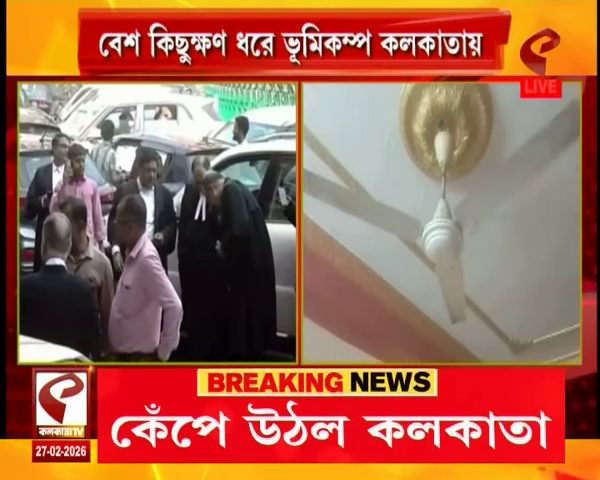

In [93]:
import subprocess
from pathlib import Path
from PIL import Image, ImageStat
from IPython.display import display

FFMPEG = "/usr/bin/ffmpeg"
K = 8  # planned frames per video
OUT_ROOT = Path("/content/BTMD_work/frames_test")
OUT_ROOT.mkdir(parents=True, exist_ok=True)

test_ids = [
    "76a287aa-5205-468a-81da-ec47031951f1",  # AV1 video (OpenCV failed earlier)
    "81e8861f-734b-4c24-8d12-cdd887f99514",  # longest h264 video (300 s)
]

video_lookup = check_df.set_index("id")["video_file"]
duration_lookup = probe_df.set_index("id")["duration_sec"]

for vid in test_ids:
    src = video_lookup[vid]
    dur = float(duration_lookup[vid])
    out_dir = OUT_ROOT / vid
    out_dir.mkdir(parents=True, exist_ok=True)
    print(f"\n{vid}: duration = {dur:.2f} s, frames = {K}")

    # 1. Extract K frames at evenly spaced timestamps
    for i in range(K):
        t = dur * (i + 0.5) / K
        out_png = out_dir / f"frame_{i:02d}.png"
        cmd = [FFMPEG, "-y", "-v", "error",
               "-ss", f"{t:.3f}", "-i", src,
               "-frames:v", "1", str(out_png)]
        res = subprocess.run(cmd, capture_output=True, text=True)
        if res.returncode != 0 or not out_png.exists():
            raise RuntimeError(f"FFmpeg failed for {vid} at t={t:.2f}s: {res.stderr}")

    # 2. Verify each frame and check brightness (near 0 = black frame)
    sizes, brightness = [], []
    for i in range(K):
        p = out_dir / f"frame_{i:02d}.png"
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            im = im.convert("RGB")
            sizes.append(im.size)
            brightness.append(round(sum(ImageStat.Stat(im).mean) / 3, 1))

    print("  frames saved:", len(list(out_dir.glob("frame_*.png"))))
    print("  frame sizes :", sorted(set(sizes)))
    print("  brightness  :", brightness)

# 3. Show the middle frame of the AV1 video to confirm it is not blank
av1_mid = OUT_ROOT / test_ids[0] / "frame_04.png"
display(Image.open(av1_mid))

In [94]:
import subprocess
from pathlib import Path
import pandas as pd
from PIL import Image, ImageStat

FFMPEG = "/usr/bin/ffmpeg"
K = 8  # frames per video
OUT_ROOT = Path("/content/BTMD_work/frames")
OUT_ROOT.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = Path("/content/BTMD_work/frame_manifest.csv")

# 0. Build one table with split and duration for all 79 samples
all_inputs = pd.concat([
    train_inputs.assign(data_split="train"),
    test_inputs.assign(data_split="test"),
])
all_inputs = all_inputs.merge(probe_df[["id", "duration_sec"]], on="id", how="left")

assert len(all_inputs) == 79, f"Expected 79 samples, got {len(all_inputs)}"
assert all_inputs["id"].is_unique, "Duplicate sample ids found"
assert all_inputs["duration_sec"].notna().all(), "Missing duration for some samples"

# 1. Extract frames, verify each one, and collect manifest rows
rows = []
for _, r in all_inputs.iterrows():
    vid = r["id"]
    dur = float(r["duration_sec"])
    out_dir = OUT_ROOT / vid
    out_dir.mkdir(parents=True, exist_ok=True)

    for i in range(K):
        t = dur * (i + 0.5) / K
        out_png = out_dir / f"frame_{i:02d}.png"

        if not out_png.exists():
            cmd = [FFMPEG, "-y", "-v", "error",
                   "-ss", f"{t:.3f}", "-i", r["video_file"],
                   "-frames:v", "1", str(out_png)]
            res = subprocess.run(cmd, capture_output=True, text=True)
            if res.returncode != 0 or not out_png.exists():
                raise RuntimeError(
                    f"FFmpeg failed for {vid} frame {i} at t={t:.2f}s: {res.stderr}"
                )

        with Image.open(out_png) as im:
            im.verify()
        with Image.open(out_png) as im:
            im = im.convert("RGB")
            w, h = im.size
            brightness = round(sum(ImageStat.Stat(im).mean) / 3, 1)

        rows.append({
            "id": vid,
            "label": r["label"],
            "data_split": r["data_split"],
            "frame_index": i,
            "timestamp_sec": round(t, 3),
            "frame_path": str(out_png),
            "width": w,
            "height": h,
            "brightness": brightness,
        })

# 2. Save manifest and print summary
manifest = pd.DataFrame(rows)
manifest.to_csv(MANIFEST_PATH, index=False)

print("Videos processed:", manifest["id"].nunique())
print("Total frames:", len(manifest), f"(expected {79 * K})")
print("Frames per split:", manifest.groupby("data_split").size().to_dict())
print("\nFrame sizes:")
print(manifest.groupby(["width", "height"]).size().to_string())
print("\nVery dark frames (brightness < 10):", int((manifest["brightness"] < 10).sum()))
print("Manifest saved to:", MANIFEST_PATH)

Videos processed: 79
Total frames: 632 (expected 632)
Frames per split: {'test': 128, 'train': 504}

Frame sizes:
width  height
600    480         8
640    360        16
720    720         8
956    720        16
1080   1920       32
1280   720       176
1920   1080      376

Very dark frames (brightness < 10): 5
Manifest saved to: /content/BTMD_work/frame_manifest.csv


In [95]:
import pandas as pd

MANIFEST_PATH = "/content/BTMD_work/frame_manifest.csv"
manifest = pd.read_csv(MANIFEST_PATH)

DARK_THRESHOLD = 10
dark = manifest[manifest["brightness"] < DARK_THRESHOLD]

print("Total dark frames:", len(dark))
display(dark[["id", "label", "data_split", "frame_index", "timestamp_sec", "brightness"]])

affected_ids = dark["id"].unique()
print("\nVideos with at least one dark frame:", len(affected_ids))

for vid in affected_ids:
    sub = manifest[manifest["id"] == vid].sort_values("frame_index")
    label = sub["label"].iloc[0]
    split = sub["data_split"].iloc[0]
    dark_idx = sub.loc[sub["brightness"] < DARK_THRESHOLD, "frame_index"].tolist()

    print(f"\n{vid} | label={label} | split={split}")
    print("  brightness by frame:", sub["brightness"].tolist())
    print("  dark frame indices :", dark_idx)

print("\nDark frames per split:", dark.groupby("data_split").size().to_dict())
print("Dark frames per label:", dark.groupby("label").size().to_dict())

Total dark frames: 5


,id,label,data_split,frame_index,timestamp_sec,brightness
45,898ad02d-82d0-4d34-8c57-2dd2808f7d8d,Fake,train,5,194.288,9.4
175,8cba05d8-d278-48c5-8de4-be5968d649f3,Fake,train,7,78.063,3.2
257,38b960c6-3219-4c94-8507-575a8c402455,Fake,train,1,28.447,4.3
263,38b960c6-3219-4c94-8507-575a8c402455,Fake,train,7,142.236,6.0
538,fecfdd2e-4e0d-40f0-9357-caa4b24ac2a0,Fake,test,2,68.917,8.4



Videos with at least one dark frame: 4

898ad02d-82d0-4d34-8c57-2dd2808f7d8d | label=Fake | split=train
  brightness by frame: [189.4, 158.3, 125.5, 180.9, 147.8, 9.4, 146.1, 178.1]
  dark frame indices : [5]

8cba05d8-d278-48c5-8de4-be5968d649f3 | label=Fake | split=train
  brightness by frame: [47.7, 12.5, 18.9, 46.4, 66.5, 74.3, 32.2, 3.2]
  dark frame indices : [7]

38b960c6-3219-4c94-8507-575a8c402455 | label=Fake | split=train
  brightness by frame: [20.0, 4.3, 55.4, 11.7, 82.8, 11.2, 83.0, 6.0]
  dark frame indices : [1, 7]

fecfdd2e-4e0d-40f0-9357-caa4b24ac2a0 | label=Fake | split=test
  brightness by frame: [90.8, 88.0, 8.4, 57.4, 72.5, 28.6, 68.5, 40.1]
  dark frame indices : [2]

Dark frames per split: {'test': 1, 'train': 4}
Dark frames per label: {'Fake': 5}


In [96]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageOps

IMG_SIZE = 224
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_image(path):
    im = Image.open(path).convert("RGB")
    # Letterbox: keep aspect ratio, pad with black to a square
    im = ImageOps.pad(im, (IMG_SIZE, IMG_SIZE), color=(0, 0, 0))
    arr = np.asarray(im, dtype=np.float32) / 255.0   # range 0 to 1
    return (arr - MEAN) / STD                         # ImageNet normalization

manifest = pd.read_csv("/content/BTMD_work/frame_manifest.csv")

# One video frame per distinct frame size, plus 3 still images
video_frames = manifest.drop_duplicates(subset=["width", "height"])["frame_path"].tolist()
still_images = train_inputs["image_file"].head(3).tolist()

rows = []
for kind, paths in [("video_frame", video_frames), ("still_image", still_images)]:
    for p in paths:
        orig_w, orig_h = Image.open(p).size
        x = preprocess_image(p)
        rows.append({
            "kind": kind,
            "file": Path(p).name,
            "original_size": f"{orig_w}x{orig_h}",
            "output_shape": str(x.shape),
            "min": round(float(x.min()), 3),
            "max": round(float(x.max()), 3),
            "has_nan": bool(np.isnan(x).any()),
        })

summary = pd.DataFrame(rows)
display(summary)

# Checks
assert all(s == "(224, 224, 3)" for s in summary["output_shape"]), "Unexpected output shape"
assert not summary["has_nan"].any(), "NaN found after preprocessing"
print("Preprocessing dry run passed.")

,kind,file,original_size,output_shape,min,max,has_nan
0,video_frame,frame_00.png,640x360,"(224, 224, 3)",-2.118,2.64,False
1,video_frame,frame_00.png,1920x1080,"(224, 224, 3)",-2.118,2.64,False
2,video_frame,frame_00.png,1080x1920,"(224, 224, 3)",-2.118,2.64,False
3,video_frame,frame_00.png,1280x720,"(224, 224, 3)",-2.118,2.64,False
4,video_frame,frame_00.png,600x480,"(224, 224, 3)",-2.118,2.64,False
5,video_frame,frame_00.png,956x720,"(224, 224, 3)",-2.118,2.64,False
6,video_frame,frame_00.png,720x720,"(224, 224, 3)",-2.118,2.64,False
7,still_image,Fake_00859_1028df55-8fec-435c-8586-4d10ce263b5...,515x388,"(224, 224, 3)",-2.118,2.64,False
8,still_image,Fake_00182_3a8ae39d-2063-48b2-b315-cca8e688284...,1280x720,"(224, 224, 3)",-2.118,2.64,False
9,still_image,Fake_00765_f3396b7d-c918-4577-bb44-51fb784c0a4...,1280x720,"(224, 224, 3)",-2.118,2.64,False


Preprocessing dry run passed.


In [97]:
import importlib

packages = ["torch", "torchvision", "transformers", "sklearn", "PIL", "cv2"]

print("=== Library check ===")
for pkg in packages:
    try:
        mod = importlib.import_module(pkg)
        version = getattr(mod, "__version__", "unknown")
        print(f"{pkg:14s} OK      version = {version}")
    except ImportError as e:
        print(f"{pkg:14s} MISSING ({e})")

import torch

print("\n=== Device check ===")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device to use:", device)

=== Library check ===
torch          OK      version = 2.14.1+cpu
torchvision    OK      version = 0.29.1+cpu
transformers   OK      version = 5.22.1
sklearn        OK      version = 1.6.1
PIL            OK      version = 11.3.0
cv2            OK      version = 5.0.0

=== Device check ===
CUDA available: False
Device to use: cpu


In [98]:
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision.models import ResNet50_Weights
from PIL import Image, ImageOps

DEVICE = "cpu"
IMG_SIZE = 224
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# Same preprocessing as Step 47, but output in CHW order for PyTorch
def preprocess_image(path):
    im = Image.open(path).convert("RGB")
    im = ImageOps.pad(im, (IMG_SIZE, IMG_SIZE), color=(0, 0, 0))
    arr = np.asarray(im, dtype=np.float32) / 255.0
    arr = (arr - MEAN) / STD
    return arr.transpose(2, 0, 1)  # (224, 224, 3) -> (3, 224, 224)

# Load pretrained ResNet-50 and remove the final classifier
weights = ResNet50_Weights.IMAGENET1K_V2
image_encoder = torchvision.models.resnet50(weights=weights)
image_encoder.fc = torch.nn.Identity()  # output is now a 2048-d vector
image_encoder = image_encoder.to(DEVICE).eval()

# Dry run on 2 training images
sample_paths = train_inputs["image_file"].head(2).tolist()
batch = torch.tensor(
    np.stack([preprocess_image(p) for p in sample_paths]),
    dtype=torch.float32, device=DEVICE,
)

with torch.no_grad():
    feats = image_encoder(batch)

print("Input batch shape   :", tuple(batch.shape))
print("Output feature shape:", tuple(feats.shape))
print("Has NaN             :", bool(torch.isnan(feats).any()))
print("First sample mean / std:", round(feats[0].mean().item(), 4), round(feats[0].std().item(), 4))

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 42.2MB/s]


Input batch shape   : (2, 3, 224, 224)
Output feature shape: (2, 2048)
Has NaN             : False
First sample mean / std: 0.1237 0.2873


In [99]:
import torch
from transformers import AutoTokenizer, AutoModel

TEXT_MODEL = "sentence-transformers/LaBSE"
MAX_LEN = 128

tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)
text_encoder = AutoModel.from_pretrained(TEXT_MODEL).eval()

# 1. Tokenizer check on all 79 texts (no padding, so counts are exact)
all_texts = trimodal_model_df["combined_text"].tolist()
enc_all = tokenizer(all_texts, truncation=True, max_length=MAX_LEN)

total_tokens = sum(len(ids) for ids in enc_all["input_ids"])
unk_count = sum(ids.count(tokenizer.unk_token_id) for ids in enc_all["input_ids"])
truncated = sum(len(ids) == MAX_LEN for ids in enc_all["input_ids"])

print(f"Total tokens : {total_tokens}")
print(f"[UNK] tokens : {unk_count} ({100 * unk_count / total_tokens:.2f}%)")
print(f"Texts truncated at {MAX_LEN} tokens: {truncated}")

# 2. Dry run on 2 training texts
sample_texts = train_inputs["text_input"].head(2).tolist()
batch = tokenizer(sample_texts, truncation=True, max_length=MAX_LEN,
                  padding=True, return_tensors="pt")

with torch.no_grad():
    out = text_encoder(**batch)

feats = out.pooler_output  # pooled sentence vector (LaBSE uses this)
print("\nOutput feature shape:", tuple(feats.shape))
print("Has NaN             :", bool(torch.isnan(feats).any()))

config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/397 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/5.22M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.62M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.88GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Total tokens : 1623
[UNK] tokens : 1 (0.06%)
Texts truncated at 128 tokens: 1

Output feature shape: (2, 768)
Has NaN             : False


In [100]:
import numpy as np
import pandas as pd
import torch
import torchvision
from torchvision.models import ResNet50_Weights
from PIL import Image, ImageOps
from transformers import AutoTokenizer, AutoModel
from pathlib import Path

FEAT_DIR = Path("/content/BTMD_work/features")
FEAT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = "cpu"
IMG_SIZE = 224
MAX_LEN = 128
BATCH = 16
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess_image(path):
    im = Image.open(path).convert("RGB")
    im = ImageOps.pad(im, (IMG_SIZE, IMG_SIZE), color=(0, 0, 0))
    arr = np.asarray(im, dtype=np.float32) / 255.0
    return ((arr - MEAN) / STD).transpose(2, 0, 1)

# ---------- Models (pretrained, not trained further) ----------
weights = ResNet50_Weights.IMAGENET1K_V2
image_encoder = torchvision.models.resnet50(weights=weights)
image_encoder.fc = torch.nn.Identity()
image_encoder = image_encoder.to(DEVICE).eval()

tokenizer = AutoTokenizer.from_pretrained("sentence-transformers/LaBSE")
text_encoder = AutoModel.from_pretrained("sentence-transformers/LaBSE").eval()

# ---------- Sample table in split order ----------
meta = pd.concat([
    train_inputs.assign(data_split="train"),
    test_inputs.assign(data_split="test"),
])[["id", "label", "data_split", "text_input", "image_file", "video_file"]].reset_index(drop=True)
assert len(meta) == 79 and meta["id"].is_unique

manifest = pd.read_csv("/content/BTMD_work/frame_manifest.csv")
assert (manifest["id"].value_counts() == 8).all(), "Each video must have 8 frames"

# ---------- Helper: encode a list of image paths in batches ----------
def encode_images(paths):
    feats = []
    with torch.no_grad():
        for i in range(0, len(paths), BATCH):
            chunk = paths[i:i + BATCH]
            x = torch.tensor(np.stack([preprocess_image(p) for p in chunk]),
                             dtype=torch.float32, device=DEVICE)
            feats.append(image_encoder(x).cpu().numpy())
    return np.concatenate(feats, axis=0)

# ---------- 1. Image features (79, 2048) ----------
image_feats = encode_images(meta["image_file"].tolist())

# ---------- 2. Video features (79, 2048): mean of 8 frame features ----------
frame_feats = encode_images(manifest["frame_path"].tolist())   # (632, 2048)
video_feats = np.stack([
    frame_feats[(manifest["id"] == vid).values].mean(axis=0)
    for vid in meta["id"]
])

# ---------- 3. Text features (79, 768) ----------
texts = meta["text_input"].tolist()
text_chunks = []
with torch.no_grad():
    for i in range(0, len(texts), BATCH):
        b = tokenizer(texts[i:i + BATCH], truncation=True, max_length=MAX_LEN,
                      padding=True, return_tensors="pt")
        text_chunks.append(text_encoder(**b).pooler_output.cpu().numpy())
text_feats = np.concatenate(text_chunks, axis=0)

# ---------- 4. Checks ----------
for name, arr in [("image", image_feats), ("video", video_feats), ("text", text_feats)]:
    print(f"{name:6s} shape = {arr.shape}, has NaN = {bool(np.isnan(arr).any())}")

long_idx = meta.loc[meta["text_input"].str.len() > 500, ["id", "label", "data_split"]]
print("\nLongest text sample (likely the truncated one):")
print(long_idx.to_string(index=False))

# ---------- 5. Save ----------
np.save(FEAT_DIR / "image_feats.npy", image_feats)
np.save(FEAT_DIR / "video_feats.npy", video_feats)
np.save(FEAT_DIR / "text_feats.npy", text_feats)
meta.to_csv(FEAT_DIR / "feature_meta.csv", index=False)
print("\nSaved features to:", FEAT_DIR)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

image  shape = (79, 2048), has NaN = False
video  shape = (79, 2048), has NaN = False
text   shape = (79, 768), has NaN = False

Longest text sample (likely the truncated one):
                                  id label data_split
f3396b7d-c918-4577-bb44-51fb784c0a4c  Fake      train

Saved features to: /content/BTMD_work/features


In [101]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

FEAT_DIR = Path("/content/BTMD_work/features")
RESULT_DIR = Path("/content/BTMD_work/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 0. Load features and metadata (same order as feature_meta.csv)
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
text_feats = np.load(FEAT_DIR / "text_feats.npy")
assert text_feats.shape == (79, 768), f"Unexpected shape {text_feats.shape}"

train_mask = (meta["data_split"] == "train").values
test_mask = (meta["data_split"] == "test").values
assert train_mask.sum() == 63 and test_mask.sum() == 16

X_train = text_feats[train_mask]
y_train = meta.loc[train_mask, "label"].values
X_test = text_feats[test_mask]
y_test = meta.loc[test_mask, "label"].values

def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, class_weight="balanced",
                           max_iter=5000, random_state=42),
    )

# 1. Stratified 5-fold CV inside train only
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(make_model(), X_train, y_train,
                            cv=skf, scoring="f1_macro")
print("CV macro-F1 per fold:", np.round(cv_scores, 3))
print(f"CV macro-F1 mean +- std: {cv_scores.mean():.3f} +- {cv_scores.std():.3f}")

# 2. Fit on full train set, evaluate once on the shared test set
model = make_model().fit(X_train, y_train)
y_pred = model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
print(f"\nTest accuracy : {test_acc:.3f}")
print(f"Test macro-F1 : {test_f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted)")
print("Class order:", list(model.classes_))
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

# 3. Save results for later comparison
result = {
    "experiment": "text_only",
    "n_features": int(X_train.shape[1]),
    "C": 1.0,
    "cv_macro_f1_mean": float(cv_scores.mean()),
    "cv_macro_f1_std": float(cv_scores.std()),
    "test_accuracy": float(test_acc),
    "test_macro_f1": float(test_f1),
}
with open(RESULT_DIR / "text_only.json", "w") as f:
    json.dump(result, f, indent=2)
print("\nSaved:", RESULT_DIR / "text_only.json")

CV macro-F1 per fold: [0.838 0.606 0.819 0.829 0.829]
CV macro-F1 mean +- std: 0.784 +- 0.089

Test accuracy : 0.938
Test macro-F1 : 0.935

Classification report:
              precision    recall  f1-score   support

        Fake      1.000     0.900     0.947        10
        Real      0.857     1.000     0.923         6

    accuracy                          0.938        16
   macro avg      0.929     0.950     0.935        16
weighted avg      0.946     0.938     0.938        16

Confusion matrix (rows = true, cols = predicted)
Class order: ['Fake', 'Real']
[[9 1]
 [0 6]]

Saved: /content/BTMD_work/results/text_only.json


In [102]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

FEAT_DIR = Path("/content/BTMD_work/features")
RESULT_DIR = Path("/content/BTMD_work/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 0. Load image features and metadata (same order as feature_meta.csv)
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
image_feats = np.load(FEAT_DIR / "image_feats.npy")
assert image_feats.shape == (79, 2048), f"Unexpected shape {image_feats.shape}"

train_mask = (meta["data_split"] == "train").values
test_mask = (meta["data_split"] == "test").values
assert train_mask.sum() == 63 and test_mask.sum() == 16

X_train = image_feats[train_mask]
y_train = meta.loc[train_mask, "label"].values
X_test = image_feats[test_mask]
y_test = meta.loc[test_mask, "label"].values

def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, class_weight="balanced",
                           max_iter=5000, random_state=42),
    )

# 1. Stratified 5-fold CV inside train only
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(make_model(), X_train, y_train,
                            cv=skf, scoring="f1_macro")
print("CV macro-F1 per fold:", np.round(cv_scores, 3))
print(f"CV macro-F1 mean +- std: {cv_scores.mean():.3f} +- {cv_scores.std():.3f}")

# 2. Fit on full train set, evaluate once on the shared test set
model = make_model().fit(X_train, y_train)
y_pred = model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
print(f"\nTest accuracy : {test_acc:.3f}")
print(f"Test macro-F1 : {test_f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted)")
print("Class order:", list(model.classes_))
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

# 3. Save results
result = {
    "experiment": "image_only",
    "n_features": int(X_train.shape[1]),
    "C": 1.0,
    "cv_macro_f1_mean": float(cv_scores.mean()),
    "cv_macro_f1_std": float(cv_scores.std()),
    "test_accuracy": float(test_acc),
    "test_macro_f1": float(test_f1),
}
with open(RESULT_DIR / "image_only.json", "w") as f:
    json.dump(result, f, indent=2)
print("\nSaved:", RESULT_DIR / "image_only.json")

CV macro-F1 per fold: [0.511 0.675 0.838 0.486 0.556]
CV macro-F1 mean +- std: 0.613 +- 0.130

Test accuracy : 0.562
Test macro-F1 : 0.515

Classification report:
              precision    recall  f1-score   support

        Fake      0.636     0.700     0.667        10
        Real      0.400     0.333     0.364         6

    accuracy                          0.562        16
   macro avg      0.518     0.517     0.515        16
weighted avg      0.548     0.562     0.553        16

Confusion matrix (rows = true, cols = predicted)
Class order: ['Fake', 'Real']
[[7 3]
 [4 2]]

Saved: /content/BTMD_work/results/image_only.json


In [103]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

FEAT_DIR = Path("/content/BTMD_work/features")
RESULT_DIR = Path("/content/BTMD_work/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 0. Load video features and metadata (same order as feature_meta.csv)
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
video_feats = np.load(FEAT_DIR / "video_feats.npy")
assert video_feats.shape == (79, 2048), f"Unexpected shape {video_feats.shape}"

train_mask = (meta["data_split"] == "train").values
test_mask = (meta["data_split"] == "test").values
assert train_mask.sum() == 63 and test_mask.sum() == 16

X_train = video_feats[train_mask]
y_train = meta.loc[train_mask, "label"].values
X_test = video_feats[test_mask]
y_test = meta.loc[test_mask, "label"].values

def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, class_weight="balanced",
                           max_iter=5000, random_state=42),
    )

# 1. Stratified 5-fold CV inside train only
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(make_model(), X_train, y_train,
                            cv=skf, scoring="f1_macro")
print("CV macro-F1 per fold:", np.round(cv_scores, 3))
print(f"CV macro-F1 mean +- std: {cv_scores.mean():.3f} +- {cv_scores.std():.3f}")

# 2. Fit on full train set, evaluate once on the shared test set
model = make_model().fit(X_train, y_train)
y_pred = model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
print(f"\nTest accuracy : {test_acc:.3f}")
print(f"Test macro-F1 : {test_f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted)")
print("Class order:", list(model.classes_))
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

# 3. Save results
result = {
    "experiment": "video_only",
    "n_features": int(X_train.shape[1]),
    "C": 1.0,
    "cv_macro_f1_mean": float(cv_scores.mean()),
    "cv_macro_f1_std": float(cv_scores.std()),
    "test_accuracy": float(test_acc),
    "test_macro_f1": float(test_f1),
}
with open(RESULT_DIR / "video_only.json", "w") as f:
    json.dump(result, f, indent=2)
print("\nSaved:", RESULT_DIR / "video_only.json")

CV macro-F1 per fold: [0.639 0.745 0.462 0.625 0.625]
CV macro-F1 mean +- std: 0.619 +- 0.091

Test accuracy : 0.812
Test macro-F1 : 0.806

Classification report:
              precision    recall  f1-score   support

        Fake      0.889     0.800     0.842        10
        Real      0.714     0.833     0.769         6

    accuracy                          0.812        16
   macro avg      0.802     0.817     0.806        16
weighted avg      0.823     0.812     0.815        16

Confusion matrix (rows = true, cols = predicted)
Class order: ['Fake', 'Real']
[[8 2]
 [1 5]]

Saved: /content/BTMD_work/results/video_only.json


In [104]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix)

FEAT_DIR = Path("/content/BTMD_work/features")
RESULT_DIR = Path("/content/BTMD_work/results")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# 0. Load all three feature sets and metadata (same row order)
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
text_feats = np.load(FEAT_DIR / "text_feats.npy")     # (79, 768)
image_feats = np.load(FEAT_DIR / "image_feats.npy")   # (79, 2048)
video_feats = np.load(FEAT_DIR / "video_feats.npy")   # (79, 2048)

assert text_feats.shape[0] == image_feats.shape[0] == video_feats.shape[0] == 79

# Early fusion: join the three modalities side by side
trimodal_feats = np.concatenate([text_feats, image_feats, video_feats], axis=1)
assert trimodal_feats.shape == (79, 4864), f"Unexpected shape {trimodal_feats.shape}"

train_mask = (meta["data_split"] == "train").values
test_mask = (meta["data_split"] == "test").values
assert train_mask.sum() == 63 and test_mask.sum() == 16

X_train = trimodal_feats[train_mask]
y_train = meta.loc[train_mask, "label"].values
X_test = trimodal_feats[test_mask]
y_test = meta.loc[test_mask, "label"].values

def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, class_weight="balanced",
                           max_iter=5000, random_state=42),
    )

# 1. Stratified 5-fold CV inside train only
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(make_model(), X_train, y_train,
                            cv=skf, scoring="f1_macro")
print("CV macro-F1 per fold:", np.round(cv_scores, 3))
print(f"CV macro-F1 mean +- std: {cv_scores.mean():.3f} +- {cv_scores.std():.3f}")

# 2. Fit on full train set, evaluate once on the shared test set
model = make_model().fit(X_train, y_train)
y_pred = model.predict(X_test)

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
print(f"\nTest accuracy : {test_acc:.3f}")
print(f"Test macro-F1 : {test_f1:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3, zero_division=0))
print("Confusion matrix (rows = true, cols = predicted)")
print("Class order:", list(model.classes_))
print(confusion_matrix(y_test, y_pred, labels=model.classes_))

# 3. Save results
result = {
    "experiment": "trimodal",
    "n_features": int(X_train.shape[1]),
    "C": 1.0,
    "cv_macro_f1_mean": float(cv_scores.mean()),
    "cv_macro_f1_std": float(cv_scores.std()),
    "test_accuracy": float(test_acc),
    "test_macro_f1": float(test_f1),
}
with open(RESULT_DIR / "trimodal.json", "w") as f:
    json.dump(result, f, indent=2)
print("\nSaved:", RESULT_DIR / "trimodal.json")

CV macro-F1 per fold: [0.819 0.915 0.69  0.58  0.812]
CV macro-F1 mean +- std: 0.764 +- 0.116

Test accuracy : 0.875
Test macro-F1 : 0.867

Classification report:
              precision    recall  f1-score   support

        Fake      0.900     0.900     0.900        10
        Real      0.833     0.833     0.833         6

    accuracy                          0.875        16
   macro avg      0.867     0.867     0.867        16
weighted avg      0.875     0.875     0.875        16

Confusion matrix (rows = true, cols = predicted)
Class order: ['Fake', 'Real']
[[9 1]
 [1 5]]

Saved: /content/BTMD_work/results/trimodal.json


In [105]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score

FEAT_DIR = Path("/content/BTMD_work/features")
RESULT_DIR = Path("/content/BTMD_work/results")

meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
train_mask = (meta["data_split"] == "train").values
test_mask = (meta["data_split"] == "test").values
y_train = meta.loc[train_mask, "label"].values
y_test = meta.loc[test_mask, "label"].values

# 1. Majority-class baseline (always predicts the most common class in train)
X_dummy = np.zeros((79, 1))  # features are not used by this baseline
baseline = DummyClassifier(strategy="most_frequent")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_base = cross_val_score(baseline, X_dummy[train_mask], y_train,
                          cv=skf, scoring="f1_macro")

baseline.fit(X_dummy[train_mask], y_train)
pred_base = baseline.predict(X_dummy[test_mask])

rows = [{
    "experiment": "majority_baseline",
    "n_features": 0,
    "cv_macro_f1_mean": cv_base.mean(),
    "cv_macro_f1_std": cv_base.std(),
    "test_accuracy": accuracy_score(y_test, pred_base),
    "test_macro_f1": f1_score(y_test, pred_base, average="macro"),
}]

# 2. Load the four saved experiment results
for name in ["text_only", "image_only", "video_only", "trimodal"]:
    with open(RESULT_DIR / f"{name}.json") as f:
        r = json.load(f)
    rows.append({
        "experiment": r["experiment"],
        "n_features": r["n_features"],
        "cv_macro_f1_mean": r["cv_macro_f1_mean"],
        "cv_macro_f1_std": r["cv_macro_f1_std"],
        "test_accuracy": r["test_accuracy"],
        "test_macro_f1": r["test_macro_f1"],
    })

# 3. Comparison table, sorted by CV macro-F1
table = pd.DataFrame(rows).sort_values("cv_macro_f1_mean", ascending=False)
display(table.round(3).reset_index(drop=True))

table.to_csv(RESULT_DIR / "comparison_table.csv", index=False)
print("Saved:", RESULT_DIR / "comparison_table.csv")
print("Test set class counts (Fake, Real):",
      (y_test == "Fake").sum(), (y_test == "Real").sum())

,experiment,n_features,cv_macro_f1_mean,cv_macro_f1_std,test_accuracy,test_macro_f1
0,text_only,768,0.784,0.089,0.938,0.935
1,trimodal,4864,0.764,0.116,0.875,0.867
2,video_only,2048,0.619,0.091,0.812,0.806
3,image_only,2048,0.613,0.130,0.562,0.515
4,majority_baseline,0,0.389,0.009,0.625,0.385


Saved: /content/BTMD_work/results/comparison_table.csv
Test set class counts (Fake, Real): 10 6


In [106]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

FEAT_DIR = Path("/content/BTMD_work/features")
RESULT_DIR = Path("/content/BTMD_work/results")

# 0. Load features and training labels
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
text_feats = np.load(FEAT_DIR / "text_feats.npy")
image_feats = np.load(FEAT_DIR / "image_feats.npy")
video_feats = np.load(FEAT_DIR / "video_feats.npy")

train_mask = (meta["data_split"] == "train").values
assert train_mask.sum() == 63
y_train = meta.loc[train_mask, "label"].values

feature_sets = {
    "text_only": text_feats,
    "image_only": image_feats,
    "video_only": video_feats,
    "trimodal": np.concatenate([text_feats, image_feats, video_feats], axis=1),
}

def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(C=1.0, class_weight="balanced",
                           max_iter=5000, random_state=42),
    )

# 1. Repeated stratified 5-fold CV: 5 folds x 10 repeats = 50 scores per experiment
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

scores = {}
for name, feats in feature_sets.items():
    X_train = feats[train_mask]
    s = cross_val_score(make_model(), X_train, y_train,
                        cv=rskf, scoring="f1_macro")
    scores[name] = s
    print(f"{name:12s} mean = {s.mean():.3f}  std = {s.std():.3f}  "
          f"min = {s.min():.3f}  max = {s.max():.3f}")

# 2. Paired comparison: same 50 folds for both experiments
def paired_summary(a, b):
    diff = scores[a] - scores[b]
    print(f"{a} - {b}: mean diff = {diff.mean():+.3f}, std = {diff.std():.3f}, "
          f"{a} higher in {(diff > 0).mean() * 100:.0f}% of folds")

print()
paired_summary("text_only", "trimodal")
paired_summary("text_only", "video_only")
paired_summary("video_only", "image_only")
paired_summary("trimodal", "video_only")

# 3. Save all 50 scores per experiment
pd.DataFrame(scores).to_csv(RESULT_DIR / "repeated_cv_scores.csv", index=False)
print("\nSaved:", RESULT_DIR / "repeated_cv_scores.csv")

text_only    mean = 0.796  std = 0.089  min = 0.556  max = 0.921
image_only   mean = 0.609  std = 0.152  min = 0.200  max = 0.921
video_only   mean = 0.649  std = 0.112  min = 0.378  max = 0.915
trimodal     mean = 0.763  std = 0.134  min = 0.314  max = 1.000

text_only - trimodal: mean diff = +0.033, std = 0.154, text_only higher in 48% of folds
text_only - video_only: mean diff = +0.147, std = 0.128, text_only higher in 86% of folds
video_only - image_only: mean diff = +0.040, std = 0.174, video_only higher in 60% of folds
trimodal - video_only: mean diff = +0.114, std = 0.129, trimodal higher in 80% of folds

Saved: /content/BTMD_work/results/repeated_cv_scores.csv


In [107]:
import json
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score

FEAT_DIR = Path("/content/BTMD_work/features")
RESULT_DIR = Path("/content/BTMD_work/results")

# 0. Load text and labels
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
train_mask = (meta["data_split"] == "train").values
test_mask = (meta["data_split"] == "test").values
texts = meta["text_input"].values
labels = meta["label"].values

def make_tfidf_model():
    return make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4),
                        min_df=2, sublinear_tf=True),
        LogisticRegression(C=1.0, class_weight="balanced",
                           max_iter=5000, random_state=42),
    )

# 1. Same 50 repeated folds as Step 57
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
tfidf_scores = cross_val_score(make_tfidf_model(),
                               texts[train_mask], labels[train_mask],
                               cv=rskf, scoring="f1_macro")
print(f"TF-IDF   mean = {tfidf_scores.mean():.3f}  std = {tfidf_scores.std():.3f}  "
      f"min = {tfidf_scores.min():.3f}  max = {tfidf_scores.max():.3f}")

# 2. Paired comparison with LaBSE text-only (same folds)
labse_scores = pd.read_csv(RESULT_DIR / "repeated_cv_scores.csv")["text_only"].values
diff = labse_scores - tfidf_scores
print(f"\nLaBSE - TF-IDF: mean diff = {diff.mean():+.3f}, std = {diff.std():.3f}, "
      f"LaBSE higher in {(diff > 0).mean() * 100:.0f}% of folds")

# 3. Shared test set, evaluated once
model = make_tfidf_model().fit(texts[train_mask], labels[train_mask])
y_test = labels[test_mask]
pred = model.predict(texts[test_mask])
test_acc = accuracy_score(y_test, pred)
test_f1 = f1_score(y_test, pred, average="macro")
print(f"\nTest accuracy : {test_acc:.3f}")
print(f"Test macro-F1 : {test_f1:.3f}")

# 4. Save
pd.DataFrame({"tfidf_text": tfidf_scores}).to_csv(
    RESULT_DIR / "repeated_cv_tfidf.csv", index=False)
with open(RESULT_DIR / "tfidf_text.json", "w") as f:
    json.dump({
        "experiment": "tfidf_text",
        "cv_macro_f1_mean": float(tfidf_scores.mean()),
        "cv_macro_f1_std": float(tfidf_scores.std()),
        "test_accuracy": float(test_acc),
        "test_macro_f1": float(test_f1),
    }, f, indent=2)
print("\nSaved TF-IDF results to:", RESULT_DIR)

TF-IDF   mean = 0.816  std = 0.096  min = 0.621  max = 1.000

LaBSE - TF-IDF: mean diff = -0.020, std = 0.105, LaBSE higher in 38% of folds

Test accuracy : 0.688
Test macro-F1 : 0.654

Saved TF-IDF results to: /content/BTMD_work/results


In [108]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

FEAT_DIR = Path("/content/BTMD_work/features")

# 0. Training texts and labels only (this is for inspection, not evaluation)
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
train_mask = (meta["data_split"] == "train").values
texts = meta["text_input"].values[train_mask]
labels = meta["label"].values[train_mask]

# Split on whitespace and common punctuation (\u0964 = Bangla full stop)
TOKEN_PATTERN = r"[^\s\u0964,.!?\"'\u201c\u201d\u2018\u2019:;()\-]+"

# 1. Word-level TF-IDF and logistic regression
vec = TfidfVectorizer(analyzer="word", token_pattern=TOKEN_PATTERN,
                      min_df=2, sublinear_tf=True)
X = vec.fit_transform(texts)
clf = LogisticRegression(C=1.0, class_weight="balanced",
                         max_iter=5000, random_state=42).fit(X, labels)

# 2. Coefficients: positive = pushes toward classes_[1], negative = toward classes_[0]
vocab = np.array(vec.get_feature_names_out())
coef = clf.coef_[0]
print("Class order:", list(clf.classes_))
print("Vocabulary size:", len(vocab))

order = np.argsort(coef)
print(f"\nTop 15 words pushing toward {clf.classes_[1]}:")
for i in order[::-1][:15]:
    print(f"  {vocab[i]:25s} {coef[i]:+.3f}")

print(f"\nTop 15 words pushing toward {clf.classes_[0]}:")
for i in order[:15]:
    print(f"  {vocab[i]:25s} {coef[i]:+.3f}")

Class order: ['Fake', 'Real']
Vocabulary size: 105

Top 15 words pushing toward Real:
  নিধন                      +0.870
  পরিবেশবান্ধব              +0.742
  বৃক্ষ                     +0.622
  |                         +0.606
  নদ                        +0.570
  ধ্বংসস্তূপে               +0.503
  শক্তি                     +0.491
  তিস্তা                    +0.484
  বেশি                      +0.483
  কী                        +0.483
  নিয়ে                     +0.479
  আতঙ্কে                    +0.454
  মানুষ                     +0.435
  ভেনেজুয়েলা                +0.419
  নামে                      +0.405

Top 15 words pushing toward Fake:
  এই                        -0.622
  ধ্বংস                     -0.495
  না                        -0.476
  জানুন                     -0.475
  হয়ে                      -0.454
  এক                        -0.449
  গেল                       -0.416
  জানলে                     -0.413
  এবার                      -0.411
  মহাবিশ্বের                -0.408
  বি

In [109]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

FEAT_DIR = Path("/content/BTMD_work/features")

# 0. Training rows only (inspection, no test data)
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
tr = meta[meta["data_split"] == "train"].reset_index(drop=True)
texts = tr["text_input"].values
labels = tr["label"].values

# Same tokenizer and model as Step 59, so the top words match
TOKEN_PATTERN = r"[^\s\u0964,.!?\"'\u201c\u201d\u2018\u2019:;()\-]+"
vec = TfidfVectorizer(analyzer="word", token_pattern=TOKEN_PATTERN,
                      min_df=2, sublinear_tf=True)
X = vec.fit_transform(texts)
clf = LogisticRegression(C=1.0, class_weight="balanced",
                         max_iter=5000, random_state=42).fit(X, labels)

vocab = np.array(vec.get_feature_names_out())
coef = clf.coef_[0]
order = np.argsort(coef)
top_real = vocab[order[::-1][:8]]   # pushes toward Real
top_fake = vocab[order[:8]]         # pushes toward Fake

# 1. Pipe character "|" by label
has_pipe = tr["text_input"].str.contains("|", regex=False)
print("Headings containing '|' (train only):")
print(pd.crosstab(tr["label"], has_pipe))

print("\nExamples containing '|':")
for _, r in tr[has_pipe].head(6).iterrows():
    print(f"  [{r['label']}] {r['text_input'][:90]}")

# 2. How often each top model word appears in each class
analyzer = vec.build_analyzer()
token_sets = [set(analyzer(t)) for t in texts]

rows = []
for word in list(top_fake) + list(top_real):
    present = np.array([word in s for s in token_sets])
    rows.append({
        "word": word,
        "pushes_toward": "Fake" if word in top_fake else "Real",
        "rate_in_Fake": round(present[labels == "Fake"].mean(), 2),
        "rate_in_Real": round(present[labels == "Real"].mean(), 2),
    })

print()
display(pd.DataFrame(rows))

Headings containing '|' (train only):
text_input  False  True 
label                   
Fake           35      5
Real           18      5

Examples containing '|':
  [Fake] আসছে আরও ভয়ংকর ভূমিকম্প! | এক ঝটকায় শহর ধ্বংস
  [Fake] ঘূর্ণিঝড়ে লণ্ডভণ্ড হয়ে গেল কলকাতা || একাধিক বাড়ির চাল উড়ে গেল ঝড়ে||
  [Fake] CCTV-তে ধরা পড়েছে ঘূর্ণিঝড় ইয়াসের কিছু ভিডিও | ঝড়ে উড়ে গেলো গরু ছাগল গাড়ি |
  [Fake] ব্ল্যাক হোল কি? | মহাবিশ্বের সবচেয়ে ভয়ংকর রহস্য 🔭
  [Fake] পৃথিবীর শেষ কবে? বিজ্ঞানীদের ভয়ংকর সতর্কবার্তা | পৃথিবী ধ্বংসের সম্ভাব্য ও কারণ
  [Real] ৩৯ সেকেন্ডের ব্যবধানে দুবার কাঁপল ভেনেজুয়েলা, ধ্বংসস্তূপে পরিণত |



,word,pushes_toward,rate_in_Fake,rate_in_Real
0,এই,Fake,0.10,0.00
1,ধ্বংস,Fake,0.12,0.00
2,না,Fake,0.12,0.00
3,জানুন,Fake,0.08,0.00
4,হয়ে,Fake,0.10,0.00
5,এক,Fake,0.10,0.00
6,গেল,Fake,0.08,0.00
7,জানলে,Fake,0.10,0.00
8,নিধন,Real,0.00,0.17
9,পরিবেশবান্ধব,Real,0.00,0.09


In [110]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

FEAT_DIR = Path("/content/BTMD_work/features")
meta = pd.read_csv(FEAT_DIR / "feature_meta.csv")
tr = meta[meta["data_split"] == "train"].reset_index(drop=True)
te = meta[meta["data_split"] == "test"].reset_index(drop=True)

# Fit the vectorizer on train only, then transform test
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4),
                      min_df=2, sublinear_tf=True)
X_tr = vec.fit_transform(tr["text_input"])
X_te = vec.transform(te["text_input"])

THRESHOLD = 0.5

# 1. Test headings vs nearest train heading
sim_te = cosine_similarity(X_te, X_tr)          # shape (16, 63)
best_idx = sim_te.argmax(axis=1)
best_sim = sim_te.max(axis=1)

res = pd.DataFrame({
    "id": te["id"].values,
    "true_label": te["label"].values,
    "nearest_train_label": tr["label"].values[best_idx],
    "similarity": best_sim.round(3),
})
print(f"Test headings with a train neighbour >= {THRESHOLD}: "
      f"{(best_sim >= THRESHOLD).sum()} of {len(te)}")
print("Nearest-neighbour label match rate (test):",
      round((res["true_label"] == res["nearest_train_label"]).mean(), 3))
display(res.sort_values("similarity", ascending=False).head(8))

# 2. Train headings vs other train headings (leave-one-out)
sim_tr = cosine_similarity(X_tr)
np.fill_diagonal(sim_tr, -1)
nn_tr = sim_tr.argmax(axis=1)
nn_tr_sim = sim_tr.max(axis=1)
print(f"\nTrain headings with another train neighbour >= {THRESHOLD}: "
      f"{(nn_tr_sim >= THRESHOLD).sum()} of {len(tr)}")
print("Leave-one-out 1-NN label match rate (train):",
      round((tr["label"].values == tr["label"].values[nn_tr]).mean(), 3))

Test headings with a train neighbour >= 0.5: 1 of 16
Nearest-neighbour label match rate (test): 0.75


,id,true_label,nearest_train_label,similarity
12,c54b7dfb-ae82-4ed6-b6cb-788b918380be,Real,Real,0.651
15,f656afa6-2c6d-4556-a5d0-fd7e64309476,Fake,Fake,0.477
9,a2f51837-d252-464d-a8d9-87e1a330a114,Fake,Fake,0.400
7,9398588a-a090-4284-ac72-56c094892fcf,Real,Real,0.388
1,eec52624-9b0f-4afd-87d4-91a49ce2da79,Fake,Fake,0.386
3,464d21fc-50ed-4f60-99c9-ee5d256d28bf,Fake,Fake,0.378
0,679926b9-a5c2-4799-976e-cc9acbc298f0,Fake,Fake,0.362
2,f602a539-f462-4900-9725-1068614e8662,Fake,Fake,0.355



Train headings with another train neighbour >= 0.5: 4 of 63
Leave-one-out 1-NN label match rate (train): 0.905
